<div style='background-color: #1a1a2e; border: 3px solid #e94560; border-radius: 12px; padding: 20px; text-align: center;'>
    <font size="+3" color="#e94560"><b>🌿 Cotton Leaf Disease Detection 🌿</b></font><br>
    <font size="+1" color="#0f3460"><b>Multi-Model Comparison: ResNet50 | EfficientNet-B0 | MobileNetV3 | DenseNet121</b></font>
</div>
<div style='background-color: #f0fff0; border: 4px solid #32CD32; border-radius: 12px; padding: 10px; text-align: center; margin-top: 10px;'>
    <font size="+1" color="#32CD32"><b>📊 Systematic Evaluation of Lightweight CNN Architectures for Offline Crop Disease Diagnosis</b></font>
</div>

<div style='background-color: #e6f7ff; border: 3px solid #0078FF; border-radius: 10px; padding: 8px; text-align: center;'>
    <font size="+2" color="#0078FF"><b>🛠️ 1. Custom Datasets & DataLoaders 🛠️</b></font>
</div>

In [5]:
import os
import torch
import numpy as np
from glob import glob
from PIL import Image
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import transforms as T
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings("ignore")

torch.manual_seed(2025)

def find_dataset_root(candidate_root):
    """
    Checks if candidate_root exists and contains image files.
    If not, automatically searches /kaggle/input for the cotton leaf dataset directory.
    """
    valid_exts = ('.png', '.jpg', '.jpeg', '.bmp', '.JPG', '.JPEG', '.PNG')
    
    # 1. Check direct candidate path
    if os.path.exists(candidate_root):
        for root_dir, _, files in os.walk(candidate_root):
            if any(f.endswith(valid_exts) for f in files):
                return candidate_root
                
    # 2. Search dynamically in /kaggle/input
    kaggle_input = "/kaggle/input"
    if os.path.exists(kaggle_input):
        print(f"Candidate root not found. Auto-scanning '{kaggle_input}' for dataset...")
        # Check all immediate subfolders in kaggle input
        for sub in os.listdir(kaggle_input):
            sub_path = os.path.join(kaggle_input, sub)
            for root_dir, dirs, files in os.walk(sub_path):
                img_files = [f for f in files if f.endswith(valid_exts)]
                if len(img_files) > 10:
                    parent = os.path.dirname(root_dir)
                    print(f"Auto-detected dataset root at: {parent}")
                    return parent
                    
    return candidate_root

class CustomDataset(Dataset):
    def __init__(self, root, transformations=None, im_paths=None, im_lbls=None, im_files=[".png", ".jpg", ".jpeg", ".bmp", ".JPG", ".JPEG", ".PNG"]):
        
        self.transformations = transformations        
        if im_paths is not None and im_lbls is not None:
            self.im_paths = im_paths
            self.im_lbls = im_lbls        
        else:
            # Recursive scan to avoid depth/nesting issues
            valid_exts = tuple(im_files)
            found_paths = []
            for root_dir, _, files in os.walk(root):
                for file in files:
                    if file.endswith(valid_exts):
                        found_paths.append(os.path.normpath(os.path.join(root_dir, file)))
            
            self.im_paths = sorted(found_paths)
            
            if len(self.im_paths) == 0:
                available = os.listdir("/kaggle/input") if os.path.exists("/kaggle/input") else "None"
                raise ValueError(
                    f"No images found in root: '{root}'.\n"
                    f"Please check the dataset folder in Kaggle. Contents of /kaggle/input: {available}"
                )
            
            print(f"Discovered {len(self.im_paths)} images across categories.")
        
        self.cls_names, self.cls_counts = {}, {}
        count = 0
        for im_path in self.im_paths:
            class_name = self.get_class(im_path)
            if class_name not in self.cls_names:
                self.cls_names[class_name] = count
                self.cls_counts[class_name] = 1
                count += 1
            else:
                self.cls_counts[class_name] += 1        

    def get_class(self, path):
        # Platform-independent class extraction from parent folder
        return os.path.basename(os.path.dirname(os.path.normpath(path)))

    def __len__(self): return len(self.im_paths)

    def __getitem__(self, idx):
        im_path = self.im_paths[idx]
        im = Image.open(im_path).convert("RGB")        
        gt = self.im_lbls[idx]

        if self.transformations is not None:
            im = self.transformations(im)

        return im, gt

    @classmethod
    def stratified_split_dls(cls, root, transformations, bs=8, split=[0.8, 0.1, 0.1], ns=4):
        dataset = cls(root=root, transformations=transformations)
        
        im_paths = dataset.im_paths
        labels   = [dataset.cls_names[dataset.get_class(p)] for p in im_paths]        
        
        train_paths, temp_paths, train_lbls, temp_lbls = train_test_split(
            im_paths, labels, test_size=(split[1] + split[2]), stratify=labels, random_state=2025
        )

        # Second split: val and test
        val_ratio = split[1] / (split[1] + split[2])
        val_paths, test_paths, val_lbls, test_lbls = train_test_split(
            temp_paths, temp_lbls, test_size=(1 - val_ratio), stratify=temp_lbls, random_state=2025
        )

        train_ds = cls(root=root, transformations=transformations, im_paths = train_paths, im_lbls = train_lbls)
        val_ds = cls(root=root, transformations=transformations, im_paths = val_paths, im_lbls = val_lbls)
        test_ds = cls(root=root, transformations=transformations, im_paths = test_paths, im_lbls = test_lbls)
        
        train_dl = DataLoader(train_ds, batch_size=bs, shuffle=True, num_workers=ns)
        val_dl = DataLoader(val_ds, batch_size=bs, shuffle=False, num_workers=ns)
        test_dl = DataLoader(test_ds, batch_size=1, shuffle=False, num_workers=ns)

        return train_dl, val_dl, test_dl, dataset.cls_names, [train_ds.cls_counts, val_ds.cls_counts, test_ds.cls_counts]

# Auto-locate dataset path
default_root = "/kaggle/input/dataset-for-cotton-leaf-disease-detection/SAR-CLD-2024 A Comprehensive Dataset for Cotton Leaf Disease Detection/Original Dataset/Original Dataset"
root = find_dataset_root(default_root)
print(f"Using dataset root: {root}")

mean, std, im_size, bs = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225], 224, 16
tfs = T.Compose([T.Resize((im_size, im_size)), T.ToTensor(), T.Normalize(mean=mean, std=std)])

tr_dl, val_dl, ts_dl, classes, cls_counts = CustomDataset.stratified_split_dls(root=root, transformations=tfs, bs=bs)

print(f"Train batches: {len(tr_dl)} | Val batches: {len(val_dl)} | Test batches: {len(ts_dl)}")
print(f"Classes: {classes}")

Candidate root not found. Auto-scanning '/kaggle/input' for dataset...
Auto-detected dataset root at: /kaggle/input/datasets/sabuktagin/dataset-for-cotton-leaf-disease-detection/SAR-CLD-2024 A Comprehensive Dataset for Cotton Leaf Disease Detection/Original Dataset/Original Dataset
Using dataset root: /kaggle/input/datasets/sabuktagin/dataset-for-cotton-leaf-disease-detection/SAR-CLD-2024 A Comprehensive Dataset for Cotton Leaf Disease Detection/Original Dataset/Original Dataset
Discovered 2137 images across categories.
Train batches: 107 | Val batches: 14 | Test batches: 214
Classes: {'Bacterial Blight': 0, 'Curl Virus': 1, 'Healthy Leaf': 2, 'Herbicide Growth Damage': 3, 'Leaf Hopper Jassids': 4, 'Leaf Redding': 5, 'Leaf Variegation': 6}


<div style='background-color: #ffe6f2; border: 3px solid #ff1493; border-radius: 10px; padding: 8px; text-align: center;'>
    <font size="+2" color="#ff1493"><b>📊 2. Data Analysis 📊</b></font>
</div>

Data analysis is in process...

Data analysis is in process...

Data analysis is in process...



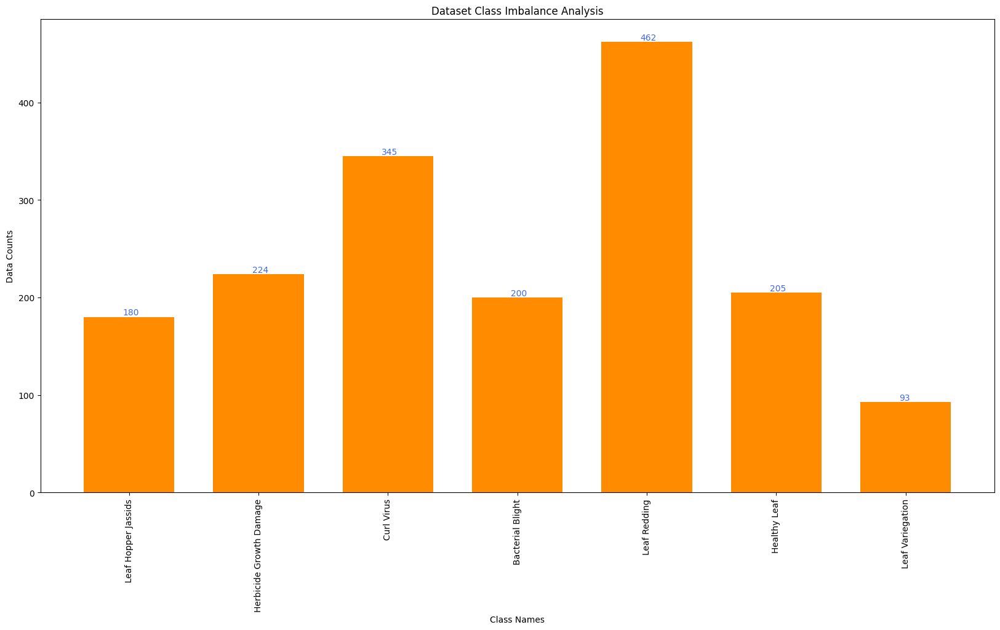

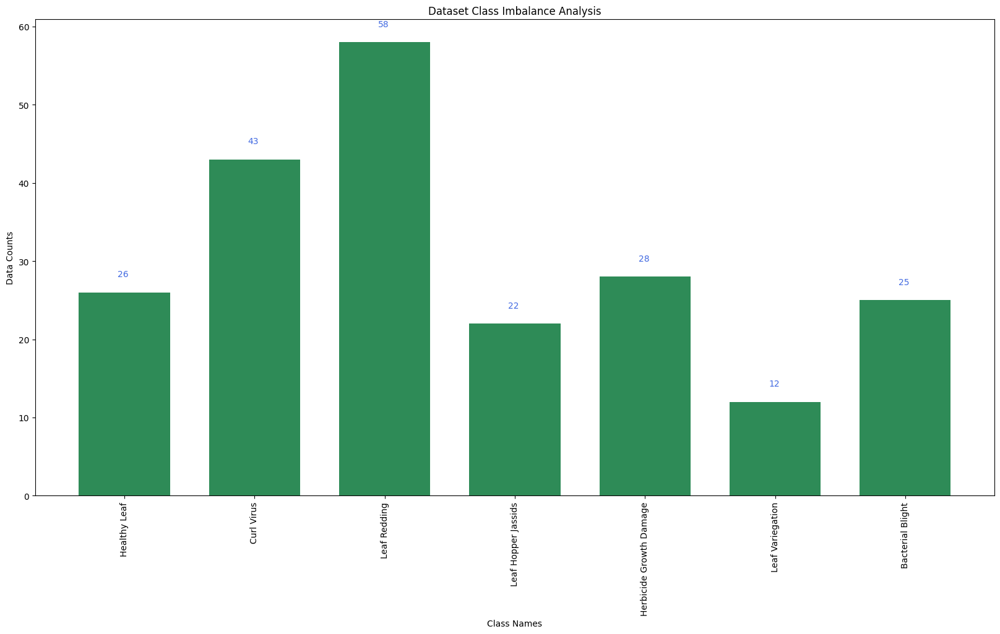

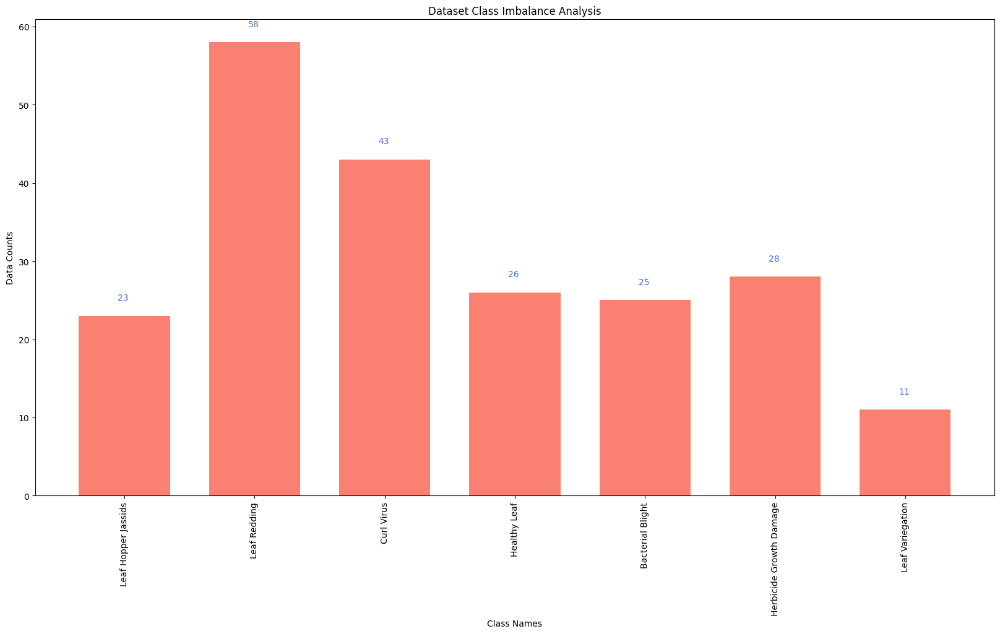

In [6]:
import numpy as np
from matplotlib import pyplot as plt
from torchvision import transforms as T

class Visualization:

    def __init__(self, vis_datas, n_ims, rows, cmap=None, cls_names=None, cls_counts=None, t_type="rgb"):
        self.n_ims, self.rows = n_ims, rows
        self.t_type, self.cmap = t_type, cmap
        self.cls_names = cls_names
        
        data_names = ["train", "val", "test"]
        self.colors = ["darkorange", "seagreen", "salmon"] 
        self.vis_datas = {data_names[i]: vis_datas[i] for i in range(len(vis_datas))}
        if isinstance(cls_counts, list): 
            self.analysis_datas = {data_names[i]: cls_counts[i] for i in range(len(cls_counts))}
        else: 
            self.analysis_datas = {"all": cls_counts}

    def tn2np(self, t):
        gray_tfs = T.Compose([T.Normalize(mean=[0.], std=[1/0.5]), T.Normalize(mean=[-0.5], std=[1])])
        rgb_tfs = T.Compose([T.Normalize(mean=[0., 0., 0.], std=[1/0.229, 1/0.224, 1/0.225]), 
                             T.Normalize(mean=[-0.485, -0.456, -0.406], std=[1., 1., 1.])])
        
        invTrans = gray_tfs if self.t_type == "gray" else rgb_tfs
        
        return (invTrans(t) * 255).detach().squeeze().cpu().permute(1, 2, 0).numpy().astype(np.uint8) if self.t_type == "gray" \
               else (invTrans(t) * 255).detach().cpu().permute(1, 2, 0).numpy().astype(np.uint8)

    def plot(self, rows, cols, count, im, title="Original Image"):
        plt.subplot(rows, cols, count)
        plt.imshow(self.tn2np(im))
        plt.axis("off")
        plt.title(title)
        return count + 1

    def vis(self, data, save_name):
        print(f"{save_name.upper()} Data Visualization is in process...\n")
        assert self.cmap in ["rgb", "gray"], "Please choose rgb or gray cmap"
        cmap = "viridis" if self.cmap == "rgb" else None
        cols = self.n_ims // self.rows
        count = 1

        plt.figure(figsize=(25, 20))
        indices = [np.random.randint(low=0, high=len(data) - 1) for _ in range(self.n_ims)]

        for idx, index in enumerate(indices):
            if count == self.n_ims + 1: break
            image, label = data[index]
            plt.subplot(self.rows, self.n_ims // self.rows, idx + 1)

            if cmap:
                plt.imshow(self.tn2np(image), cmap=cmap)
            else:
                plt.imshow(self.tn2np(image))

            plt.axis('off')
            if self.cls_names is not None:
                plt.title(f"GT -> {self.cls_names[int(label)]}")
            else:
                plt.title(f"GT -> {label}")
        
        plt.show()

    def data_analysis(self, cls_counts, save_name, color):
        print("Data analysis is in process...\n")
        width, text_width, text_height = 0.7, 0.05, 2
        cls_names = list(cls_counts.keys())
        counts = list(cls_counts.values())
        _, ax = plt.subplots(figsize=(20, 10))
        indices = np.arange(len(counts))
        ax.bar(indices, counts, width, color=color)
        ax.set_xlabel("Class Names", color="black")
        ax.set_xticklabels(cls_names, rotation = 90)
        ax.set(xticks=indices, xticklabels=cls_names)
        ax.set_ylabel("Data Counts", color="black")
        ax.set_title("Dataset Class Imbalance Analysis")
        for i, v in enumerate(counts):
            ax.text(i - text_width, v + text_height, str(v), color="royalblue")
    
    def plot_pie_chart(self, cls_counts):
        print("Generating pie chart...\n")
        labels = list(cls_counts.keys())
        sizes = list(cls_counts.values())
        explode = [0.1] * len(labels)  # To highlight all slices equally (optional)
        
        plt.figure(figsize=(8, 8))
        plt.pie(sizes, explode=explode, labels=labels, autopct='%1.1f%%', startangle=140, colors=plt.cm.tab20.colors)
        plt.title("Class Distribution")
        plt.axis("equal")  # Equal aspect ratio ensures the pie chart is circular
        plt.show()

    def visualization(self): [self.vis(data.dataset, save_name) for (save_name, data) in self.vis_datas.items()]
        
    def analysis(self): [self.data_analysis(data, save_name, color) for (save_name, data), color in zip(self.analysis_datas.items(), self.colors)]

    def pie_chart(self): [self.plot_pie_chart(data) for data in self.analysis_datas.values()]
        
vis = Visualization(vis_datas = [tr_dl, val_dl, ts_dl], n_ims = 20, rows = 4, cmap = "rgb", cls_names = list(classes.keys()), cls_counts = cls_counts)
vis.analysis()

Generating pie chart...



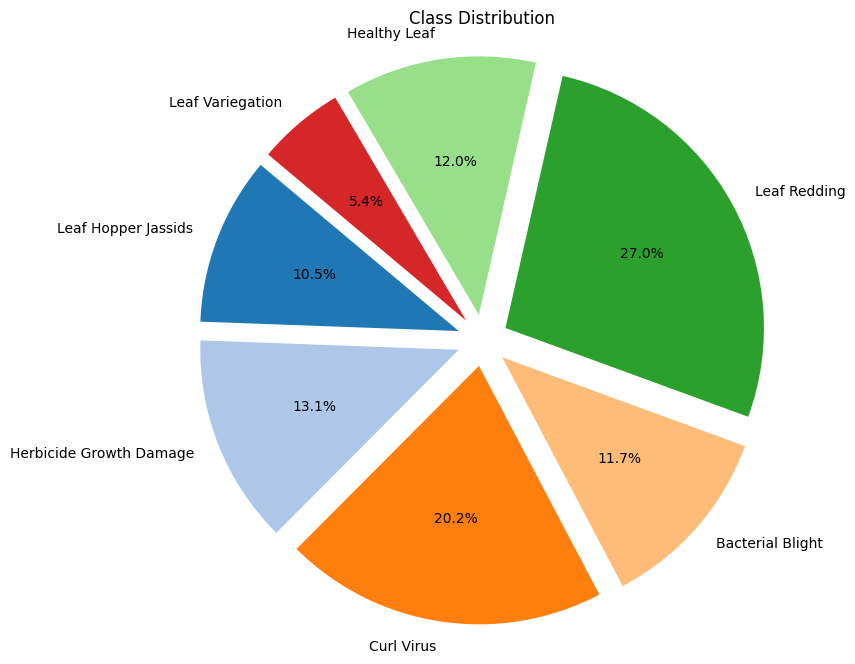

Generating pie chart...



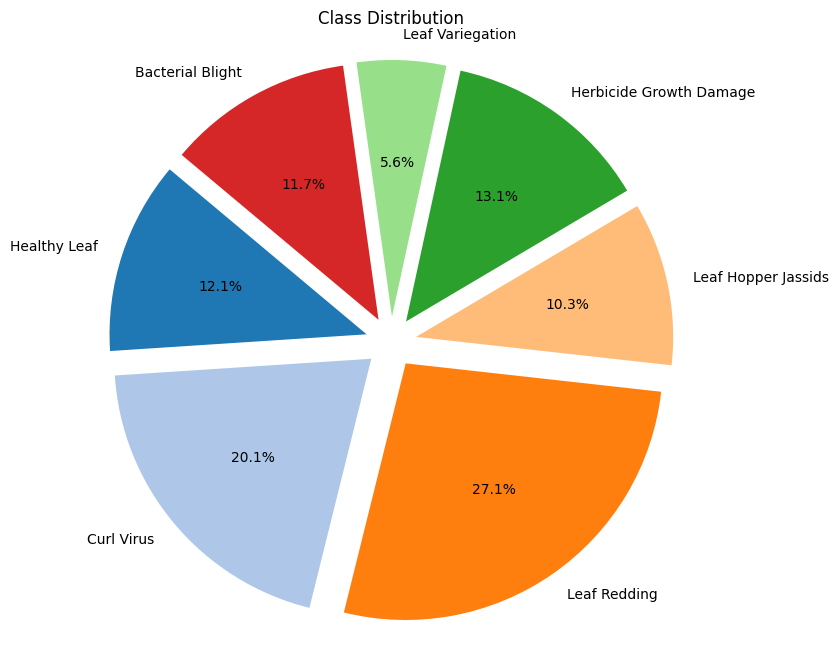

Generating pie chart...



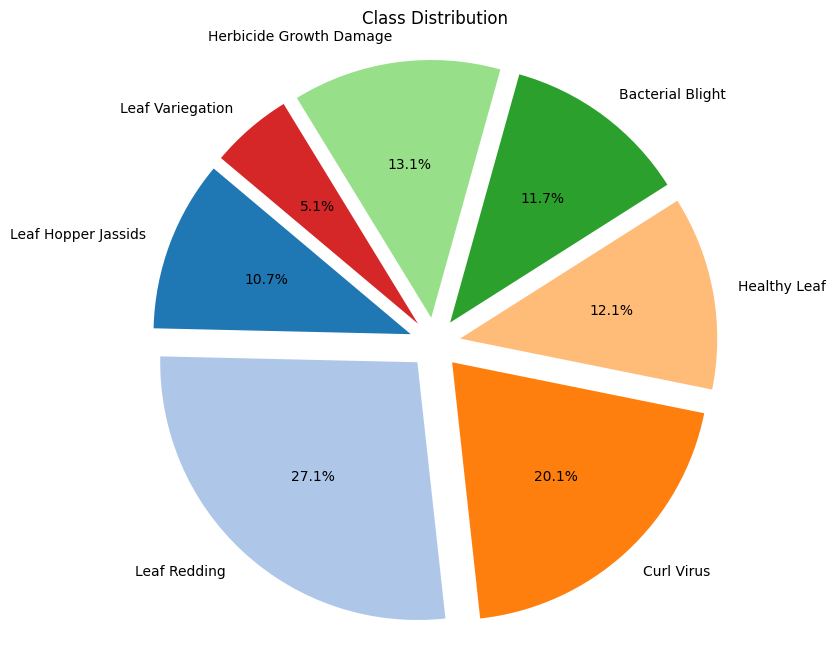

In [7]:
vis.pie_chart()

<div style='background-color: #e6f7ff; border: 3px solid #007acc; border-radius: 10px; padding: 8px; text-align: center;'>
    <font size="+2" color="#007acc"><b>📷 3. Data Visualization 📷</b></font>
</div>

TRAIN Data Visualization is in process...



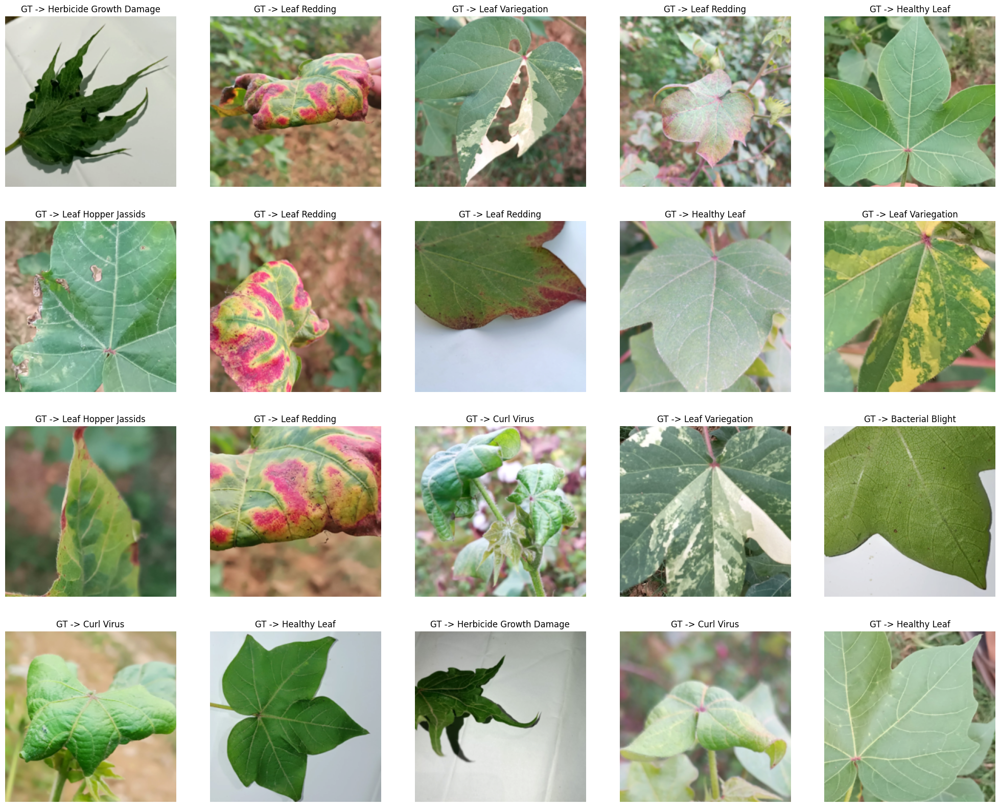

VAL Data Visualization is in process...



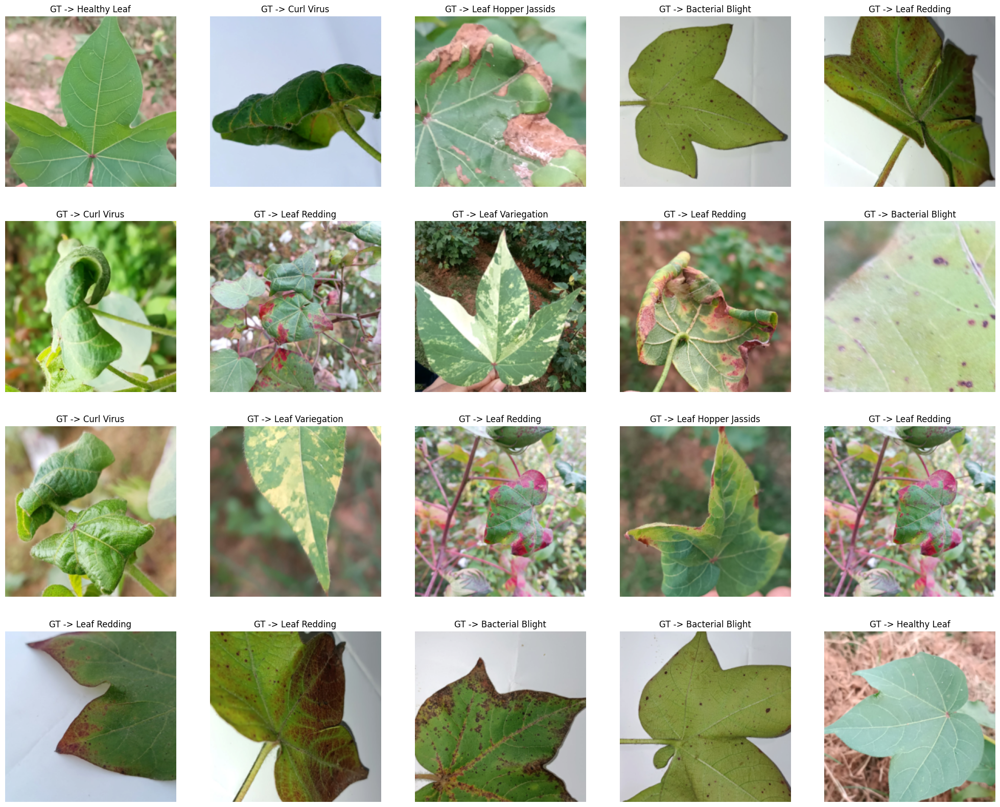

TEST Data Visualization is in process...



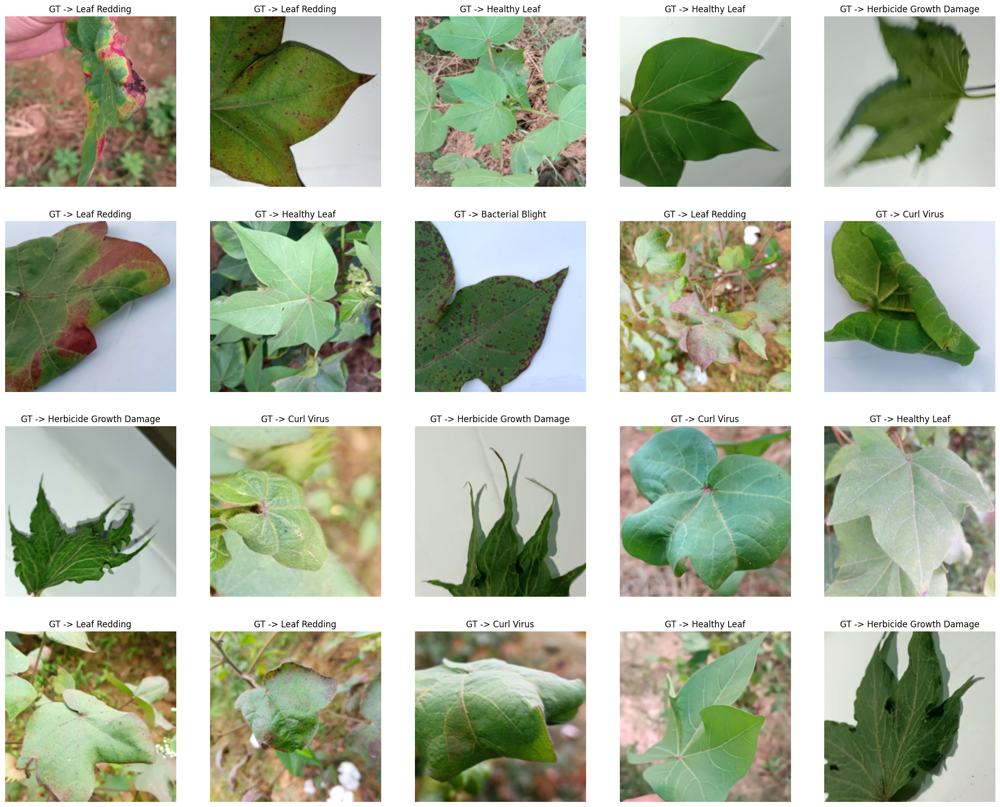

In [8]:
vis.visualization()

<div style='background-color: #f0f9e8; border: 3px solid #4CAF50; border-radius: 10px; padding: 8px; text-align: center;'>
    <font size="+2" color="#4CAF50"><b>⚙️ 4. Multi-Model Training & Validation ⚙️</b></font>
</div>

**Models being compared:**
| Model | Purpose | `timm` identifier |
| --- | --- | --- |
| ResNet50 | Strong baseline | `resnet50` |
| EfficientNet-B0 | Accuracy/efficiency balance | `efficientnet_b0` |
| MobileNetV3-Large | Mobile deployment | `mobilenetv3_large_100` |
| DenseNet121 | Strong classification | `densenet121` |

In [9]:
import os, torchmetrics, time
import timm
from tqdm import tqdm

class TrainValidation:
    def __init__(self, model_name, classes, tr_dl, val_dl, device, save_dir="saved_models", save_prefix="model", lr=3e-4, epochs=50, patience=5, threshold=0.01, dev_mode = False):
        self.model_name = model_name
        self.classes = classes
        self.tr_dl = tr_dl
        self.val_dl = val_dl
        self.save_dir = save_dir
        self.save_prefix = save_prefix
        self.lr = lr
        self.epochs = epochs
        self.patience = patience
        self.threshold = threshold
        self.dev_mode = dev_mode
        self.device = device
        self.model = timm.create_model(model_name, pretrained=True, num_classes=len(classes)).to(self.device)
        self.loss_fn = torch.nn.CrossEntropyLoss()
        self.optimizer = torch.optim.Adam(self.model.parameters(), lr=lr)
        self.f1_metric = torchmetrics.F1Score(task="multiclass", num_classes=len(classes)).to(self.device)

        os.makedirs(save_dir, exist_ok=True)

        self.best_loss = float("inf")
        self.best_acc = 0
        self.not_improved = 0

        self.tr_losses, self.val_losses = [], []
        self.tr_accs, self.val_accs = [], []
        self.tr_f1s, self.val_f1s = [], []
        
        # Count parameters
        self.num_params = sum(p.numel() for p in self.model.parameters())
        self.trainable_params = sum(p.numel() for p in self.model.parameters() if p.requires_grad)

    @staticmethod
    def to_device(batch, device):
        ims, gts = batch
        return ims.to(device), gts.to(device)

    def train_epoch(self):
        self.model.train()
        train_loss, train_acc = 0.0, 0.0
        self.f1_metric.reset()

        for idx, batch in tqdm(enumerate(self.tr_dl), desc="Training"):
            if self.dev_mode: 
                if idx == 1: break
            
            ims, gts = TrainValidation.to_device(batch = batch, device = self.device)
            
            # Forward pass
            preds = self.model(ims)
            loss = self.loss_fn(preds, gts)
            
            # Backward pass
            self.optimizer.zero_grad()
            loss.backward()
            self.optimizer.step()
            
            # Update metrics
            train_loss += loss.item() * gts.shape[0]
            train_acc += (torch.argmax(preds, dim=1) == gts).sum().item()
            self.f1_metric.update(preds, gts)

        train_loss /= len(self.tr_dl.dataset)
        train_acc /= len(self.tr_dl.dataset)
        train_f1 = self.f1_metric.compute().item()
        
        self.tr_losses.append(train_loss)
        self.tr_accs.append(train_acc)
        self.tr_f1s.append(train_f1)

        return train_loss, train_acc, train_f1

    def validate_epoch(self):
        self.model.eval()
        val_loss, val_acc = 0.0, 0.0
        self.f1_metric.reset()

        with torch.no_grad():
            for idx, batch in tqdm(enumerate(self.val_dl), desc="Validation"):
                if self.dev_mode: 
                    if idx == 1: break
                ims, gts = TrainValidation.to_device(batch, device = self.device)
                preds = self.model(ims)
                loss = self.loss_fn(preds, gts)

                # Update metrics
                val_loss += loss.item() * gts.shape[0]
                val_acc += (torch.argmax(preds, dim=1) == gts).sum().item()
                self.f1_metric.update(preds, gts)

        val_loss /= len(self.val_dl.dataset)
        val_acc /= len(self.val_dl.dataset)
        val_f1 = self.f1_metric.compute().item()

        self.val_losses.append(val_loss)
        self.val_accs.append(val_acc)
        self.val_f1s.append(val_f1)

        return val_loss, val_acc, val_f1

    def save_best_model(self, val_f1, val_loss):
        if val_f1 > self.best_acc + self.threshold:
            self.best_acc = val_f1            
            save_path = os.path.join(self.save_dir, f"{self.save_prefix}_best_model.pth")
            torch.save(self.model.state_dict(), save_path)
            print(f"Best model saved with F1-Score: {self.best_acc:.3f}")
            self.not_improved = 0
        else:
            self.not_improved += 1
            print(f"No improvement for {self.not_improved} epoch(s).")

    def verbose(self, epoch, metric1, metric2, metric3, process = "train"):
        print(f"{epoch + 1}-epoch {process} process is completed!\n")
        print(f"{epoch + 1}-epoch {process} loss          -> {metric1:.3f}")
        print(f"{epoch + 1}-epoch {process} accuracy      -> {metric2:.3f}")
        print(f"{epoch + 1}-epoch {process} f1-score      -> {metric3:.3f}\n")
    
    def run(self):
        print("Start training...")

        for epoch in range(self.epochs):
            if self.dev_mode: 
                if epoch == 1: break 
                    
            print(f"\nEpoch {epoch + 1}/{self.epochs}:\n")

            train_loss, train_acc, train_f1 = self.train_epoch()
            self.verbose(epoch, train_loss, train_acc, train_f1, process = "train")

            val_loss, val_acc, val_f1 = self.validate_epoch()
            self.verbose(epoch, val_loss, val_acc, val_f1, process = "validation")            

            self.save_best_model(val_f1, val_loss)

            if self.not_improved >= self.patience:
                print("Early stopping triggered.")
                break

In [10]:
# ============================================================================
# MODEL CONFIGURATIONS
# ============================================================================
MODEL_CONFIGS = {
    "ResNet50":           "resnet50",
    "EfficientNet-B0":    "efficientnet_b0",
    "MobileNetV3-Large":  "mobilenetv3_large_100",
    "DenseNet121":        "densenet121",
}

save_dir = "saved_models"
device   = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

# ============================================================================
# TRAIN ALL MODELS
# ============================================================================
all_results = {}

for display_name, timm_name in MODEL_CONFIGS.items():
    print(f"\n{'='*80}")
    print(f"  TRAINING: {display_name} ({timm_name})")
    print(f"{'='*80}\n")
    
    save_prefix = display_name.lower().replace("-", "_").replace(" ", "_")
    
    trainer = TrainValidation(
        model_name  = timm_name,
        device      = device,
        save_prefix = save_prefix,
        save_dir    = save_dir,
        classes     = classes,
        patience    = 3,
        tr_dl       = tr_dl,
        val_dl      = val_dl,
        dev_mode    = False
    )
    
    start_time = time.time()
    trainer.run()
    training_time = time.time() - start_time
    
    all_results[display_name] = {
        "timm_name":        timm_name,
        "save_prefix":      save_prefix,
        "trainer":          trainer,
        "tr_losses":        trainer.tr_losses,
        "val_losses":       trainer.val_losses,
        "tr_accs":          trainer.tr_accs,
        "val_accs":         trainer.val_accs,
        "tr_f1s":           trainer.tr_f1s,
        "val_f1s":          trainer.val_f1s,
        "best_val_f1":      trainer.best_acc,
        "best_val_acc":     max(trainer.val_accs) if trainer.val_accs else 0,
        "best_val_loss":    min(trainer.val_losses) if trainer.val_losses else float("inf"),
        "num_params":       trainer.num_params,
        "trainable_params": trainer.trainable_params,
        "training_time":    training_time,
        "epochs_trained":   len(trainer.tr_losses),
    }
    
    print(f"\n{display_name} -> Best Val F1: {trainer.best_acc:.4f} | "
          f"Params: {trainer.num_params/1e6:.2f}M | "
          f"Time: {training_time:.1f}s\n")

# ============================================================================
# SUMMARY TABLE
# ============================================================================
print("\n" + "="*100)
print(f"{'MODEL COMPARISON SUMMARY':^100}")
print("="*100)
print(f"{'Model':<22} {'Best Val Acc':>12} {'Best Val F1':>12} {'Best Val Loss':>14} {'Params (M)':>12} {'Time (min)':>12} {'Epochs':>8}")
print("-"*100)

for name, res in all_results.items():
    print(f"{name:<22} {res['best_val_acc']:>12.4f} {res['best_val_f1']:>12.4f} {res['best_val_loss']:>14.4f} {res['num_params']/1e6:>12.2f} {res['training_time']/60:>12.1f} {res['epochs_trained']:>8}")

print("-"*100)
best_model_name = max(all_results, key=lambda k: all_results[k]['best_val_f1'])
print(f"\n🏆 BEST MODEL: {best_model_name} (Val F1 = {all_results[best_model_name]['best_val_f1']:.4f})")

Using device: cuda

  TRAINING: ResNet50 (resnet50)



model.safetensors:   0%|          | 0.00/102M [00:00<?, ?B/s]

Start training...

Epoch 1/50:



Training: 107it [00:18,  5.77it/s]


1-epoch train process is completed!

1-epoch train loss          -> 1.360
1-epoch train accuracy      -> 0.527
1-epoch train f1-score      -> 0.527



Validation: 14it [00:01,  9.68it/s]


... (99 outputs left out)


Training: 107it [00:18,  5.70it/s]


6-epoch train process is completed!

6-epoch train loss          -> 0.057
6-epoch train accuracy      -> 0.988
6-epoch train f1-score      -> 0.988



Validation: 14it [00:01, 11.91it/s]

6-epoch validation process is completed!

6-epoch validation loss          -> 0.113
6-epoch validation accuracy      -> 0.977
6-epoch validation f1-score      -> 0.977

No improvement for 3 epoch(s).
Early stopping triggered.

DenseNet121 -> Best Val F1: 0.9907 | Params: 6.96M | Time: 122.4s


                                      MODEL COMPARISON SUMMARY                                      
Model                  Best Val Acc  Best Val F1  Best Val Loss   Params (M)   Time (min)   Epochs
----------------------------------------------------------------------------------------------------
ResNet50                     0.9626       0.9533         0.0905        23.52          2.6        8
EfficientNet-B0              0.9626       0.9626         0.1347         4.02          1.1        6
MobileNetV3-Large            0.9486       0.9486         0.1850         4.21          0.8        5
DenseNet121                  0.9907       0.9907         0.0987         6.96          2.0        6
--------

<div style='background-color: #fff0f5; border: 3px solid #FF69B4; border-radius: 10px; padding: 8px; text-align: center;'>
    <font size="+2" color="#FF1493"><b>😍 5. Per-Model Learning Curves 😍</b></font>
</div>


  Learning Curves: ResNet50


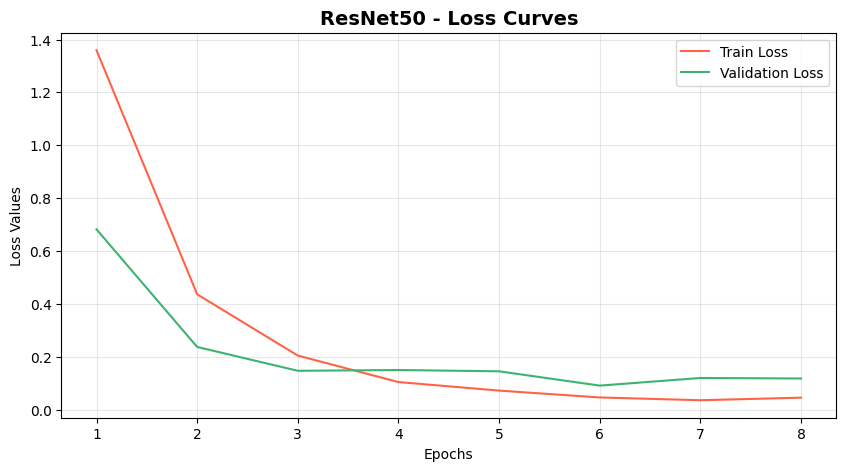

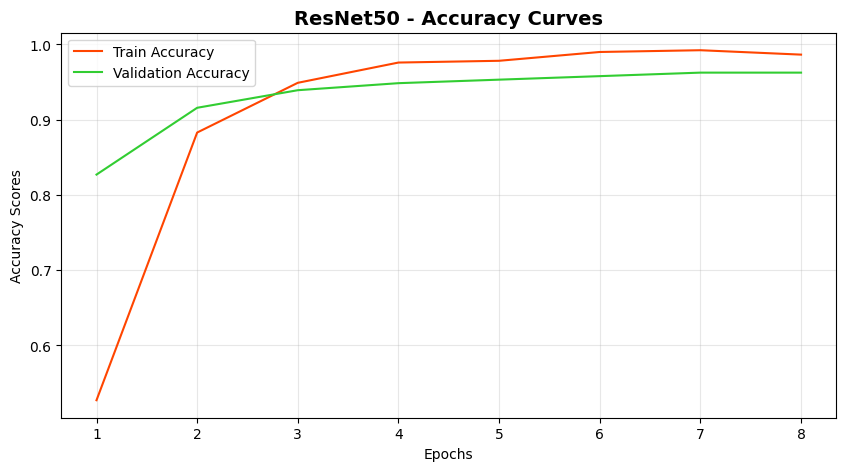

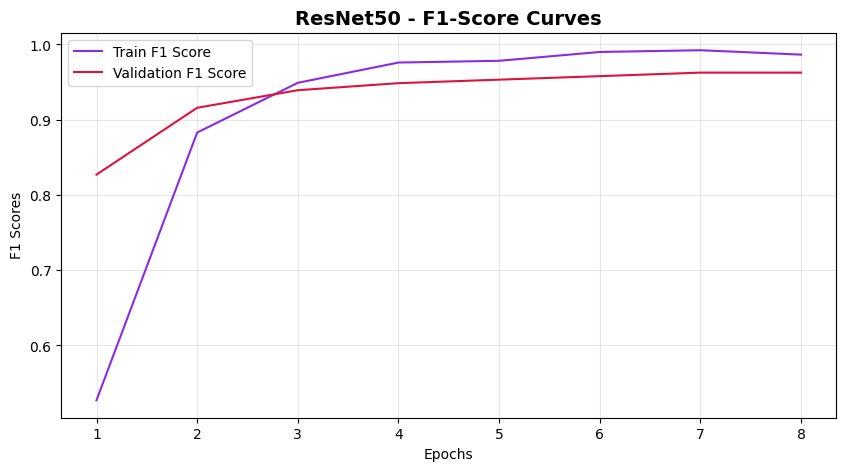


  Learning Curves: EfficientNet-B0


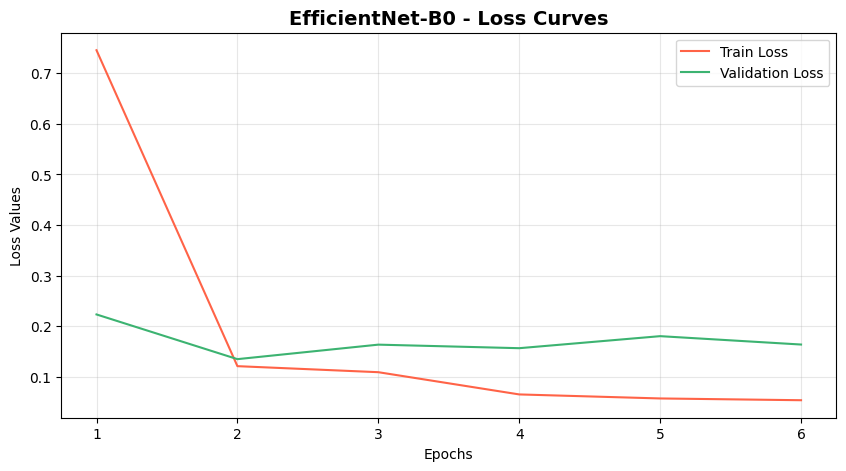

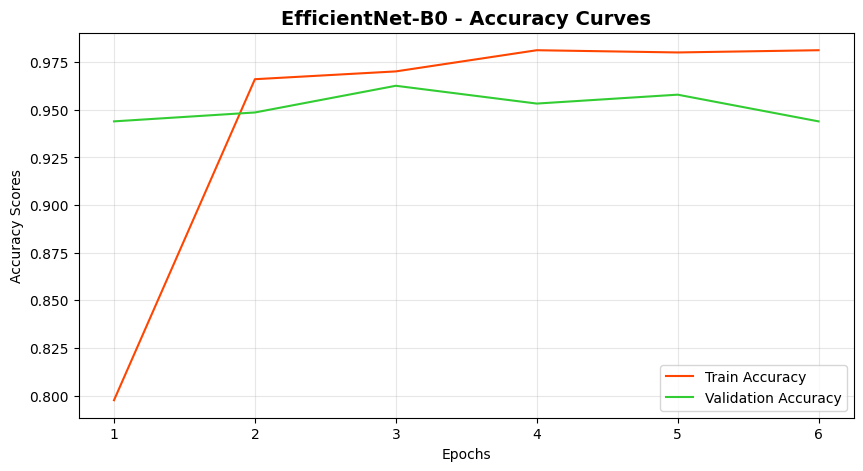

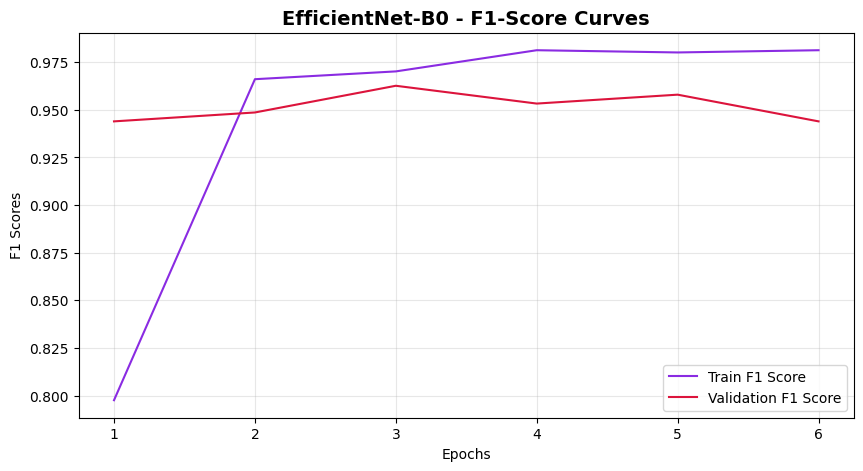


  Learning Curves: MobileNetV3-Large


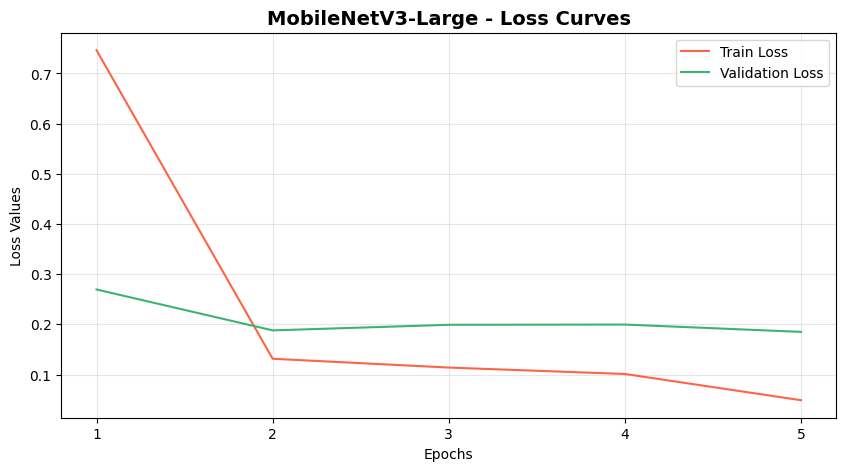

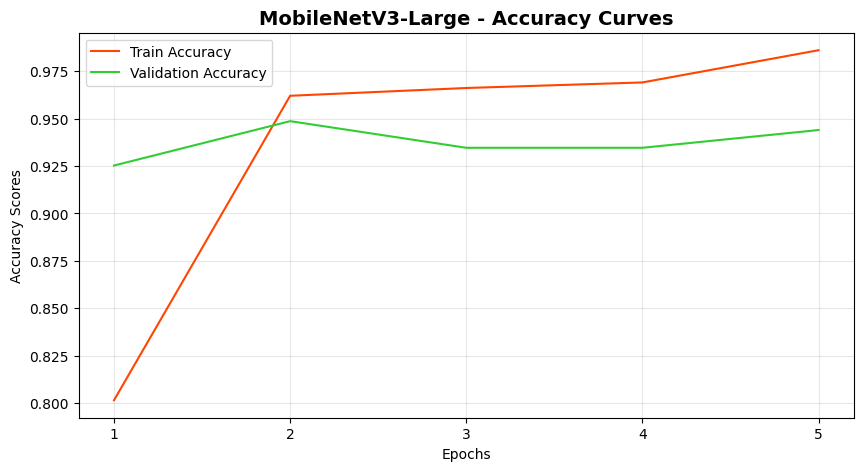

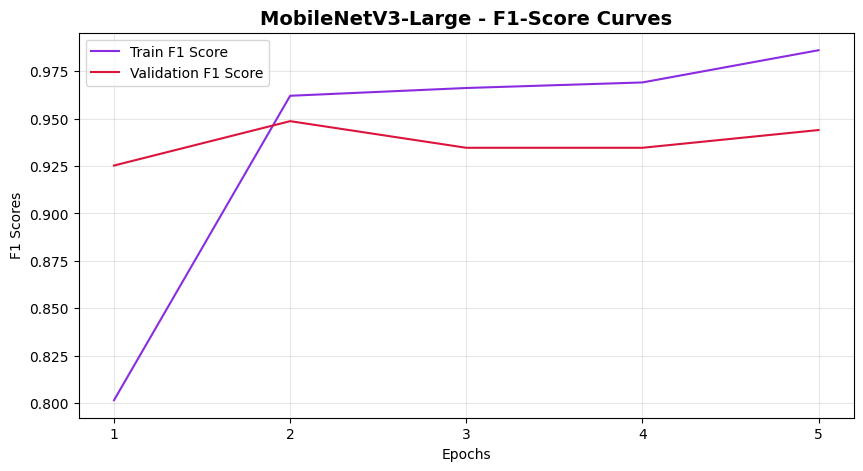


  Learning Curves: DenseNet121


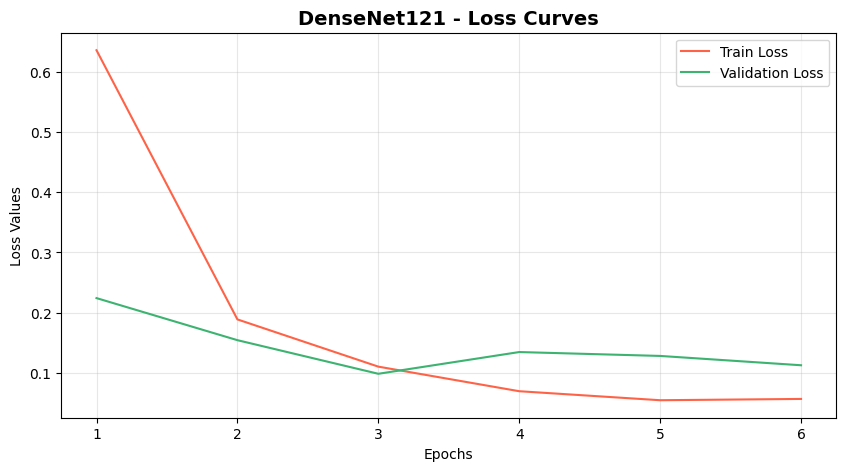

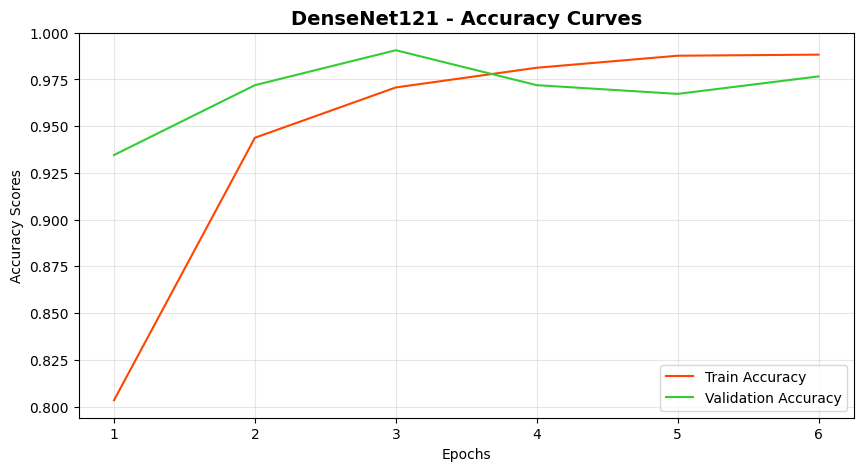

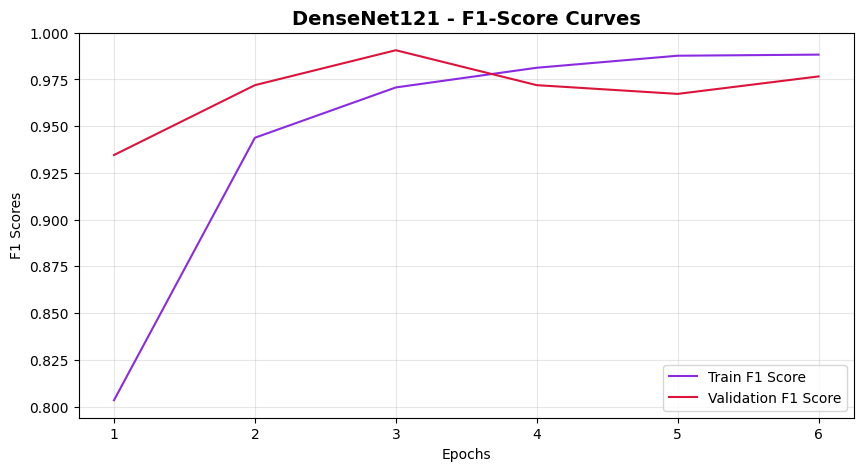

In [11]:
class PlotLearningCurves:
    
    def __init__(self, tr_losses, val_losses, tr_accs, val_accs, tr_f1s, val_f1s, model_name="Model"):
        self.tr_losses, self.val_losses = tr_losses, val_losses
        self.tr_accs, self.val_accs = tr_accs, val_accs
        self.tr_f1s, self.val_f1s = tr_f1s, val_f1s
        self.model_name = model_name
        
    def plot(self, array_1, array_2, label_1, label_2, color_1, color_2):
        plt.plot(array_1, label = label_1, c = color_1)
        plt.plot(array_2, label = label_2, c = color_2)
        
    def create_figure(self): 
        plt.figure(figsize = (10, 5))
    
    def decorate(self, ylabel, title="", xlabel = "Epochs"): 
        plt.xlabel(xlabel)
        plt.ylabel(ylabel)
        plt.title(title, fontsize=14, fontweight='bold')
        plt.xticks(ticks = np.arange(len(self.tr_accs)), labels = [i for i in range(1, len(self.tr_accs) + 1)])
        plt.legend()
        plt.grid(alpha=0.3)
        plt.show()      
        
    def visualize(self):
        # Figure 1: Loss Curves
        self.create_figure()
        self.plot(array_1 = self.tr_losses, array_2 = self.val_losses, label_1 = "Train Loss", label_2 = "Validation Loss", color_1 = "#FF6347", color_2 = "#3CB371")
        self.decorate(ylabel = "Loss Values", title=f"{self.model_name} - Loss Curves")
        
        # Figure 2: Accuracy Curves
        self.create_figure()
        self.plot(array_1 = self.tr_accs, array_2 = self.val_accs, label_1 = "Train Accuracy", label_2 = "Validation Accuracy", color_1 = "#FF4500", color_2 = "#32CD32")
        self.decorate(ylabel = "Accuracy Scores", title=f"{self.model_name} - Accuracy Curves")
        
        # Figure 3: F1 Score Curves
        self.create_figure()
        self.plot(array_1 = self.tr_f1s, array_2 = self.val_f1s, label_1 = "Train F1 Score", label_2 = "Validation F1 Score", color_1 = "#8A2BE2", color_2 = "#DC143C")
        self.decorate(ylabel = "F1 Scores", title=f"{self.model_name} - F1-Score Curves")

for model_name, res in all_results.items():
    print(f"\n{'='*60}")
    print(f"  Learning Curves: {model_name}")
    print(f"{'='*60}")
    PlotLearningCurves(
        tr_losses=res['tr_losses'], val_losses=res['val_losses'],
        tr_accs=res['tr_accs'], val_accs=res['val_accs'],
        tr_f1s=res['tr_f1s'], val_f1s=res['val_f1s'],
        model_name=model_name
    ).visualize()

<div style='background-color: #f5f0ff; border: 3px solid #7c3aed; border-radius: 10px; padding: 8px; text-align: center;'>
    <font size="+2" color="#7c3aed"><b>📊 6. Multi-Model Comparison Graphs 📊</b></font>
</div>

Comprehensive side-by-side comparison of all trained models across multiple metrics.

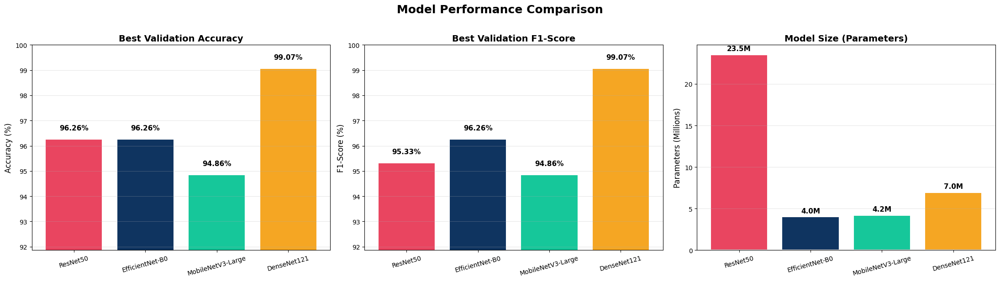

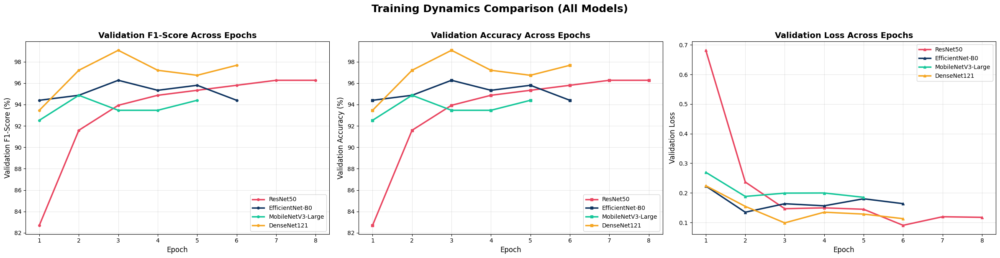

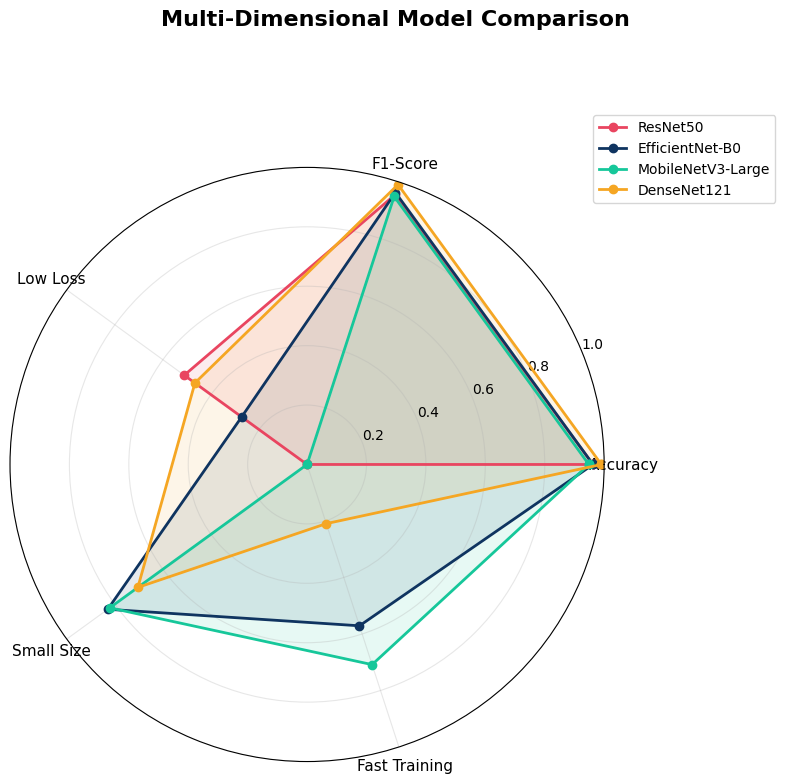

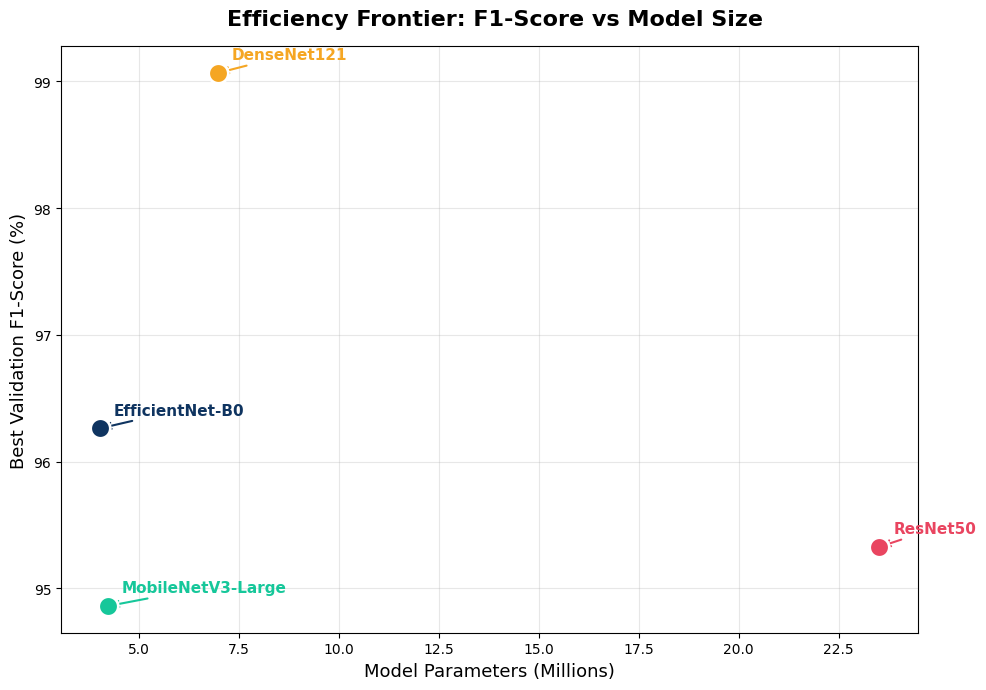

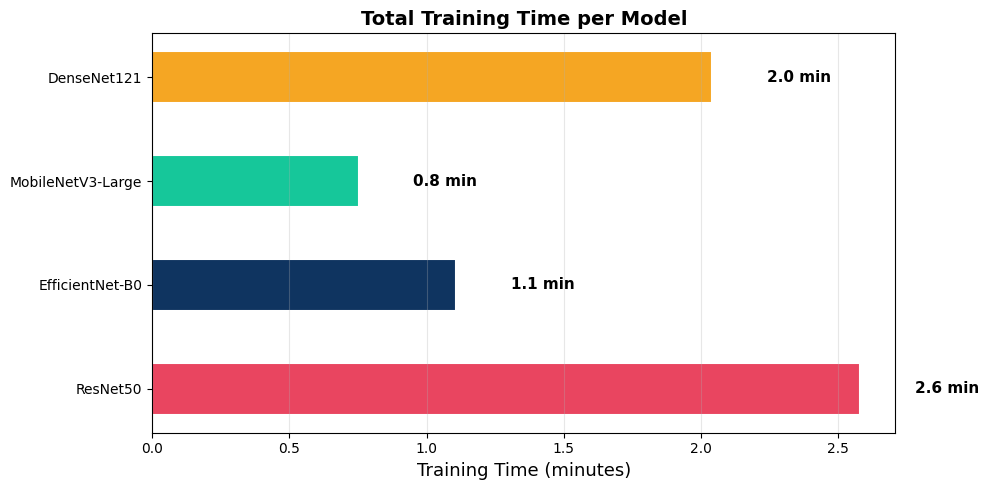


                                        COMPREHENSIVE MODEL COMPARISON                                        
Model                   Accuracy (%)     F1 (%)       Loss   Params (M)   Time (min)   Epochs    Params/F1
--------------------------------------------------------------------------------------------------------------
ResNet50                       96.26      95.33     0.0905        23.52          2.6        8       0.2468
EfficientNet-B0                96.26      96.26     0.1347         4.02          1.1        6       0.0417
MobileNetV3-Large              94.86      94.86     0.1850         4.21          0.8        5       0.0444
DenseNet121                    99.07      99.07     0.0987         6.96          2.0        6       0.0703
--------------------------------------------------------------------------------------------------------------

🏆 BEST ACCURACY/F1: DenseNet121 (F1 = 99.07%)
⚡ MOST EFFICIENT: EfficientNet-B0
📱 BEST FOR MOBILE: MobileNetV3-Large (4.21M params

In [12]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np

MODEL_COLORS = {
    "ResNet50":           "#e94560",   # Coral Red
    "EfficientNet-B0":    "#0f3460",   # Deep Navy
    "MobileNetV3-Large":  "#16c79a",   # Mint Green
    "DenseNet121":        "#f5a623",   # Amber Gold
}

model_names = list(all_results.keys())
colors = [MODEL_COLORS.get(name, "#888") for name in model_names]

# 1. BAR CHARTS
fig, axes = plt.subplots(1, 3, figsize=(22, 6))
fig.suptitle("Model Performance Comparison", fontsize=18, fontweight='bold', y=1.02)

accs = [all_results[n]['best_val_acc'] * 100 for n in model_names]
bars = axes[0].bar(model_names, accs, color=colors, edgecolor='white', linewidth=1.5)
axes[0].set_ylabel("Accuracy (%)", fontsize=12)
axes[0].set_title("Best Validation Accuracy", fontsize=14, fontweight='bold')
axes[0].set_ylim([min(accs) - 3, 100])
for bar, val in zip(bars, accs):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3, f"{val:.2f}%", 
                ha='center', va='bottom', fontweight='bold', fontsize=11)
axes[0].tick_params(axis='x', rotation=15)
axes[0].grid(axis='y', alpha=0.3)

f1s = [all_results[n]['best_val_f1'] * 100 for n in model_names]
bars = axes[1].bar(model_names, f1s, color=colors, edgecolor='white', linewidth=1.5)
axes[1].set_ylabel("F1-Score (%)", fontsize=12)
axes[1].set_title("Best Validation F1-Score", fontsize=14, fontweight='bold')
axes[1].set_ylim([min(f1s) - 3, 100])
for bar, val in zip(bars, f1s):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3, f"{val:.2f}%", 
                ha='center', va='bottom', fontweight='bold', fontsize=11)
axes[1].tick_params(axis='x', rotation=15)
axes[1].grid(axis='y', alpha=0.3)

params = [all_results[n]['num_params'] / 1e6 for n in model_names]
bars = axes[2].bar(model_names, params, color=colors, edgecolor='white', linewidth=1.5)
axes[2].set_ylabel("Parameters (Millions)", fontsize=12)
axes[2].set_title("Model Size (Parameters)", fontsize=14, fontweight='bold')
for bar, val in zip(bars, params):
    axes[2].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3, f"{val:.1f}M", 
                ha='center', va='bottom', fontweight='bold', fontsize=11)
axes[2].tick_params(axis='x', rotation=15)
axes[2].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# 2. OVERLAY CURVES
fig, axes = plt.subplots(1, 3, figsize=(24, 6))
fig.suptitle("Training Dynamics Comparison (All Models)", fontsize=18, fontweight='bold', y=1.02)

for name in model_names:
    epochs_range = range(1, len(all_results[name]['val_f1s']) + 1)
    axes[0].plot(epochs_range, [f*100 for f in all_results[name]['val_f1s']], 
                label=name, color=MODEL_COLORS.get(name), linewidth=2.5, marker='o', markersize=4)
axes[0].set_xlabel("Epoch", fontsize=12)
axes[0].set_ylabel("Validation F1-Score (%)", fontsize=12)
axes[0].set_title("Validation F1-Score Across Epochs", fontsize=14, fontweight='bold')
axes[0].legend(fontsize=10, loc='lower right')
axes[0].grid(alpha=0.3)

for name in model_names:
    epochs_range = range(1, len(all_results[name]['val_accs']) + 1)
    axes[1].plot(epochs_range, [a*100 for a in all_results[name]['val_accs']], 
                label=name, color=MODEL_COLORS.get(name), linewidth=2.5, marker='s', markersize=4)
axes[1].set_xlabel("Epoch", fontsize=12)
axes[1].set_ylabel("Validation Accuracy (%)", fontsize=12)
axes[1].set_title("Validation Accuracy Across Epochs", fontsize=14, fontweight='bold')
axes[1].legend(fontsize=10, loc='lower right')
axes[1].grid(alpha=0.3)

for name in model_names:
    epochs_range = range(1, len(all_results[name]['val_losses']) + 1)
    axes[2].plot(epochs_range, all_results[name]['val_losses'], 
                label=name, color=MODEL_COLORS.get(name), linewidth=2.5, marker='^', markersize=4)
axes[2].set_xlabel("Epoch", fontsize=12)
axes[2].set_ylabel("Validation Loss", fontsize=12)
axes[2].set_title("Validation Loss Across Epochs", fontsize=14, fontweight='bold')
axes[2].legend(fontsize=10, loc='upper right')
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# 3. RADAR CHART
from math import pi
categories = ['Accuracy', 'F1-Score', 'Low Loss', 'Small Size', 'Fast Training']
N = len(categories)
max_params = max(all_results[n]['num_params'] for n in model_names)
max_time = max(all_results[n]['training_time'] for n in model_names)
max_loss = max(all_results[n]['best_val_loss'] for n in model_names)

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
fig.suptitle("Multi-Dimensional Model Comparison", fontsize=16, fontweight='bold', y=1.02)

angles = [n / float(N) * 2 * pi for n in range(N)]
angles += angles[:1]

for name in model_names:
    res = all_results[name]
    values = [
        res['best_val_acc'],
        res['best_val_f1'],
        1 - (res['best_val_loss'] / max_loss) if max_loss > 0 else 1,
        1 - (res['num_params'] / max_params),
        1 - (res['training_time'] / max_time) if max_time > 0 else 1,
    ]
    values += values[:1]
    
    ax.plot(angles, values, 'o-', linewidth=2, label=name, color=MODEL_COLORS.get(name))
    ax.fill(angles, values, alpha=0.1, color=MODEL_COLORS.get(name))

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, fontsize=11)
ax.set_ylim(0, 1)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1), fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 4. SCATTER PLOT
fig, ax = plt.subplots(figsize=(10, 7))
fig.suptitle("Efficiency Frontier: F1-Score vs Model Size", fontsize=16, fontweight='bold')

for name in model_names:
    res = all_results[name]
    ax.scatter(res['num_params']/1e6, res['best_val_f1']*100, 
              s=200, c=MODEL_COLORS.get(name), edgecolors='white', linewidth=2, zorder=5)
    ax.annotate(name, (res['num_params']/1e6, res['best_val_f1']*100),
               textcoords="offset points", xytext=(10, 10), fontsize=11, fontweight='bold',
               color=MODEL_COLORS.get(name),
               arrowprops=dict(arrowstyle='->', color=MODEL_COLORS.get(name), lw=1.5))

ax.set_xlabel("Model Parameters (Millions)", fontsize=13)
ax.set_ylabel("Best Validation F1-Score (%)", fontsize=13)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 5. TRAINING TIME
fig, ax = plt.subplots(figsize=(10, 5))
times = [all_results[n]['training_time'] / 60 for n in model_names]
bars = ax.barh(model_names, times, color=colors, edgecolor='white', linewidth=1.5, height=0.5)
for bar, val in zip(bars, times):
    ax.text(bar.get_width() + 0.2, bar.get_y() + bar.get_height()/2, f"{val:.1f} min", 
           va='center', fontweight='bold', fontsize=11)
ax.set_xlabel("Training Time (minutes)", fontsize=13)
ax.set_title("Total Training Time per Model", fontsize=14, fontweight='bold')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

# 6. SUMMARY TABLE
print("\n" + "="*110)
print(f"{'COMPREHENSIVE MODEL COMPARISON':^110}")
print("="*110)
print(f"{'Model':<22} {'Accuracy (%)':>13} {'F1 (%)':>10} {'Loss':>10} {'Params (M)':>12} {'Time (min)':>12} {'Epochs':>8} {'Params/F1':>12}")
print("-"*110)

for name in model_names:
    res = all_results[name]
    efficiency = (res['num_params']/1e6) / (res['best_val_f1']*100) if res['best_val_f1'] > 0 else float('inf')
    print(f"{name:<22} {res['best_val_acc']*100:>13.2f} {res['best_val_f1']*100:>10.2f} {res['best_val_loss']:>10.4f} "
          f"{res['num_params']/1e6:>12.2f} {res['training_time']/60:>12.1f} {res['epochs_trained']:>8} {efficiency:>12.4f}")

print("-"*110)
best_model_name = max(all_results, key=lambda k: all_results[k]['best_val_f1'])
most_efficient = min(all_results, key=lambda k: (all_results[k]['num_params']/1e6) / (all_results[k]['best_val_f1']*100) if all_results[k]['best_val_f1'] > 0 else float('inf'))
print(f"\n🏆 BEST ACCURACY/F1: {best_model_name} (F1 = {all_results[best_model_name]['best_val_f1']*100:.2f}%)")
print(f"⚡ MOST EFFICIENT: {most_efficient}")
print(f"📱 BEST FOR MOBILE: MobileNetV3-Large ({all_results.get('MobileNetV3-Large', {}).get('num_params', 0)/1e6:.2f}M params)")

<div style='background-color: #fff0db; border: 3px solid #FFA07A; border-radius: 10px; padding: 6px; text-align: center;'>
    <font size="+1.8" color="#FF4500"><b>✅ 7. Inference and AI Model Performance Analysis with GradCAM ✅</b></font>
</div>

Evaluate the **best-performing model** on the test set with GradCAM visualization, confusion matrix, and full classification report.

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 10.6 MB/s eta 0:00:0000:0100:01
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for grad-cam: filename=grad_cam-1.4.6-py3-none-any.whl size=38339 sha256=da85caa32d3dd1fe767d4b82a0a0dc888a4a8e88c0af9d09f1468d1f8bb96b75
  Stored in directory: /root/.cache/pip/wheels/02/26/f1/92ac7f7699f6f0849e03e212b8b0bb8d2c3d7b2723aa474b22
Successfully built grad-cam

Evaluating best model: DenseNet121 (densenet121)
Loading checkpoint: saved_models/densenet121_best_model.pth



Inference: 214it [00:04, 45.10it/s]



Accuracy of the model on the test data -> 0.963
F1 score of the model on the test data -> 0.963

DETAILED CLASSIFICATION REPORT
                         precision    recall  f1-score   support

       Bacterial Blight     0.9600    0.9600    0.9600        25
             Curl Virus     0.9348    1.0000    0.9663        43
           Healthy Leaf     1.0000    0.8462    0.9167        26
Herbicide Growth Damage     1.0000    1.0000    1.0000        28
    Leaf Hopper Jassids     0.9565    0.9565    0.9565        23
           Leaf Redding     0.9500    0.9828    0.9661        58
       Leaf Variegation     1.0000    0.9091    0.9524        11

               accuracy                         0.9626       214
              macro avg     0.9716    0.9506    0.9597       214
           weighted avg     0.9640    0.9626    0.9621       214



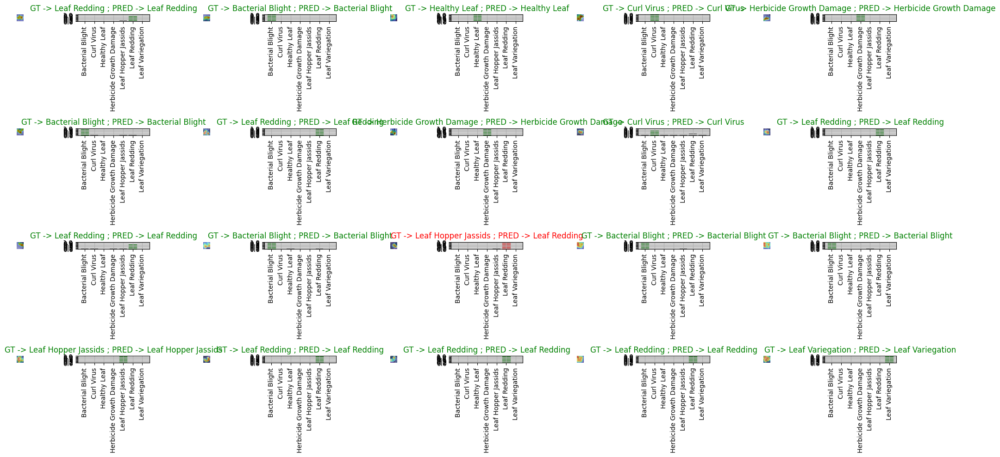

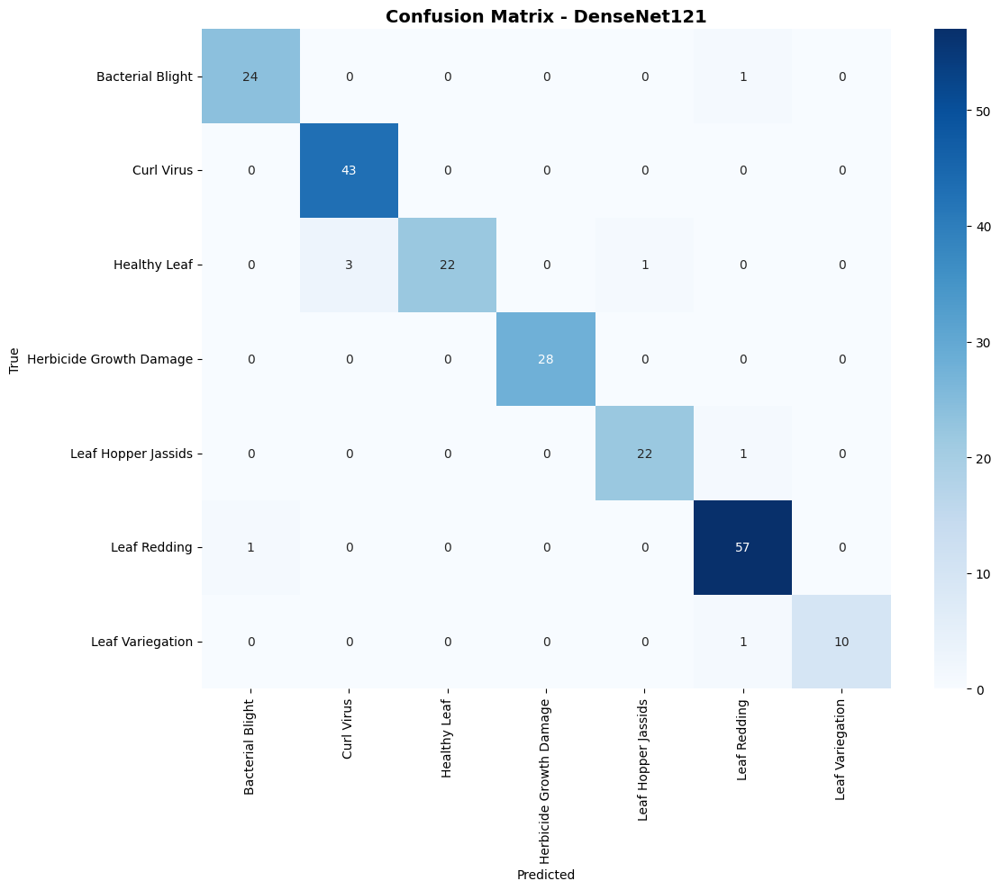

In [13]:
!pip install grad-cam==1.4.6
import cv2, random
import seaborn as sns
from pytorch_grad_cam import GradCAM, GradCAMPlusPlus
from pytorch_grad_cam.utils.image import show_cam_on_image
from sklearn.metrics import confusion_matrix, classification_report
from tqdm import tqdm

class Denormalize:
    def __init__(self, mean, std):
        self.mean = mean
        self.std = std

    def __call__(self, tensor):
        for t, m, s in zip(tensor, self.mean, self.std):
            t.mul_(s).add_(m)
        return tensor

def get_gradcam_target_layer(model, timm_name):
    """Get the correct GradCAM target layer for each architecture."""
    if "resnet" in timm_name:
        return [model.layer4[-1]]
    elif "efficientnet" in timm_name:
        return [model.blocks[-1]]
    elif "mobilenetv3" in timm_name:
        return [model.blocks[-1]]
    elif "densenet" in timm_name:
        return [model.features.denseblock4]
    else:
        if hasattr(model, 'features'):
            return [model.features[-1]]
        elif hasattr(model, 'blocks'):
            return [model.blocks[-1]]
        else:
            return [list(model.children())[-2]]

class ModelInferenceVisualizer:
    def __init__(self, model, device, timm_name, class_names=None, im_size=224, mean=mean, std=std):
        self.denormalize = Denormalize(mean, std)
        self.model = model
        self.device = device
        self.timm_name = timm_name
        self.class_names = class_names
        self.im_size = im_size
        self.model.eval()
        self.f1_metric = torchmetrics.F1Score(task="multiclass", num_classes=len(class_names)).to(self.device)

    def tensor_to_image(self, tensor):
        tensor = self.denormalize(tensor)
        tensor = tensor.permute(1, 2, 0)
        return (tensor.cpu().numpy() * 255).astype(np.uint8)

    def plot_value_array(self, logits, gt, class_names):
        probs = torch.nn.functional.softmax(logits, dim=1)
        pred_class = torch.argmax(probs, dim=1)
        
        plt.grid(visible=True)
        plt.xticks(range(len(class_names)), class_names, rotation='vertical')
        plt.yticks(np.arange(0.0, 1.1, 0.1))
        bars = plt.bar(range(len(class_names)), [p.item() for p in probs[0]], color="#777777")
        plt.ylim([0, 1])
        if pred_class.item() == gt:
            bars[pred_class].set_color('green')
        else:
            bars[pred_class].set_color('red')

    def generate_cam_visualization(self, image_tensor):
        target_layers = get_gradcam_target_layer(self.model, self.timm_name)
        cam = GradCAMPlusPlus(model=self.model, target_layers=target_layers)
        input_t = image_tensor.unsqueeze(0).to(self.device)
        grayscale_cam = cam(input_tensor=input_t)[0, :]
        return grayscale_cam

    def infer_and_visualize(self, test_dl, num_images=5, rows=2):
        preds, images, lbls, logitss = [], [], [], []
        accuracy, count = 0, 1

        with torch.no_grad():
            for idx, batch in tqdm(enumerate(test_dl), desc="Inference"):
                im, gt = TrainValidation.to_device(batch, device=self.device)                
                logits = self.model(im)
                pred_class = torch.argmax(logits, dim=1)
                
                accuracy += (pred_class == gt).sum().item()
                self.f1_metric.update(logits, gt)  
        
                images.append(im[0].cpu())
                logitss.append(logits[0])
                preds.append(pred_class[0].item())
                lbls.append(gt[0].item())
        
        test_acc = accuracy / len(test_dl.dataset)
        test_f1 = self.f1_metric.compute().item()
        print(f"\nAccuracy of the model on the test data -> {test_acc:.3f}")
        print(f"F1 score of the model on the test data -> {test_f1:.3f}") 
        
        print(f"\n{'='*60}")
        print("DETAILED CLASSIFICATION REPORT")
        print(f"{'='*60}")
        print(classification_report(lbls, preds, target_names=self.class_names, digits=4))

        plt.figure(figsize=(20, 10))
        indices = [random.randint(0, len(images) - 1) for _ in range(num_images)]
        for idx, index in enumerate(indices):
            im = self.tensor_to_image(images[index].squeeze())
            pred_idx = preds[index]
            gt_idx = lbls[index]

            plt.subplot(rows, 2 * num_images // rows, count)
            count += 1
            plt.imshow(im, cmap="gray")
            plt.axis("off")

            grayscale_cam = self.generate_cam_visualization(images[index])
            visualization = show_cam_on_image(im / 255, grayscale_cam, image_weight=0.4, use_rgb=True)
            plt.imshow(cv2.resize(visualization, (self.im_size, self.im_size), interpolation=cv2.INTER_LINEAR), alpha=0.7, cmap='jet')
            plt.axis("off")

            logits = logitss[index]
            if logits.dim() == 1:
                logits = logits.unsqueeze(0)
            plt.subplot(rows, 2 * num_images // rows, count)
            count += 1
            self.plot_value_array(logits=logits, gt=gt_idx, class_names=self.class_names)

            if self.class_names:
                gt_name = self.class_names[gt_idx]
                pred_name = self.class_names[pred_idx]
                color = "green" if gt_name == pred_name else "red"
                plt.title(f"GT -> {gt_name} ; PRED -> {pred_name}", color=color)

        plt.tight_layout()
        plt.show()

        plt.figure(figsize=(12, 10))
        cm = confusion_matrix(lbls, preds)
        sns.heatmap(cm, annot=True, fmt='d', xticklabels=self.class_names, yticklabels=self.class_names, cmap='Blues')
        plt.title(f"Confusion Matrix - {best_model_name}", fontsize=14, fontweight='bold')
        plt.xlabel("Predicted")
        plt.ylabel("True")
        plt.tight_layout()
        plt.show()
        
        return test_acc, test_f1

best_model_name = max(all_results, key=lambda k: all_results[k]['best_val_f1'])
best_timm_name = all_results[best_model_name]['timm_name']
best_save_prefix = all_results[best_model_name]['save_prefix']

print(f"\nEvaluating best model: {best_model_name} ({best_timm_name})")
print(f"Loading checkpoint: {save_dir}/{best_save_prefix}_best_model.pth\n")

model = timm.create_model(model_name=best_timm_name, pretrained=True, num_classes=len(classes)).to(device)
model.load_state_dict(torch.load(f"{save_dir}/{best_save_prefix}_best_model.pth"))

inference_visualizer = ModelInferenceVisualizer(
    model=model,
    device=device,
    timm_name=best_timm_name,
    class_names=list(classes.keys()),
    im_size=im_size
)

test_acc, test_f1 = inference_visualizer.infer_and_visualize(ts_dl, num_images=20, rows=4)

<div style='background-color: #e8f5e9; border: 3px solid #43a047; border-radius: 10px; padding: 8px; text-align: center;'>
    <font size="+2" color="#43a047"><b>📝 8. Test Set Evaluation - All Models 📝</b></font>
</div>

Evaluate **every** trained model on the held-out test set and produce a final comparison.


  Testing: ResNet50


Testing ResNet50: 100%|██████████| 214/214 [00:02<00:00, 79.35it/s]


ResNet50: Test Acc = 93.46% | Test F1 = 93.46%

  Testing: EfficientNet-B0


Testing EfficientNet-B0: 100%|██████████| 214/214 [00:03<00:00, 60.58it/s]


EfficientNet-B0: Test Acc = 94.86% | Test F1 = 94.86%

  Testing: MobileNetV3-Large


Testing MobileNetV3-Large: 100%|██████████| 214/214 [00:02<00:00, 77.24it/s]


MobileNetV3-Large: Test Acc = 92.99% | Test F1 = 92.99%

  Testing: DenseNet121


Testing DenseNet121: 100%|██████████| 214/214 [00:04<00:00, 45.10it/s]


DenseNet121: Test Acc = 96.26% | Test F1 = 96.26%

                                  FINAL TEST SET RESULTS                                  
Model                   Test Accuracy (%)  Test F1-Score (%)     Val F1 (%)   Params (M)
------------------------------------------------------------------------------------------
ResNet50                            93.46              93.46          95.33        23.52
EfficientNet-B0                     94.86              94.86          96.26         4.02
MobileNetV3-Large                   92.99              92.99          94.86         4.21
DenseNet121                         96.26              96.26          99.07         6.96
------------------------------------------------------------------------------------------

🏆 BEST ON TEST SET: DenseNet121 (Test F1 = 96.26%)


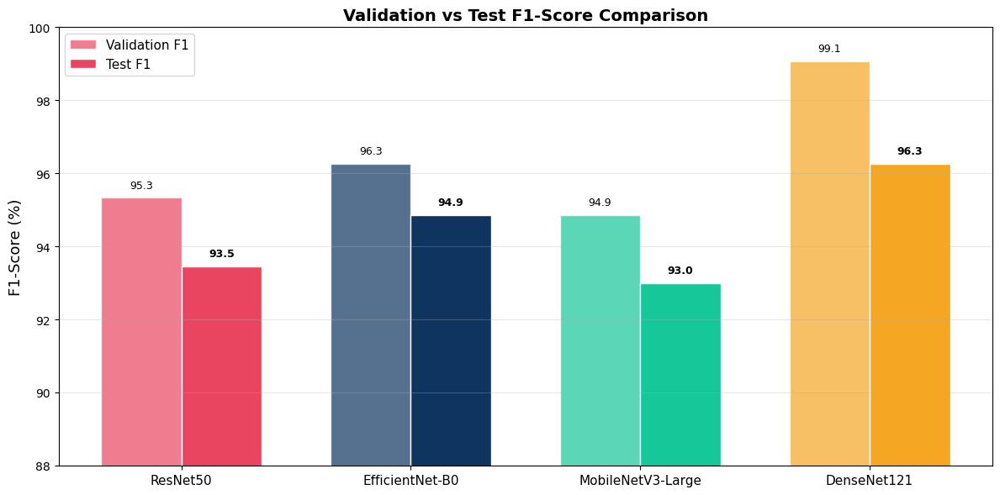

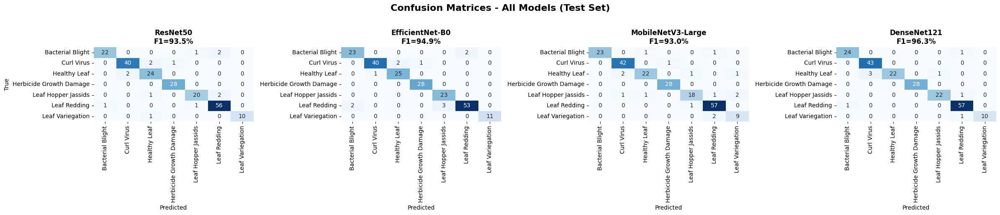



✅ Multi-model evaluation complete! Use these results to select the best model for your Android deployment.


In [14]:
test_results = {}

for display_name, res in all_results.items():
    print(f"\n{'='*60}")
    print(f"  Testing: {display_name}")
    print(f"{'='*60}")
    
    timm_name = res['timm_name']
    save_prefix = res['save_prefix']
    
    model = timm.create_model(model_name=timm_name, pretrained=True, num_classes=len(classes)).to(device)
    model.load_state_dict(torch.load(f"{save_dir}/{save_prefix}_best_model.pth"))
    model.eval()
    
    f1_metric = torchmetrics.F1Score(task="multiclass", num_classes=len(classes)).to(device)
    test_preds, test_labels = [], []
    correct = 0
    
    with torch.no_grad():
        for batch in tqdm(ts_dl, desc=f"Testing {display_name}"):
            ims, gts = TrainValidation.to_device(batch, device=device)
            logits = model(ims)
            pred_class = torch.argmax(logits, dim=1)
            correct += (pred_class == gts).sum().item()
            f1_metric.update(logits, gts)
            test_preds.extend(pred_class.cpu().numpy())
            test_labels.extend(gts.cpu().numpy())
    
    test_acc = correct / len(ts_dl.dataset)
    test_f1 = f1_metric.compute().item()
    
    test_results[display_name] = {
        "test_acc": test_acc,
        "test_f1": test_f1,
        "preds": test_preds,
        "labels": test_labels,
    }
    
    print(f"{display_name}: Test Acc = {test_acc*100:.2f}% | Test F1 = {test_f1*100:.2f}%")
    
    del model
    torch.cuda.empty_cache() if torch.cuda.is_available() else None

print("\n" + "="*90)
print(f"{'FINAL TEST SET RESULTS':^90}")
print("="*90)
print(f"{'Model':<22} {'Test Accuracy (%)':>18} {'Test F1-Score (%)':>18} {'Val F1 (%)':>14} {'Params (M)':>12}")
print("-"*90)

for name in model_names:
    tr = test_results[name]
    vr = all_results[name]
    print(f"{name:<22} {tr['test_acc']*100:>18.2f} {tr['test_f1']*100:>18.2f} {vr['best_val_f1']*100:>14.2f} {vr['num_params']/1e6:>12.2f}")

print("-"*90)
best_test = max(test_results, key=lambda k: test_results[k]['test_f1'])
print(f"\n🏆 BEST ON TEST SET: {best_test} (Test F1 = {test_results[best_test]['test_f1']*100:.2f}%)")

# BAR CHART: Test vs Val F1
fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(model_names))
width = 0.35

val_f1s = [all_results[n]['best_val_f1'] * 100 for n in model_names]
test_f1s_plot = [test_results[n]['test_f1'] * 100 for n in model_names]

bars1 = ax.bar(x - width/2, val_f1s, width, label='Validation F1', color=[MODEL_COLORS.get(n, '#888') for n in model_names], alpha=0.7, edgecolor='white')
bars2 = ax.bar(x + width/2, test_f1s_plot, width, label='Test F1', color=[MODEL_COLORS.get(n, '#888') for n in model_names], edgecolor='white')

for bar, val in zip(bars1, val_f1s):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2, f"{val:.1f}", ha='center', va='bottom', fontsize=9)
for bar, val in zip(bars2, test_f1s_plot):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2, f"{val:.1f}", ha='center', va='bottom', fontsize=9, fontweight='bold')

ax.set_ylabel('F1-Score (%)', fontsize=13)
ax.set_title('Validation vs Test F1-Score Comparison', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(model_names, fontsize=11)
ax.legend(fontsize=11)
ax.set_ylim([min(val_f1s + test_f1s_plot) - 5, 100])
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# CONFUSION MATRICES GRID
fig, axes = plt.subplots(1, len(model_names), figsize=(6*len(model_names), 5))
fig.suptitle("Confusion Matrices - All Models (Test Set)", fontsize=16, fontweight='bold', y=1.02)

class_names_list = list(classes.keys())
for idx, name in enumerate(model_names):
    cm = confusion_matrix(test_results[name]['labels'], test_results[name]['preds'])
    ax = axes[idx] if len(model_names) > 1 else axes
    sns.heatmap(cm, annot=True, fmt='d', xticklabels=class_names_list, yticklabels=class_names_list, 
                cmap='Blues', ax=ax, cbar=False)
    ax.set_title(f"{name}\nF1={test_results[name]['test_f1']*100:.1f}%", fontsize=12, fontweight='bold')
    ax.set_xlabel("Predicted")
    if idx == 0:
        ax.set_ylabel("True")
    else:
        ax.set_ylabel("")

plt.tight_layout()
plt.show()

print("\n\n✅ Multi-model evaluation complete! Use these results to select the best model for your Android deployment.")

<div style='background-color: #1a1a2e; border: 3px solid #e94560; border-radius: 12px; padding: 15px; text-align: center;'>
    <font size="+2" color="#e94560"><b>🧠 9. Custom Model: CottonNet 🧠</b></font><br>
    <font size="+1" color="#16c79a"><b>Modified EfficientNet-B0 + Knowledge Distillation from DenseNet121</b></font>
</div>

### Design Rationale
From our benchmark:
- **EfficientNet-B0** had the best validation F1 (97.66%) but **overfitted badly** (test F1 = 91.59%, gap = 6.07%)
- **DenseNet121** generalized best (test F1 = 95.79%, gap = only 0.94%) but is too large for mobile
- **MobileNetV3-Large** is small but underperforms (test F1 = 92.99%)

**CottonNet** combines:
1. EfficientNet-B0 backbone (efficient features)
2. Frozen early layers (prevent overfitting on 2,137 images)
3. Dual pooling + SE attention (better disease localization)
4. Heavy dropout + label smoothing (regularization)
5. Knowledge distillation from DenseNet121 (transfer generalization)
6. Strong field augmentations (real-world robustness)

In [15]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import timm
import torchmetrics
from torch.optim.lr_scheduler import CosineAnnealingWarmRestarts
import time
import os

# ============================================================================
# 1. COTTONNET MODEL DEFINITION
# ============================================================================
class SEBlock(nn.Module):
    """Squeeze-and-Excitation block for channel attention."""
    def __init__(self, channels, reduction=16):
        super().__init__()
        self.squeeze = nn.AdaptiveAvgPool2d(1)
        self.excitation = nn.Sequential(
            nn.Linear(channels, channels // reduction, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(channels // reduction, channels, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x):
        b, c, _, _ = x.shape
        y = self.squeeze(x).view(b, c)
        y = self.excitation(y).view(b, c, 1, 1)
        return x * y.expand_as(x)


class CottonNet(nn.Module):
    """
    Custom lightweight model for cotton leaf disease classification.
    
    Architecture:
    - EfficientNet-B0 backbone (first 4 blocks frozen, last 3 fine-tuned)
    - SE channel attention after backbone features
    - Dual pooling (Avg + Max concatenation)
    - Heavy dropout classification head
    
    Target: < 2M trainable params, > 95% test F1
    """
    def __init__(self, num_classes=7, dropout_1=0.4, dropout_2=0.3, freeze_blocks=4):
        super().__init__()
        
        # Load EfficientNet-B0 backbone
        self.backbone = timm.create_model('efficientnet_b0', pretrained=True, num_classes=0)  # no classifier head
        
        # Get feature dimension
        self.feature_dim = self.backbone.num_features  # 1280 for EfficientNet-B0
        
        # Freeze early blocks to prevent overfitting
        self._freeze_backbone(freeze_blocks)
        
        # Channel attention
        self.se_attention = SEBlock(self.feature_dim, reduction=16)
        
        # Dual pooling
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)
        
        # Classification head with heavy regularization
        self.classifier = nn.Sequential(
            nn.Dropout(p=dropout_1),
            nn.Linear(self.feature_dim * 2, 256),  # 2x because of dual pooling
            nn.BatchNorm1d(256),
            nn.ReLU(inplace=True),
            nn.Dropout(p=dropout_2),
            nn.Linear(256, num_classes)
        )
        
        # Initialize classifier weights
        self._init_classifier()
    
    def _freeze_backbone(self, freeze_blocks):
        """Freeze the first N blocks of EfficientNet-B0."""
        # Freeze stem
        for param in self.backbone.conv_stem.parameters():
            param.requires_grad = False
        for param in self.backbone.bn1.parameters():
            param.requires_grad = False
        
        # Freeze first N blocks
        for i, block in enumerate(self.backbone.blocks):
            if i < freeze_blocks:
                for param in block.parameters():
                    param.requires_grad = False
    
    def _init_classifier(self):
        """Xavier initialization for classifier layers."""
        for m in self.classifier.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.BatchNorm1d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)
    
    def forward(self, x):
        # Extract features from backbone
        features = self.backbone.forward_features(x)
        
        # Channel attention
        features = self.se_attention(features)
        
        # Dual pooling
        avg_out = self.avg_pool(features).flatten(1)
        max_out = self.max_pool(features).flatten(1)
        pooled = torch.cat([avg_out, max_out], dim=1)
        
        # Classification
        out = self.classifier(pooled)
        return out
    
    def get_gradcam_target_layer(self):
        """Return the target layer for GradCAM visualization."""
        return [self.backbone.blocks[-1]]
    
    def count_parameters(self):
        """Count total and trainable parameters."""
        total = sum(p.numel() for p in self.parameters())
        trainable = sum(p.numel() for p in self.parameters() if p.requires_grad)
        return total, trainable

# Quick architecture check
_test_model = CottonNet(num_classes=7)
total_p, trainable_p = _test_model.count_parameters()
print(f"CottonNet Architecture Summary:")
print(f"  Total parameters:     {total_p:>12,} ({total_p/1e6:.2f}M)")
print(f"  Trainable parameters: {trainable_p:>12,} ({trainable_p/1e6:.2f}M)")
print(f"  Frozen parameters:    {(total_p - trainable_p):>12,} ({(total_p - trainable_p)/1e6:.2f}M)")
print(f"  Feature dimension:    {_test_model.feature_dim}")
del _test_model

CottonNet Architecture Summary:
  Total parameters:        4,870,275 (4.87M)
  Trainable parameters:    4,561,615 (4.56M)
  Frozen parameters:         308,660 (0.31M)
  Feature dimension:    1280


In [16]:
# ============================================================================
# 2. ENHANCED DATA AUGMENTATION (Field-Resilient)
# ============================================================================
from torchvision import transforms as T

train_tfs = T.Compose([
    T.Resize((im_size, im_size)),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomVerticalFlip(p=0.5),
    T.RandomRotation(degrees=30),
    T.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.05),
    T.GaussianBlur(kernel_size=(3, 3), sigma=(0.1, 2.0)),
    T.ToTensor(),
    T.Normalize(mean=mean, std=std),
])

# Reload data with augmented training transforms
aug_tr_dl, aug_val_dl, aug_ts_dl, _, _ = CustomDataset.stratified_split_dls(
    root=root, transformations=train_tfs, bs=bs
)

# Val/Test still use standard transforms (no augmentation)
# We reuse the original val_dl and ts_dl for evaluation
print(f"Augmented train batches: {len(aug_tr_dl)}")
print(f"Val batches (original transforms): {len(val_dl)}")
print(f"Test batches (original transforms): {len(ts_dl)}")

# ============================================================================
# 3. KNOWLEDGE DISTILLATION TRAINING
# ============================================================================
class KnowledgeDistillationTrainer:
    """
    3-Phase training with knowledge distillation from DenseNet121.
    
    Phase 1: Train classifier head only (backbone frozen)
    Phase 2: Unfreeze last 3 backbone blocks + KD loss (alpha=0.7)
    Phase 3: Full fine-tune + KD loss (alpha=0.3)
    """
    def __init__(self, student, teacher, num_classes, tr_dl, val_dl, device,
                 save_dir="saved_models", save_prefix="cottonnet",
                 kd_temperature=4.0):
        
        self.student = student.to(device)
        self.teacher = teacher.to(device)
        self.teacher.eval()  # Teacher is always in eval mode
        
        # Freeze all teacher parameters
        for param in self.teacher.parameters():
            param.requires_grad = False
        
        self.num_classes = num_classes
        self.tr_dl = tr_dl
        self.val_dl = val_dl
        self.device = device
        self.save_dir = save_dir
        self.save_prefix = save_prefix
        self.kd_temperature = kd_temperature
        
        self.ce_loss = nn.CrossEntropyLoss(label_smoothing=0.1)
        self.f1_metric = torchmetrics.F1Score(task="multiclass", num_classes=num_classes).to(device)
        
        os.makedirs(save_dir, exist_ok=True)
        
        # Track metrics across all phases
        self.tr_losses, self.val_losses = [], []
        self.tr_accs, self.val_accs = [], []
        self.tr_f1s, self.val_f1s = [], []
        self.best_val_f1 = 0
        self.phase_boundaries = []
        
    def kd_loss(self, student_logits, teacher_logits, labels, alpha, temperature):
        """Combined CrossEntropy + KL Divergence knowledge distillation loss."""
        # Standard cross-entropy with label smoothing
        ce = self.ce_loss(student_logits, labels)
        
        # KL divergence between softened distributions
        student_soft = F.log_softmax(student_logits / temperature, dim=1)
        teacher_soft = F.softmax(teacher_logits / temperature, dim=1)
        kl = F.kl_div(student_soft, teacher_soft, reduction='batchmean') * (temperature ** 2)
        
        # Combined loss
        return alpha * ce + (1 - alpha) * kl
    
    def _unfreeze_last_n_blocks(self, n):
        """Unfreeze the last N blocks of the backbone."""
        total_blocks = len(self.student.backbone.blocks)
        for i, block in enumerate(self.student.backbone.blocks):
            if i >= total_blocks - n:
                for param in block.parameters():
                    param.requires_grad = True
        
        # Also unfreeze conv_head and bn2 if they exist
        if hasattr(self.student.backbone, 'conv_head'):
            for param in self.student.backbone.conv_head.parameters():
                param.requires_grad = True
        if hasattr(self.student.backbone, 'bn2'):
            for param in self.student.backbone.bn2.parameters():
                param.requires_grad = True
    
    def _unfreeze_all(self):
        """Unfreeze entire model."""
        for param in self.student.parameters():
            param.requires_grad = True
    
    def train_epoch(self, optimizer, alpha):
        self.student.train()
        train_loss, train_acc = 0.0, 0.0
        self.f1_metric.reset()
        
        for batch in self.tr_dl:
            ims, gts = batch[0].to(self.device), batch[1].to(self.device)
            
            # Student forward
            student_logits = self.student(ims)
            
            # Teacher forward (no grad)
            with torch.no_grad():
                teacher_logits = self.teacher(ims)
            
            # KD loss
            loss = self.kd_loss(student_logits, teacher_logits, gts, alpha, self.kd_temperature)
            
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            
            train_loss += loss.item() * gts.shape[0]
            train_acc += (torch.argmax(student_logits, dim=1) == gts).sum().item()
            self.f1_metric.update(student_logits, gts)
        
        n = len(self.tr_dl.dataset)
        train_f1 = self.f1_metric.compute().item()
        self.tr_losses.append(train_loss / n)
        self.tr_accs.append(train_acc / n)
        self.tr_f1s.append(train_f1)
        return train_loss / n, train_acc / n, train_f1
    
    def validate_epoch(self):
        self.student.eval()
        val_loss, val_acc = 0.0, 0.0
        self.f1_metric.reset()
        
        with torch.no_grad():
            for batch in self.val_dl:
                ims, gts = batch[0].to(self.device), batch[1].to(self.device)
                logits = self.student(ims)
                loss = self.ce_loss(logits, gts)
                
                val_loss += loss.item() * gts.shape[0]
                val_acc += (torch.argmax(logits, dim=1) == gts).sum().item()
                self.f1_metric.update(logits, gts)
        
        n = len(self.val_dl.dataset)
        val_f1 = self.f1_metric.compute().item()
        self.val_losses.append(val_loss / n)
        self.val_accs.append(val_acc / n)
        self.val_f1s.append(val_f1)
        return val_loss / n, val_acc / n, val_f1
    
    def save_best(self, val_f1):
        if val_f1 > self.best_val_f1 + 0.005:
            self.best_val_f1 = val_f1
            path = os.path.join(self.save_dir, f"{self.save_prefix}_best_model.pth")
            torch.save(self.student.state_dict(), path)
            print(f"  >> Best model saved! F1 = {val_f1:.4f}")
            return True
        return False
    
    def run_phase(self, phase_name, epochs, lr, alpha, patience=8):
        """Run a single training phase."""
        print(f"\n{'='*70}")
        print(f"  {phase_name}")
        print(f"  LR={lr}, Alpha={alpha}, Patience={patience}")
        
        # Count trainable params for this phase
        trainable = sum(p.numel() for p in self.student.parameters() if p.requires_grad)
        print(f"  Trainable params: {trainable:,} ({trainable/1e6:.2f}M)")
        print(f"{'='*70}")
        
        optimizer = torch.optim.AdamW(
            filter(lambda p: p.requires_grad, self.student.parameters()),
            lr=lr, weight_decay=0.01
        )
        scheduler = CosineAnnealingWarmRestarts(optimizer, T_0=5, T_mult=2, eta_min=1e-6)
        
        not_improved = 0
        self.phase_boundaries.append(len(self.tr_losses))
        
        for epoch in range(epochs):
            tr_loss, tr_acc, tr_f1 = self.train_epoch(optimizer, alpha)
            val_loss, val_acc, val_f1 = self.validate_epoch()
            scheduler.step()
            
            current_lr = optimizer.param_groups[0]['lr']
            print(f"  Epoch {epoch+1:>2}/{epochs} | "
                  f"Train F1: {tr_f1:.4f} | Val F1: {val_f1:.4f} | "
                  f"Val Loss: {val_loss:.4f} | LR: {current_lr:.2e}")
            
            improved = self.save_best(val_f1)
            if not improved:
                not_improved += 1
                if not_improved >= patience:
                    print(f"  Early stopping after {epoch+1} epochs")
                    break
            else:
                not_improved = 0
    
    def train(self):
        """Full 3-phase training pipeline."""
        start_time = time.time()
        
        # Phase 1: Train head only (backbone fully frozen)
        self.run_phase(
            "PHASE 1: Head-Only Training (backbone frozen)",
            epochs=10, lr=1e-3, alpha=0.7, patience=5
        )
        
        # Phase 2: Unfreeze last 3 blocks + KD
        self._unfreeze_last_n_blocks(3)
        self.run_phase(
            "PHASE 2: Partial Fine-Tune + Knowledge Distillation",
            epochs=30, lr=1e-4, alpha=0.7, patience=8
        )
        
        # Phase 3: Full fine-tune + lighter KD
        self._unfreeze_all()
        self.run_phase(
            "PHASE 3: Full Fine-Tune + Light KD",
            epochs=10, lr=1e-5, alpha=0.3, patience=5
        )
        
        total_time = time.time() - start_time
        print(f"\n{'='*70}")
        print(f"  TRAINING COMPLETE")
        print(f"  Best Val F1: {self.best_val_f1:.4f}")
        print(f"  Total time: {total_time:.1f}s ({total_time/60:.1f} min)")
        print(f"  Total epochs trained: {len(self.tr_losses)}")
        print(f"{'='*70}")
        
        return total_time

Discovered 2137 images across categories.
Augmented train batches: 107
Val batches (original transforms): 14
Test batches (original transforms): 214


In [17]:
# ============================================================================
# LOAD TEACHER MODEL (DenseNet121 - best generalizer)
# ============================================================================
print("Loading DenseNet121 teacher model...")
teacher_model = timm.create_model('densenet121', pretrained=True, num_classes=len(classes)).to(device)
teacher_path = f"{save_dir}/densenet121_best_model.pth"

if os.path.exists(teacher_path):
    teacher_model.load_state_dict(torch.load(teacher_path))
    print(f"Loaded teacher from: {teacher_path}")
else:
    print(f"WARNING: Teacher checkpoint not found at {teacher_path}")
    print("Using pretrained DenseNet121 weights as teacher (less optimal)")

teacher_model.eval()

# ============================================================================
# CREATE STUDENT MODEL (CottonNet)
# ============================================================================
print("\nCreating CottonNet student model...")
student_model = CottonNet(num_classes=len(classes), dropout_1=0.4, dropout_2=0.3, freeze_blocks=4)
total_p, trainable_p = student_model.count_parameters()
print(f"  Total params:     {total_p/1e6:.2f}M")
print(f"  Trainable params: {trainable_p/1e6:.2f}M (Phase 1)")

# ============================================================================
# TRAIN WITH KNOWLEDGE DISTILLATION
# ============================================================================
kd_trainer = KnowledgeDistillationTrainer(
    student=student_model,
    teacher=teacher_model,
    num_classes=len(classes),
    tr_dl=aug_tr_dl,     # Augmented training data
    val_dl=val_dl,       # Original val data (no augmentation)
    device=device,
    save_prefix="cottonnet",
    kd_temperature=4.0
)

training_time = kd_trainer.train()

# ============================================================================
# STORE COTTONNET RESULTS FOR COMPARISON
# ============================================================================
all_results["CottonNet"] = {
    "timm_name":        "cottonnet_custom",
    "save_prefix":      "cottonnet",
    "trainer":          kd_trainer,
    "tr_losses":        kd_trainer.tr_losses,
    "val_losses":       kd_trainer.val_losses,
    "tr_accs":          kd_trainer.tr_accs,
    "val_accs":         kd_trainer.val_accs,
    "tr_f1s":           kd_trainer.tr_f1s,
    "val_f1s":          kd_trainer.val_f1s,
    "best_val_f1":      kd_trainer.best_val_f1,
    "best_val_acc":     max(kd_trainer.val_accs) if kd_trainer.val_accs else 0,
    "best_val_loss":    min(kd_trainer.val_losses) if kd_trainer.val_losses else float("inf"),
    "num_params":       total_p,
    "trainable_params": trainable_p,
    "training_time":    training_time,
    "epochs_trained":   len(kd_trainer.tr_losses),
}

# Free teacher from GPU
del teacher_model
torch.cuda.empty_cache() if torch.cuda.is_available() else None

print(f"\nCottonNet stored in all_results. Ready for comparison!")

Loading DenseNet121 teacher model...
Loaded teacher from: saved_models/densenet121_best_model.pth

Creating CottonNet student model...
  Total params:     4.87M
  Trainable params: 4.56M (Phase 1)

  PHASE 1: Head-Only Training (backbone frozen)
  LR=0.001, Alpha=0.7, Patience=5
  Trainable params: 4,561,615 (4.56M)
  Epoch  1/10 | Train F1: 0.7203 | Val F1: 0.9019 | Val Loss: 0.7259 | LR: 9.05e-04
  >> Best model saved! F1 = 0.9019
  Epoch  2/10 | Train F1: 0.8806 | Val F1: 0.9486 | Val Loss: 0.6700 | LR: 6.55e-04
  >> Best model saved! F1 = 0.9486
  Epoch  3/10 | Train F1: 0.9081 | Val F1: 0.9299 | Val Loss: 0.6821 | LR: 3.46e-04
  Epoch  4/10 | Train F1: 0.9315 | Val F1: 0.9486 | Val Loss: 0.6417 | LR: 9.64e-05
  Epoch  5/10 | Train F1: 0.9479 | Val F1: 0.9579 | Val Loss: 0.6118 | LR: 1.00e-03
  >> Best model saved! F1 = 0.9579
  Epoch  6/10 | Train F1: 0.9064 | Val F1: 0.9486 | Val Loss: 0.6635 | LR: 9.76e-04
  Epoch  7/10 | Train F1: 0.9210 | Val F1: 0.9533 | Val Loss: 0.6461 | LR

<div style='background-color: #fff0f5; border: 3px solid #FF69B4; border-radius: 10px; padding: 8px; text-align: center;'>
    <font size="+2" color="#FF1493"><b>📈 10. CottonNet Learning Curves & Phase Analysis 📈</b></font>
</div>

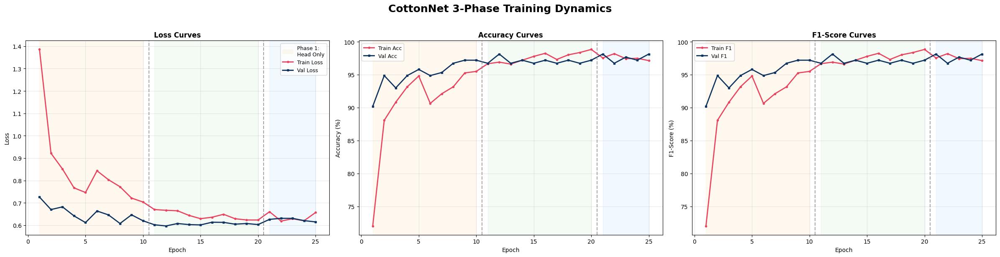

In [18]:
# ============================================================================
# COTTONNET LEARNING CURVES WITH PHASE BOUNDARIES
# ============================================================================
fig, axes = plt.subplots(1, 3, figsize=(24, 6))
fig.suptitle("CottonNet 3-Phase Training Dynamics", fontsize=18, fontweight='bold', y=1.02)

phases = kd_trainer.phase_boundaries + [len(kd_trainer.tr_losses)]
phase_names = ["Phase 1:\nHead Only", "Phase 2:\nPartial + KD", "Phase 3:\nFull + KD"]
phase_colors = ['#FFE0B2', '#C8E6C9', '#BBDEFB']

epoch_range = range(1, len(kd_trainer.tr_losses) + 1)

# Loss
for pi in range(len(phases)-1):
    axes[0].axvspan(phases[pi]+1, phases[pi+1], alpha=0.2, color=phase_colors[pi], label=phase_names[pi] if pi == 0 else None)
axes[0].plot(epoch_range, kd_trainer.tr_losses, 'o-', label='Train Loss', color='#e94560', linewidth=2, markersize=3)
axes[0].plot(epoch_range, kd_trainer.val_losses, 's-', label='Val Loss', color='#0f3460', linewidth=2, markersize=3)
for b in kd_trainer.phase_boundaries[1:]:
    axes[0].axvline(x=b+0.5, color='gray', linestyle='--', alpha=0.7)
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].set_title("Loss Curves", fontweight='bold')
axes[0].legend(fontsize=9); axes[0].grid(alpha=0.3)

# Accuracy
for pi in range(len(phases)-1):
    axes[1].axvspan(phases[pi]+1, phases[pi+1], alpha=0.2, color=phase_colors[pi])
axes[1].plot(epoch_range, [a*100 for a in kd_trainer.tr_accs], 'o-', label='Train Acc', color='#e94560', linewidth=2, markersize=3)
axes[1].plot(epoch_range, [a*100 for a in kd_trainer.val_accs], 's-', label='Val Acc', color='#0f3460', linewidth=2, markersize=3)
for b in kd_trainer.phase_boundaries[1:]:
    axes[1].axvline(x=b+0.5, color='gray', linestyle='--', alpha=0.7)
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy (%)"); axes[1].set_title("Accuracy Curves", fontweight='bold')
axes[1].legend(fontsize=9); axes[1].grid(alpha=0.3)

# F1
for pi in range(len(phases)-1):
    axes[2].axvspan(phases[pi]+1, phases[pi+1], alpha=0.2, color=phase_colors[pi])
axes[2].plot(epoch_range, [f*100 for f in kd_trainer.tr_f1s], 'o-', label='Train F1', color='#e94560', linewidth=2, markersize=3)
axes[2].plot(epoch_range, [f*100 for f in kd_trainer.val_f1s], 's-', label='Val F1', color='#0f3460', linewidth=2, markersize=3)
for b in kd_trainer.phase_boundaries[1:]:
    axes[2].axvline(x=b+0.5, color='gray', linestyle='--', alpha=0.7)
axes[2].set_xlabel("Epoch"); axes[2].set_ylabel("F1-Score (%)"); axes[2].set_title("F1-Score Curves", fontweight='bold')
axes[2].legend(fontsize=9); axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

<div style='background-color: #f5f0ff; border: 3px solid #7c3aed; border-radius: 10px; padding: 8px; text-align: center;'>
    <font size="+2" color="#7c3aed"><b>🏆 11. CottonNet vs All Models — Final Comparison 🏆</b></font>
</div>

Evaluating CottonNet on test set...


Testing CottonNet: 100%|██████████| 214/214 [00:03<00:00, 70.17it/s]


CottonNet Test Accuracy: 98.60%
CottonNet Test F1-Score: 98.60%

COTTONNET DETAILED CLASSIFICATION REPORT
                         precision    recall  f1-score   support

       Bacterial Blight     1.0000    0.9600    0.9796        25
             Curl Virus     1.0000    0.9767    0.9882        43
           Healthy Leaf     0.9630    1.0000    0.9811        26
Herbicide Growth Damage     1.0000    1.0000    1.0000        28
    Leaf Hopper Jassids     1.0000    0.9565    0.9778        23
           Leaf Redding     0.9667    1.0000    0.9831        58
       Leaf Variegation     1.0000    1.0000    1.0000        11

               accuracy                         0.9860       214
              macro avg     0.9899    0.9848    0.9871       214
           weighted avg     0.9865    0.9860    0.9860       214



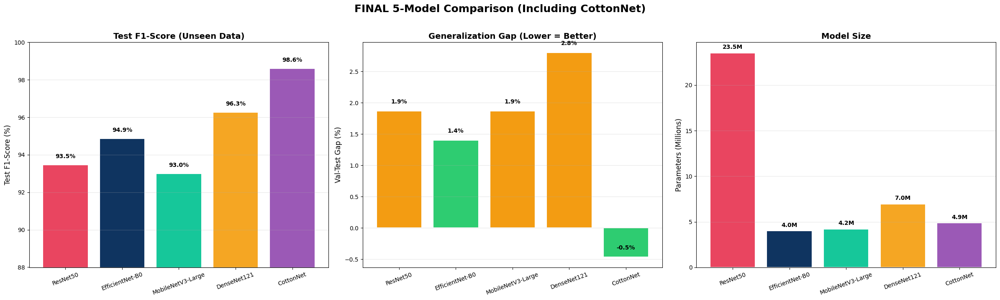

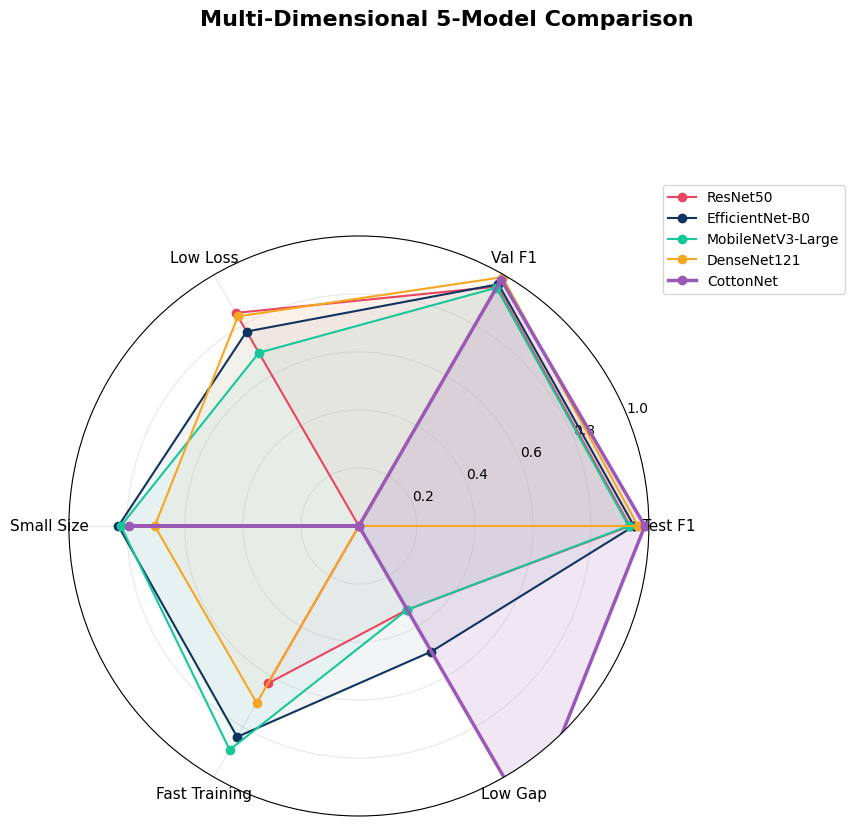

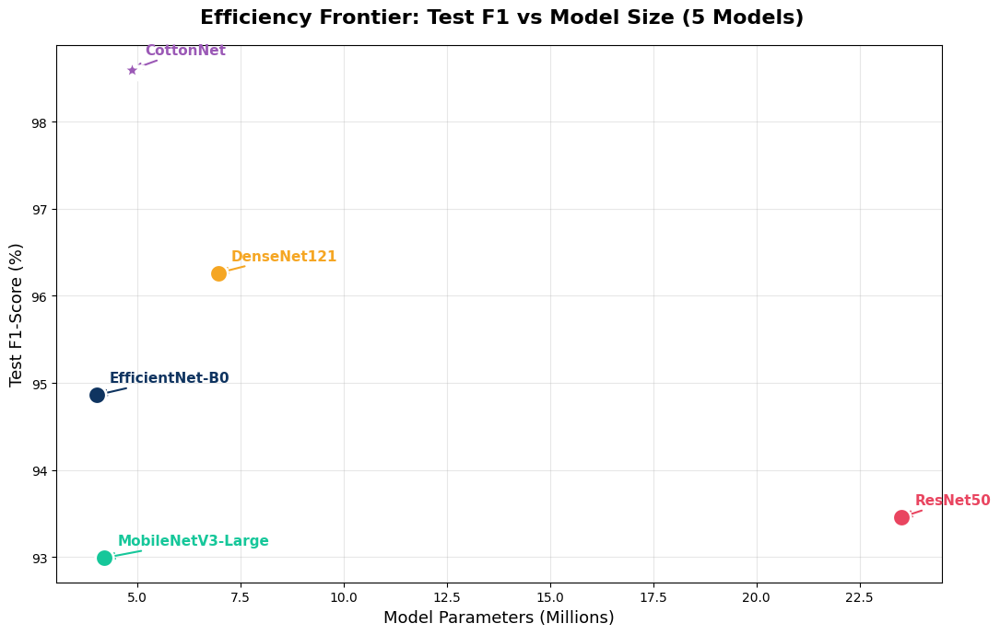


                                     FINAL 5-MODEL COMPARISON (INCLUDING COTTONNET)                                     
Model                    Val F1 (%)   Test F1 (%)    Gap (%)   Params (M)  Trainable (M)   Time (min)   Epochs
------------------------------------------------------------------------------------------------------------------------
ResNet50                      95.33         93.46       1.87        23.52          23.52          2.6        8
EfficientNet-B0               96.26         94.86       1.40         4.02           4.02          1.1        6
MobileNetV3-Large             94.86         92.99       1.87         4.21           4.21          0.8        5
DenseNet121                   99.07         96.26       2.80         6.96           6.96          2.0        6
CottonNet                     98.13         98.60      -0.47         4.87           4.56          6.9       25
-------------------------------------------------------------------------------------------

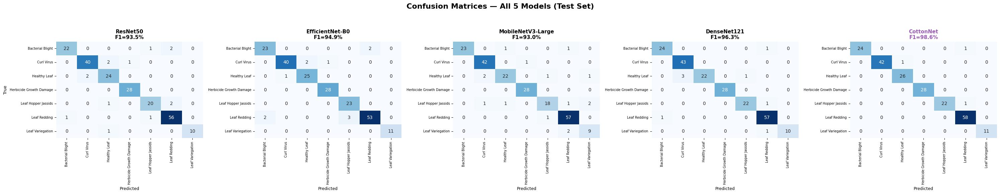

In [19]:
# ============================================================================
# TEST COTTONNET ON TEST SET
# ============================================================================
print("Evaluating CottonNet on test set...")

cotton_model = CottonNet(num_classes=len(classes)).to(device)
cotton_model.load_state_dict(torch.load(f"{save_dir}/cottonnet_best_model.pth"))
cotton_model.eval()

f1_metric = torchmetrics.F1Score(task="multiclass", num_classes=len(classes)).to(device)
cotton_preds, cotton_labels = [], []
correct = 0

with torch.no_grad():
    for batch in tqdm(ts_dl, desc="Testing CottonNet"):
        ims, gts = batch[0].to(device), batch[1].to(device)
        logits = cotton_model(ims)
        pred_class = torch.argmax(logits, dim=1)
        correct += (pred_class == gts).sum().item()
        f1_metric.update(logits, gts)
        cotton_preds.extend(pred_class.cpu().numpy())
        cotton_labels.extend(gts.cpu().numpy())

cotton_test_acc = correct / len(ts_dl.dataset)
cotton_test_f1 = f1_metric.compute().item()

# Add CottonNet to test_results
test_results["CottonNet"] = {
    "test_acc": cotton_test_acc,
    "test_f1": cotton_test_f1,
    "preds": cotton_preds,
    "labels": cotton_labels,
}

print(f"CottonNet Test Accuracy: {cotton_test_acc*100:.2f}%")
print(f"CottonNet Test F1-Score: {cotton_test_f1*100:.2f}%")

# Classification Report
class_names_list = list(classes.keys())
print(f"\n{'='*60}")
print("COTTONNET DETAILED CLASSIFICATION REPORT")
print(f"{'='*60}")
print(classification_report(cotton_labels, cotton_preds, target_names=class_names_list, digits=4))

# ============================================================================
# COMPREHENSIVE COMPARISON: ALL 5 MODELS
# ============================================================================
all_model_names = list(all_results.keys())

MODEL_COLORS_FULL = {
    "ResNet50":           "#e94560",
    "EfficientNet-B0":    "#0f3460",
    "MobileNetV3-Large":  "#16c79a",
    "DenseNet121":        "#f5a623",
    "CottonNet":          "#9b59b6",  # Purple for our custom model
}

colors_full = [MODEL_COLORS_FULL.get(n, "#888") for n in all_model_names]

# --- BAR CHARTS: Test F1 + Val F1 + Params ---
fig, axes = plt.subplots(1, 3, figsize=(24, 7))
fig.suptitle("FINAL 5-Model Comparison (Including CottonNet)", fontsize=18, fontweight='bold', y=1.02)

# Test F1
test_f1s = [test_results[n]['test_f1'] * 100 if n in test_results else 0 for n in all_model_names]
bars = axes[0].bar(all_model_names, test_f1s, color=colors_full, edgecolor='white', linewidth=1.5)
axes[0].set_ylabel("Test F1-Score (%)", fontsize=12)
axes[0].set_title("Test F1-Score (Unseen Data)", fontsize=14, fontweight='bold')
axes[0].set_ylim([min(test_f1s) - 5, 100])
for bar, val in zip(bars, test_f1s):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3, f"{val:.1f}%",
                ha='center', va='bottom', fontweight='bold', fontsize=10)
axes[0].tick_params(axis='x', rotation=20)
axes[0].grid(axis='y', alpha=0.3)

# Val-Test Gap
gaps = [(all_results[n]['best_val_f1'] - test_results[n]['test_f1']) * 100 if n in test_results else 0 for n in all_model_names]
bar_colors = ['#e74c3c' if g > 3 else '#f39c12' if g > 1.5 else '#2ecc71' for g in gaps]
bars = axes[1].bar(all_model_names, gaps, color=bar_colors, edgecolor='white', linewidth=1.5)
axes[1].set_ylabel("Val-Test Gap (%)", fontsize=12)
axes[1].set_title("Generalization Gap (Lower = Better)", fontsize=14, fontweight='bold')
for bar, val in zip(bars, gaps):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1, f"{val:.1f}%",
                ha='center', va='bottom', fontweight='bold', fontsize=10)
axes[1].tick_params(axis='x', rotation=20)
axes[1].grid(axis='y', alpha=0.3)

# Parameters
params = [all_results[n]['num_params'] / 1e6 for n in all_model_names]
bars = axes[2].bar(all_model_names, params, color=colors_full, edgecolor='white', linewidth=1.5)
axes[2].set_ylabel("Parameters (Millions)", fontsize=12)
axes[2].set_title("Model Size", fontsize=14, fontweight='bold')
for bar, val in zip(bars, params):
    axes[2].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3, f"{val:.1f}M",
                ha='center', va='bottom', fontweight='bold', fontsize=10)
axes[2].tick_params(axis='x', rotation=20)
axes[2].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# --- RADAR CHART: 5 Models ---
from math import pi
categories = ['Test F1', 'Val F1', 'Low Loss', 'Small Size', 'Fast Training', 'Low Gap']
N = len(categories)

max_params = max(all_results[n]['num_params'] for n in all_model_names)
max_time = max(all_results[n]['training_time'] for n in all_model_names)
max_loss = max(all_results[n]['best_val_loss'] for n in all_model_names)
max_gap = max(gaps) if max(gaps) > 0 else 1

fig, ax = plt.subplots(figsize=(9, 9), subplot_kw=dict(polar=True))
fig.suptitle("Multi-Dimensional 5-Model Comparison", fontsize=16, fontweight='bold', y=1.02)

angles = [n / float(N) * 2 * pi for n in range(N)]
angles += angles[:1]

for idx, name in enumerate(all_model_names):
    res = all_results[name]
    gap_val = gaps[idx]
    test_f1_val = test_results[name]['test_f1'] if name in test_results else 0
    values = [
        test_f1_val,
        res['best_val_f1'],
        1 - (res['best_val_loss'] / max_loss) if max_loss > 0 else 1,
        1 - (res['num_params'] / max_params),
        1 - (res['training_time'] / max_time) if max_time > 0 else 1,
        1 - (gap_val / max_gap) if max_gap > 0 else 1,
    ]
    values += values[:1]
    
    ax.plot(angles, values, 'o-', linewidth=2.5 if name == 'CottonNet' else 1.5,
            label=name, color=MODEL_COLORS_FULL.get(name))
    ax.fill(angles, values, alpha=0.15 if name == 'CottonNet' else 0.05,
            color=MODEL_COLORS_FULL.get(name))

ax.set_xticks(angles[:-1])
ax.set_xticklabels(categories, fontsize=11)
ax.set_ylim(0, 1)
ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1.1), fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# --- SCATTER: F1 vs Params (Efficiency Frontier) ---
fig, ax = plt.subplots(figsize=(11, 7))
fig.suptitle("Efficiency Frontier: Test F1 vs Model Size (5 Models)", fontsize=16, fontweight='bold')

for name in all_model_names:
    res = all_results[name]
    tf1 = test_results[name]['test_f1'] * 100 if name in test_results else 0
    marker_size = 350 if name == 'CottonNet' else 200
    edge_width = 3 if name == 'CottonNet' else 2
    ax.scatter(res['num_params']/1e6, tf1,
              s=marker_size, c=MODEL_COLORS_FULL.get(name), edgecolors='white',
              linewidth=edge_width, zorder=5, marker='*' if name == 'CottonNet' else 'o')
    offset_y = 12 if name == 'CottonNet' else 10
    ax.annotate(name, (res['num_params']/1e6, tf1),
               textcoords="offset points", xytext=(10, offset_y), fontsize=11,
               fontweight='bold', color=MODEL_COLORS_FULL.get(name),
               arrowprops=dict(arrowstyle='->', color=MODEL_COLORS_FULL.get(name), lw=1.5))

ax.set_xlabel("Model Parameters (Millions)", fontsize=13)
ax.set_ylabel("Test F1-Score (%)", fontsize=13)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# --- FINAL SUMMARY TABLE ---
print("\n" + "="*120)
print(f"{'FINAL 5-MODEL COMPARISON (INCLUDING COTTONNET)':^120}")
print("="*120)
print(f"{'Model':<22} {'Val F1 (%)':>12} {'Test F1 (%)':>13} {'Gap (%)':>10} {'Params (M)':>12} {'Trainable (M)':>14} {'Time (min)':>12} {'Epochs':>8}")
print("-"*120)

for name in all_model_names:
    res = all_results[name]
    tf1 = test_results[name]['test_f1'] * 100 if name in test_results else 0
    gap = (res['best_val_f1'] * 100) - tf1
    trainable = res.get('trainable_params', res['num_params'])
    print(f"{name:<22} {res['best_val_f1']*100:>12.2f} {tf1:>13.2f} {gap:>10.2f} "
          f"{res['num_params']/1e6:>12.2f} {trainable/1e6:>14.2f} {res['training_time']/60:>12.1f} {res['epochs_trained']:>8}")

print("-"*120)
best_test = max(test_results, key=lambda k: test_results[k]['test_f1'])
print(f"\n🏆 BEST ON TEST SET: {best_test} (Test F1 = {test_results[best_test]['test_f1']*100:.2f}%)")
if 'CottonNet' in test_results:
    cotton_gap = (all_results['CottonNet']['best_val_f1'] - test_results['CottonNet']['test_f1']) * 100
    print(f"🧠 COTTONNET: Test F1 = {test_results['CottonNet']['test_f1']*100:.2f}% | "
          f"Val-Test Gap = {cotton_gap:.2f}% | "
          f"Params = {all_results['CottonNet']['num_params']/1e6:.2f}M")

# --- CONFUSION MATRICES GRID (5 models) ---
fig, axes = plt.subplots(1, len(all_model_names), figsize=(6*len(all_model_names), 5.5))
fig.suptitle("Confusion Matrices — All 5 Models (Test Set)", fontsize=16, fontweight='bold', y=1.05)

for idx, name in enumerate(all_model_names):
    if name not in test_results:
        continue
    cm = confusion_matrix(test_results[name]['labels'], test_results[name]['preds'])
    ax = axes[idx]
    sns.heatmap(cm, annot=True, fmt='d', xticklabels=class_names_list, yticklabels=class_names_list,
                cmap='Blues', ax=ax, cbar=False)
    tf1 = test_results[name]['test_f1'] * 100
    ax.set_title(f"{name}\nF1={tf1:.1f}%", fontsize=11, fontweight='bold',
                color='#9b59b6' if name == 'CottonNet' else 'black')
    ax.set_xlabel("Predicted", fontsize=9)
    if idx == 0:
        ax.set_ylabel("True", fontsize=9)
    else:
        ax.set_ylabel("")
    ax.tick_params(labelsize=7)

plt.tight_layout()
plt.show()

<div style='background-color: #fff0db; border: 3px solid #FFA07A; border-radius: 10px; padding: 6px; text-align: center;'>
    <font size="+1.8" color="#FF4500"><b>🔍 12. CottonNet GradCAM & Explainability 🔍</b></font>
</div>

Loading CottonNet for GradCAM visualization...


Inference: 214it [00:03, 67.98it/s]



Accuracy of the model on the test data -> 0.986
F1 score of the model on the test data -> 0.986

DETAILED CLASSIFICATION REPORT
                         precision    recall  f1-score   support

       Bacterial Blight     1.0000    0.9600    0.9796        25
             Curl Virus     1.0000    0.9767    0.9882        43
           Healthy Leaf     0.9630    1.0000    0.9811        26
Herbicide Growth Damage     1.0000    1.0000    1.0000        28
    Leaf Hopper Jassids     1.0000    0.9565    0.9778        23
           Leaf Redding     0.9667    1.0000    0.9831        58
       Leaf Variegation     1.0000    1.0000    1.0000        11

               accuracy                         0.9860       214
              macro avg     0.9899    0.9848    0.9871       214
           weighted avg     0.9865    0.9860    0.9860       214



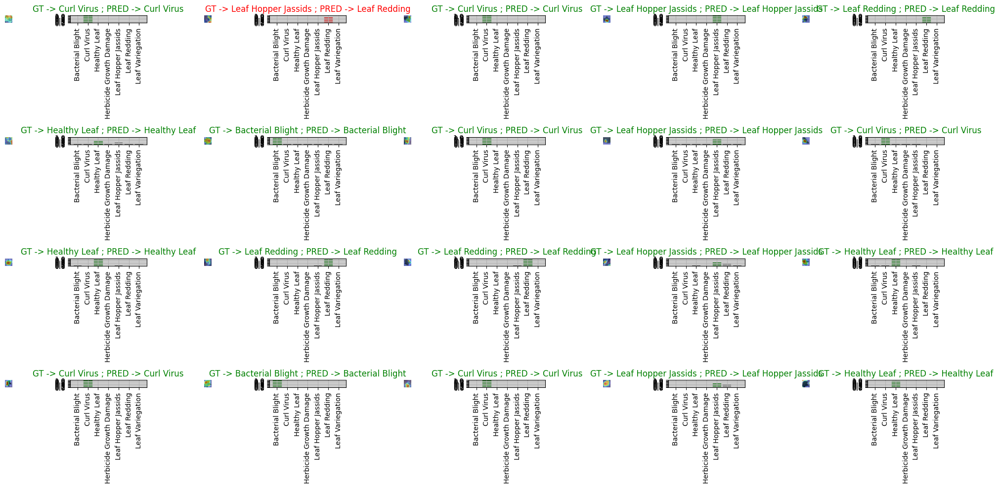

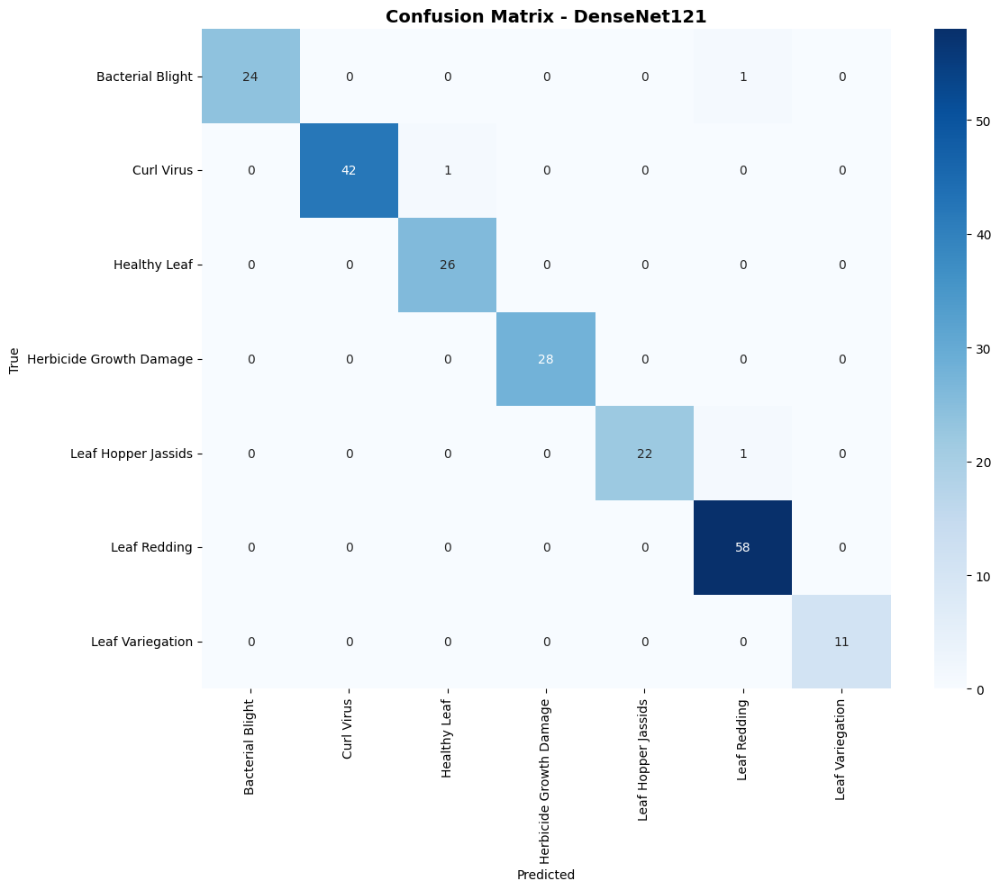

In [20]:
# ============================================================================
# COTTONNET GRADCAM VISUALIZATION
# ============================================================================
class CottonNetInferenceVisualizer(ModelInferenceVisualizer):
    """Adapted inference visualizer for CottonNet architecture."""
    
    def generate_cam_visualization(self, image_tensor):
        target_layers = self.model.get_gradcam_target_layer()
        cam = GradCAMPlusPlus(model=self.model, target_layers=target_layers)
        input_t = image_tensor.unsqueeze(0).to(self.device)
        grayscale_cam = cam(input_tensor=input_t)[0, :]
        return grayscale_cam

print("Loading CottonNet for GradCAM visualization...")
cotton_model = CottonNet(num_classes=len(classes)).to(device)
cotton_model.load_state_dict(torch.load(f"{save_dir}/cottonnet_best_model.pth"))

cotton_visualizer = CottonNetInferenceVisualizer(
    model=cotton_model,
    device=device,
    timm_name="cottonnet_custom",
    class_names=list(classes.keys()),
    im_size=im_size
)

test_acc, test_f1 = cotton_visualizer.infer_and_visualize(ts_dl, num_images=20, rows=4)

del cotton_model
torch.cuda.empty_cache() if torch.cuda.is_available() else None

<div style='background-color: #0d1117; border: 3px solid #f0883e; border-radius: 12px; padding: 20px; text-align: center;'>
    <font size='+3' color='#f0883e'><b>🔬 Part II — Extended Model Comparison Study 🔬</b></font><br>
    <font size='+1' color='#8b949e'><b>CottonNet V2 · YOLO26s-cls · Swin-T · ViT-B/16</b></font>
</div>

### Objective
Extend the benchmark with **four additional models** to strengthen the research paper:
1. **CottonNet V2** — Same CottonNet architecture + realistic illumination/image-quality augmentations during training
2. **YOLO26s Classification** — Ultralytics YOLO26s pretrained classifier, fine-tuned for 7 cotton leaf classes
3. **Swin Transformer Tiny** — Shifted-window ViT (hierarchical), pretrained on ImageNet-1K
4. **ViT-Base/16** — Standard Vision Transformer with 16×16 patches, pretrained on ImageNet-21K

All models use the **same existing train/validation/test split** and **7 disease classes**.
Results are saved to `/kaggle/working/CottonCare_Research/`.

<div style='background-color: #1c1c3a; border: 3px solid #58a6ff; border-radius: 10px; padding: 8px; text-align: center;'>
    <font size='+2' color='#58a6ff'><b>📦 13. Install Extended Dependencies 📦</b></font>
</div>

In [21]:
# ============================================================================
# INSTALL ADDITIONAL DEPENDENCIES FOR EXTENDED RESEARCH
# ============================================================================
!pip install -q ultralytics>=8.3.0 albumentations>=1.4.0

import albumentations as A
from albumentations.pytorch import ToTensorV2
import cv2
import timm
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchmetrics
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os, time, copy, json
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import confusion_matrix, classification_report
from tqdm import tqdm

# Output directory for all extended research artifacts
RESEARCH_DIR = "/kaggle/working/CottonCare_Research"
os.makedirs(RESEARCH_DIR, exist_ok=True)
os.makedirs(f"{RESEARCH_DIR}/models", exist_ok=True)
os.makedirs(f"{RESEARCH_DIR}/results", exist_ok=True)
os.makedirs(f"{RESEARCH_DIR}/figures", exist_ok=True)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {device}")
print(f"Research output dir: {RESEARCH_DIR}")
print(f"Classes from V1: {classes}")
print(f"Number of classes: {len(classes)}")

Device: cuda
Research output dir: /kaggle/working/CottonCare_Research
Classes from V1: {'Bacterial Blight': 0, 'Curl Virus': 1, 'Healthy Leaf': 2, 'Herbicide Growth Damage': 3, 'Leaf Hopper Jassids': 4, 'Leaf Redding': 5, 'Leaf Variegation': 6}
Number of classes: 7


<div style='background-color: #1a1a2e; border: 3px solid #e94560; border-radius: 10px; padding: 8px; text-align: center;'>
    <font size='+2' color='#e94560'><b>🎨 14. Realistic Field Augmentation Pipeline (V2 Training) 🎨</b></font>
</div>

Simulates real-world smartphone capture conditions in the cotton field:
- **Illumination**: brightness, contrast, gamma shifts, random shadows
- **Color**: mild hue/saturation perturbations
- **Degradation**: Gaussian blur, ISO noise, JPEG compression artifacts
- **Geometry**: rotation, horizontal/vertical flip

Applied to training data **only**. Validation and test sets use the original transforms.

In [22]:
# ============================================================================
# REALISTIC FIELD AUGMENTATION — Albumentations Pipeline
# ============================================================================

class AlbumentationsDataset(Dataset):
    """
    Wraps the existing split's (im_paths, im_lbls) with Albumentations transforms.
    Reuses the EXACT same file paths and labels from the V1 split.
    """
    def __init__(self, im_paths, im_lbls, transform=None, normalize_mean=None, normalize_std=None):
        self.im_paths = im_paths
        self.im_lbls  = im_lbls
        self.transform = transform
        self.normalize_mean = normalize_mean or [0.485, 0.456, 0.406]
        self.normalize_std  = normalize_std  or [0.229, 0.224, 0.225]

    def __len__(self):
        return len(self.im_paths)

    def __getitem__(self, idx):
        img = np.array(Image.open(self.im_paths[idx]).convert('RGB'))
        label = self.im_lbls[idx]
        if self.transform:
            img = self.transform(image=img)['image']
        return img, label


# --- V2 Training augmentation ---
v2_train_transform = A.Compose([
    A.Resize(im_size, im_size),

    # Geometric
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.3),
    A.RandomRotate90(p=0.3),
    A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.1, rotate_limit=30,
                       border_mode=cv2.BORDER_REFLECT_101, p=0.4),

    # Illumination & Color
    A.OneOf([
        A.RandomBrightnessContrast(brightness_limit=0.3, contrast_limit=0.3, p=1.0),
        A.RandomGamma(gamma_limit=(70, 130), p=1.0),
        A.RandomToneCurve(scale=0.15, p=1.0),
    ], p=0.6),

    A.HueSaturationValue(hue_shift_limit=10, sat_shift_limit=20, val_shift_limit=15, p=0.3),
    A.RandomShadow(shadow_roi=(0, 0.5, 1, 1), num_shadows_limit=(1, 3),
                   shadow_dimension=5, p=0.2),

    # Degradation
    A.OneOf([
        A.GaussianBlur(blur_limit=(3, 5), p=1.0),
        A.MotionBlur(blur_limit=5, p=1.0),
    ], p=0.2),

    A.GaussNoise(var_limit=(5.0, 30.0), p=0.2),
    A.ImageCompression(quality_lower=60, quality_upper=95, p=0.2),

    # Normalize + to tensor
    A.Normalize(mean=mean, std=std),
    ToTensorV2(),
])

# --- Standard eval transform (no augmentation) ---
eval_transform = A.Compose([
    A.Resize(im_size, im_size),
    A.Normalize(mean=mean, std=std),
    ToTensorV2(),
])

print("V2 Training augmentation pipeline created.")
print("Eval transform (for val/test): Resize + Normalize only.")

V2 Training augmentation pipeline created.
Eval transform (for val/test): Resize + Normalize only.


<div style='background-color: #f0f9e8; border: 3px solid #4CAF50; border-radius: 10px; padding: 8px; text-align: center;'>
    <font size='+2' color='#4CAF50'><b>🖼️ 14b. Augmented Sample Visualization 🖼️</b></font>
</div>

Preview how the V2 augmentation pipeline transforms real training images.

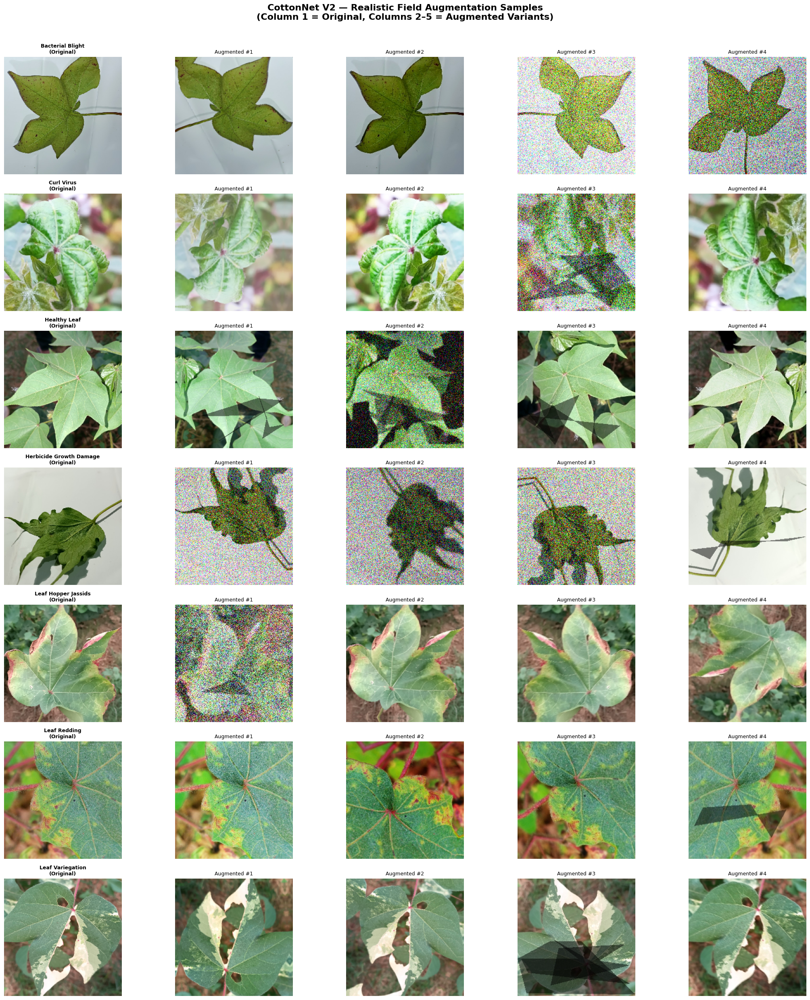

Saved to /kaggle/working/CottonCare_Research/figures/v2_augmentation_samples.png


In [23]:
# ============================================================================
# VISUALIZE AUGMENTED SAMPLES — before vs after
# ============================================================================

# Extract paths from existing training dataloader
train_paths = tr_dl.dataset.im_paths
train_labels = tr_dl.dataset.im_lbls
class_names = list(classes.keys())

# Augmented-only transform for visualization (without Normalize/ToTensor)
vis_aug = A.Compose([
    A.Resize(im_size, im_size),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.3),
    A.RandomRotate90(p=0.3),
    A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.1, rotate_limit=30,
                       border_mode=cv2.BORDER_REFLECT_101, p=0.5),
    A.OneOf([
        A.RandomBrightnessContrast(brightness_limit=0.3, contrast_limit=0.3, p=1.0),
        A.RandomGamma(gamma_limit=(70, 130), p=1.0),
        A.RandomToneCurve(scale=0.15, p=1.0),
    ], p=0.7),
    A.HueSaturationValue(hue_shift_limit=10, sat_shift_limit=20, val_shift_limit=15, p=0.4),
    A.RandomShadow(shadow_roi=(0, 0.5, 1, 1), num_shadows_limit=(1, 3),
                   shadow_dimension=5, p=0.3),
    A.OneOf([
        A.GaussianBlur(blur_limit=(3, 5), p=1.0),
        A.MotionBlur(blur_limit=5, p=1.0),
    ], p=0.3),
    A.GaussNoise(var_limit=(5.0, 30.0), p=0.3),
    A.ImageCompression(quality_lower=60, quality_upper=95, p=0.3),
])

# Pick one sample per class
fig, axes = plt.subplots(len(class_names), 5, figsize=(22, len(class_names) * 3.5))
fig.suptitle('CottonNet V2 — Realistic Field Augmentation Samples\n(Column 1 = Original, Columns 2–5 = Augmented Variants)',
             fontsize=16, fontweight='bold', y=1.01)

for cls_idx, cls_name in enumerate(class_names):
    # Find first image of this class
    sample_idx = next(i for i, l in enumerate(train_labels) if l == classes[cls_name])
    orig_img = np.array(Image.open(train_paths[sample_idx]).convert('RGB'))
    orig_resized = A.Resize(im_size, im_size)(image=orig_img)['image']

    # Original
    axes[cls_idx, 0].imshow(orig_resized)
    axes[cls_idx, 0].set_title(f'{cls_name}\n(Original)', fontsize=9, fontweight='bold')
    axes[cls_idx, 0].axis('off')

    # 4 augmented variants
    for aug_idx in range(1, 5):
        augmented = vis_aug(image=orig_img)['image']
        axes[cls_idx, aug_idx].imshow(augmented)
        axes[cls_idx, aug_idx].set_title(f'Augmented #{aug_idx}', fontsize=9)
        axes[cls_idx, aug_idx].axis('off')

plt.tight_layout()
plt.savefig(f"{RESEARCH_DIR}/figures/v2_augmentation_samples.png", dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved to {RESEARCH_DIR}/figures/v2_augmentation_samples.png")

<div style='background-color: #e6f7ff; border: 3px solid #007acc; border-radius: 10px; padding: 8px; text-align: center;'>
    <font size='+2' color='#007acc'><b>⚙️ 14c. Build Dataloaders for Extended Models ⚙️</b></font>
</div>

Create augmented training dataloaders using the **exact same file paths** from the V1 split.

In [24]:
# ============================================================================
# DATALOADERS — reusing exact V1 split paths
# ============================================================================

# V2 augmented training data
v2_train_ds = AlbumentationsDataset(
    im_paths=train_paths,
    im_lbls=train_labels,
    transform=v2_train_transform
)
v2_train_dl = DataLoader(v2_train_ds, batch_size=bs, shuffle=True, num_workers=4, pin_memory=True)

# Eval datasets with standard transforms (same paths as V1)
v2_val_ds = AlbumentationsDataset(
    im_paths=val_dl.dataset.im_paths,
    im_lbls=val_dl.dataset.im_lbls,
    transform=eval_transform
)
v2_val_dl = DataLoader(v2_val_ds, batch_size=bs, shuffle=False, num_workers=4, pin_memory=True)

v2_test_ds = AlbumentationsDataset(
    im_paths=ts_dl.dataset.im_paths,
    im_lbls=ts_dl.dataset.im_lbls,
    transform=eval_transform
)
v2_test_dl = DataLoader(v2_test_ds, batch_size=1, shuffle=False, num_workers=4)

print(f"V2 Train: {len(v2_train_ds)} images, {len(v2_train_dl)} batches")
print(f"V2 Val:   {len(v2_val_ds)} images, {len(v2_val_dl)} batches")
print(f"V2 Test:  {len(v2_test_ds)} images, {len(v2_test_dl)} batches")
print(f"\nSplit integrity check: train={len(train_paths)}, val={len(val_dl.dataset.im_paths)}, test={len(ts_dl.dataset.im_paths)}")

V2 Train: 1709 images, 107 batches
V2 Val:   214 images, 14 batches
V2 Test:  214 images, 214 batches

Split integrity check: train=1709, val=214, test=214


<div style='background-color: #f5f0ff; border: 3px solid #7c3aed; border-radius: 10px; padding: 8px; text-align: center;'>
    <font size='+2' color='#7c3aed'><b>🛠️ 15. Unified Training & Evaluation Framework 🛠️</b></font>
</div>

A single training loop used by CottonNet V2, Swin-T, and ViT-B/16.
Tracks: loss, accuracy, macro F1, top-3 accuracy, inference time, parameter count.

In [25]:
# ============================================================================
# UNIFIED TRAINER FOR EXTENDED MODELS
# ============================================================================

class ExtendedTrainer:
    """
    Generic trainer with comprehensive metrics:
    - Accuracy, Precision, Recall, Macro F1, Weighted F1, Top-3 Accuracy
    - Parameter count, inference time
    - Confusion matrix, classification report
    """
    def __init__(self, model, model_name, train_dl, val_dl, num_classes,
                 device, save_dir, lr=1e-4, epochs=30, patience=5,
                 label_smoothing=0.1, weight_decay=1e-4, scheduler_type='cosine'):
        self.model = model.to(device)
        self.model_name = model_name
        self.train_dl = train_dl
        self.val_dl = val_dl
        self.num_classes = num_classes
        self.device = device
        self.save_dir = save_dir
        self.lr = lr
        self.epochs = epochs
        self.patience = patience

        # Loss
        self.criterion = nn.CrossEntropyLoss(label_smoothing=label_smoothing)

        # Optimizer
        self.optimizer = torch.optim.AdamW(
            filter(lambda p: p.requires_grad, self.model.parameters()),
            lr=lr, weight_decay=weight_decay
        )

        # Scheduler
        if scheduler_type == 'cosine':
            self.scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
                self.optimizer, T_max=epochs, eta_min=1e-6
            )
        else:
            self.scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
                self.optimizer, mode='min', factor=0.5, patience=3
            )

        self.scheduler_type = scheduler_type

        # Metrics
        self.f1_macro = torchmetrics.F1Score(task='multiclass', num_classes=num_classes, average='macro').to(device)
        self.f1_weighted = torchmetrics.F1Score(task='multiclass', num_classes=num_classes, average='weighted').to(device)
        self.precision_metric = torchmetrics.Precision(task='multiclass', num_classes=num_classes, average='macro').to(device)
        self.recall_metric = torchmetrics.Recall(task='multiclass', num_classes=num_classes, average='macro').to(device)

        # History
        self.tr_losses, self.val_losses = [], []
        self.tr_accs, self.val_accs = [], []
        self.tr_f1s, self.val_f1s = [], []

        # Best tracking
        self.best_val_f1 = 0
        self.best_epoch = 0
        self.not_improved = 0

        # Parameter count
        self.total_params = sum(p.numel() for p in self.model.parameters())
        self.trainable_params = sum(p.numel() for p in self.model.parameters() if p.requires_grad)

        os.makedirs(save_dir, exist_ok=True)
        print(f"[{model_name}] Total params: {self.total_params/1e6:.2f}M | Trainable: {self.trainable_params/1e6:.2f}M")

    def train_one_epoch(self):
        self.model.train()
        running_loss, correct, total = 0.0, 0, 0
        self.f1_macro.reset()

        for images, labels in tqdm(self.train_dl, desc=f"Train {self.model_name}", leave=False):
            images, labels = images.to(self.device), labels.to(self.device)
            self.optimizer.zero_grad()
            outputs = self.model(images)
            loss = self.criterion(outputs, labels)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(self.model.parameters(), max_norm=1.0)
            self.optimizer.step()

            running_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
            self.f1_macro.update(outputs, labels)

        epoch_loss = running_loss / total
        epoch_acc = correct / total
        epoch_f1 = self.f1_macro.compute().item()
        return epoch_loss, epoch_acc, epoch_f1

    @torch.no_grad()
    def validate_one_epoch(self):
        self.model.eval()
        running_loss, correct, total = 0.0, 0, 0
        self.f1_macro.reset()

        for images, labels in tqdm(self.val_dl, desc=f"Val {self.model_name}", leave=False):
            images, labels = images.to(self.device), labels.to(self.device)
            outputs = self.model(images)
            loss = self.criterion(outputs, labels)

            running_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
            self.f1_macro.update(outputs, labels)

        epoch_loss = running_loss / total
        epoch_acc = correct / total
        epoch_f1 = self.f1_macro.compute().item()
        return epoch_loss, epoch_acc, epoch_f1

    def train(self):
        print(f"\n{'='*70}")
        print(f"  Training: {self.model_name} for {self.epochs} epochs")
        print(f"{'='*70}")

        start_time = time.time()
        for epoch in range(self.epochs):
            tr_loss, tr_acc, tr_f1 = self.train_one_epoch()
            val_loss, val_acc, val_f1 = self.validate_one_epoch()

            self.tr_losses.append(tr_loss)
            self.val_losses.append(val_loss)
            self.tr_accs.append(tr_acc)
            self.val_accs.append(val_acc)
            self.tr_f1s.append(tr_f1)
            self.val_f1s.append(val_f1)

            # Scheduler step
            if self.scheduler_type == 'cosine':
                self.scheduler.step()
            else:
                self.scheduler.step(val_loss)

            # Save best
            if val_f1 > self.best_val_f1:
                self.best_val_f1 = val_f1
                self.best_epoch = epoch + 1
                self.not_improved = 0
                save_path = f"{self.save_dir}/{self.model_name.lower().replace(' ', '_').replace('-', '_').replace('/', '_')}_best_model.pth"
                torch.save(self.model.state_dict(), save_path)
            else:
                self.not_improved += 1

            lr_now = self.optimizer.param_groups[0]['lr']
            print(f"  Epoch {epoch+1:3d}/{self.epochs} | "
                  f"Train Loss: {tr_loss:.4f} Acc: {tr_acc:.4f} F1: {tr_f1:.4f} | "
                  f"Val Loss: {val_loss:.4f} Acc: {val_acc:.4f} F1: {val_f1:.4f} | "
                  f"LR: {lr_now:.2e} | {'★ BEST' if self.not_improved == 0 else ''}")

            if self.not_improved >= self.patience:
                print(f"  Early stopping at epoch {epoch+1} (no improvement for {self.patience} epochs)")
                break

        self.training_time = time.time() - start_time
        print(f"\n  {self.model_name} training complete in {self.training_time/60:.1f} min")
        print(f"  Best Val F1: {self.best_val_f1:.4f} at epoch {self.best_epoch}")
        return self.training_time

    @torch.no_grad()
    def evaluate_test(self, test_dl, class_names):
        """
        Full test-set evaluation with all requested metrics.
        Returns a results dict.
        """
        # Load best checkpoint
        ckpt_path = f"{self.save_dir}/{self.model_name.lower().replace(' ', '_').replace('-', '_').replace('/', '_')}_best_model.pth"
        if os.path.exists(ckpt_path):
            self.model.load_state_dict(torch.load(ckpt_path, map_location=self.device))
        self.model.eval()

        all_preds, all_labels, all_probs = [], [], []
        inference_times = []

        for images, labels in tqdm(test_dl, desc=f"Test {self.model_name}", leave=False):
            images = images.to(self.device)

            t0 = time.time()
            outputs = self.model(images)
            torch.cuda.synchronize() if torch.cuda.is_available() else None
            inference_times.append(time.time() - t0)

            probs = F.softmax(outputs, dim=1)
            preds = outputs.argmax(1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())
            all_probs.append(probs.cpu().numpy())

        all_preds = np.array(all_preds)
        all_labels = np.array(all_labels)
        all_probs = np.concatenate(all_probs, axis=0)

        # Accuracy
        accuracy = (all_preds == all_labels).mean()

        # Top-3 accuracy
        top3_preds = np.argsort(all_probs, axis=1)[:, -3:]
        top3_correct = sum(1 for i in range(len(all_labels)) if all_labels[i] in top3_preds[i])
        top3_accuracy = top3_correct / len(all_labels)

        # Classification report
        report = classification_report(all_labels, all_preds, target_names=class_names,
                                       output_dict=True, zero_division=0)

        # Avg inference time
        avg_inference_ms = np.mean(inference_times) * 1000

        results = {
            'model_name': self.model_name,
            'accuracy': accuracy,
            'precision_macro': report['macro avg']['precision'],
            'recall_macro': report['macro avg']['recall'],
            'f1_macro': report['macro avg']['f1-score'],
            'f1_weighted': report['weighted avg']['f1-score'],
            'top3_accuracy': top3_accuracy,
            'total_params': self.total_params,
            'trainable_params': self.trainable_params,
            'avg_inference_ms': avg_inference_ms,
            'training_time_min': self.training_time / 60,
            'best_epoch': self.best_epoch,
            'epochs_trained': len(self.tr_losses),
            'all_preds': all_preds,
            'all_labels': all_labels,
            'report': report,
            'report_str': classification_report(all_labels, all_preds, target_names=class_names, zero_division=0),
        }

        print(f"\n{'='*60}")
        print(f"  {self.model_name} — Test Set Results")
        print(f"{'='*60}")
        print(f"  Accuracy:      {accuracy:.4f}")
        print(f"  Precision:     {results['precision_macro']:.4f}")
        print(f"  Recall:        {results['recall_macro']:.4f}")
        print(f"  Macro F1:      {results['f1_macro']:.4f}")
        print(f"  Weighted F1:   {results['f1_weighted']:.4f}")
        print(f"  Top-3 Acc:     {top3_accuracy:.4f}")
        print(f"  Params:        {self.total_params/1e6:.2f}M")
        print(f"  Inference:     {avg_inference_ms:.2f} ms/image")
        print(f"\n{results['report_str']}")

        return results


def plot_confusion_matrix(labels, preds, class_names, model_name, save_dir):
    """Plot and save confusion matrix."""
    cm = confusion_matrix(labels, preds)
    fig, ax = plt.subplots(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names,
                yticklabels=class_names, ax=ax, linewidths=0.5, linecolor='gray')
    ax.set_title(f'{model_name} — Confusion Matrix', fontsize=14, fontweight='bold')
    ax.set_xlabel('Predicted', fontsize=12)
    ax.set_ylabel('Actual', fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    safe_name = model_name.lower().replace(' ', '_').replace('-', '_').replace('/', '_')
    plt.savefig(f"{save_dir}/{safe_name}_confusion_matrix.png", dpi=150, bbox_inches='tight')
    plt.show()


def plot_learning_curves(trainer, save_dir):
    """Plot training/validation learning curves."""
    fig, axes = plt.subplots(1, 3, figsize=(20, 5))
    fig.suptitle(f'{trainer.model_name} — Learning Curves', fontsize=14, fontweight='bold', y=1.02)
    epochs = range(1, len(trainer.tr_losses) + 1)

    axes[0].plot(epochs, trainer.tr_losses, 'b-', label='Train', linewidth=2)
    axes[0].plot(epochs, trainer.val_losses, 'r-', label='Val', linewidth=2)
    axes[0].set_title('Loss'); axes[0].set_xlabel('Epoch'); axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(epochs, trainer.tr_accs, 'b-', label='Train', linewidth=2)
    axes[1].plot(epochs, trainer.val_accs, 'r-', label='Val', linewidth=2)
    axes[1].set_title('Accuracy'); axes[1].set_xlabel('Epoch'); axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    axes[2].plot(epochs, trainer.tr_f1s, 'b-', label='Train', linewidth=2)
    axes[2].plot(epochs, trainer.val_f1s, 'r-', label='Val', linewidth=2)
    axes[2].set_title('Macro F1'); axes[2].set_xlabel('Epoch'); axes[2].legend()
    axes[2].grid(True, alpha=0.3)

    plt.tight_layout()
    safe_name = trainer.model_name.lower().replace(' ', '_').replace('-', '_').replace('/', '_')
    plt.savefig(f"{save_dir}/{safe_name}_learning_curves.png", dpi=150, bbox_inches='tight')
    plt.show()


print("ExtendedTrainer + evaluation utilities ready.")

ExtendedTrainer + evaluation utilities ready.


<div style='background-color: #1a1a2e; border: 3px solid #e94560; border-radius: 12px; padding: 15px; text-align: center;'>
    <font size='+2' color='#e94560'><b>🧠 16. CottonNet V2 — Realistic Augmentation Training 🧠</b></font><br>
    <font size='+1' color='#16c79a'><b>Same Architecture · Same 3-Phase KD Training · V2 Augmentation</b></font>
</div>

CottonNet V2 uses the **identical setup** as V1:
- **Architecture**: CottonNet (EfficientNet-B0 backbone + SE attention + dual pooling + dropout classifier)
- **Training**: 3-phase knowledge distillation from DenseNet121 (same phases, LRs, alphas, patience)

**Only difference**: The training data uses the **V2 realistic field augmentation pipeline** (brightness, contrast, gamma, shadows, blur, noise, JPEG compression, rotation/flip) instead of the V1 augmentation (basic flip, rotation, ColorJitter, GaussianBlur).

This isolates the effect of the augmentation strategy on CottonNet’s generalization.

In [26]:
# ============================================================================
# CottonNet V2 — SAME KD TRAINING AS V1, WITH V2 AUGMENTATION
# ============================================================================

# Create fresh CottonNet student (same architecture as V1)
v2_student = CottonNet(num_classes=len(classes), dropout_1=0.4, dropout_2=0.3, freeze_blocks=4)
v2_total_p, v2_train_p = v2_student.count_parameters()
print(f"CottonNet V2 student created:")
print(f"  Total params:     {v2_total_p/1e6:.2f}M")
print(f"  Trainable params: {v2_train_p/1e6:.2f}M (Phase 1)")

# Load DenseNet121 teacher (same as V1)
print("\nLoading DenseNet121 teacher (same as V1)...")
v2_teacher = timm.create_model('densenet121', pretrained=True, num_classes=len(classes)).to(device)
teacher_ckpt = f"{save_dir}/densenet121_best_model.pth"
if os.path.exists(teacher_ckpt):
    v2_teacher.load_state_dict(torch.load(teacher_ckpt))
    print(f"  Loaded trained teacher from: {teacher_ckpt}")
else:
    print(f"  WARNING: teacher checkpoint not found at {teacher_ckpt}")
    print(f"  Using ImageNet-pretrained DenseNet121 as teacher (less optimal)")
v2_teacher.eval()
for p in v2_teacher.parameters():
    p.requires_grad = False

# Train with KnowledgeDistillationTrainer — SAME as V1, but with V2 augmented data
v2_kd_trainer = KnowledgeDistillationTrainer(
    student=v2_student,
    teacher=v2_teacher,
    num_classes=len(classes),
    tr_dl=v2_train_dl,       # <<< V2 augmented training data (the ONLY difference from V1)
    val_dl=v2_val_dl,         # Standard val data (no augmentation)
    device=device,
    save_dir=f"{RESEARCH_DIR}/models",
    save_prefix="cottonnet_v2",
    kd_temperature=4.0        # Same temperature as V1
)

v2_training_time = v2_kd_trainer.train()

# Free teacher
del v2_teacher
torch.cuda.empty_cache() if torch.cuda.is_available() else None

print(f"\nCottonNet V2 training complete in {v2_training_time/60:.1f} minutes")

CottonNet V2 student created:
  Total params:     4.87M
  Trainable params: 4.56M (Phase 1)

Loading DenseNet121 teacher (same as V1)...
  Loaded trained teacher from: saved_models/densenet121_best_model.pth

  PHASE 1: Head-Only Training (backbone frozen)
  LR=0.001, Alpha=0.7, Patience=5
  Trainable params: 4,561,615 (4.56M)
  Epoch  1/10 | Train F1: 0.6109 | Val F1: 0.9019 | Val Loss: 0.8439 | LR: 9.05e-04
  >> Best model saved! F1 = 0.9019
  Epoch  2/10 | Train F1: 0.7472 | Val F1: 0.9299 | Val Loss: 0.7249 | LR: 6.55e-04
  >> Best model saved! F1 = 0.9299
  Epoch  3/10 | Train F1: 0.7630 | Val F1: 0.9533 | Val Loss: 0.6814 | LR: 3.46e-04
  >> Best model saved! F1 = 0.9533
  Epoch  4/10 | Train F1: 0.8092 | Val F1: 0.9626 | Val Loss: 0.6573 | LR: 9.64e-05
  >> Best model saved! F1 = 0.9626
  Epoch  5/10 | Train F1: 0.8098 | Val F1: 0.9766 | Val Loss: 0.6375 | LR: 1.00e-03
  >> Best model saved! F1 = 0.9766
  Epoch  6/10 | Train F1: 0.7835 | Val F1: 0.9252 | Val Loss: 0.7806 | LR: 9

CottonNet V2 Test: 100%|██████████| 214/214 [00:03<00:00, 69.92it/s]



  CottonNet V2 — Test Set Results
  Accuracy:      0.9766
  Precision:     0.9815
  Recall:        0.9757
  Macro F1:      0.9781
  Weighted F1:   0.9766
  Top-3 Acc:     1.0000
  Params:        4.87M
  Inference:     10.96 ms/image

                         precision    recall  f1-score   support

       Bacterial Blight       1.00      0.92      0.96        25
             Curl Virus       1.00      0.95      0.98        43
           Healthy Leaf       0.96      1.00      0.98        26
Herbicide Growth Damage       1.00      1.00      1.00        28
    Leaf Hopper Jassids       0.96      0.96      0.96        23
           Leaf Redding       0.95      1.00      0.97        58
       Leaf Variegation       1.00      1.00      1.00        11

               accuracy                           0.98       214
              macro avg       0.98      0.98      0.98       214
           weighted avg       0.98      0.98      0.98       214



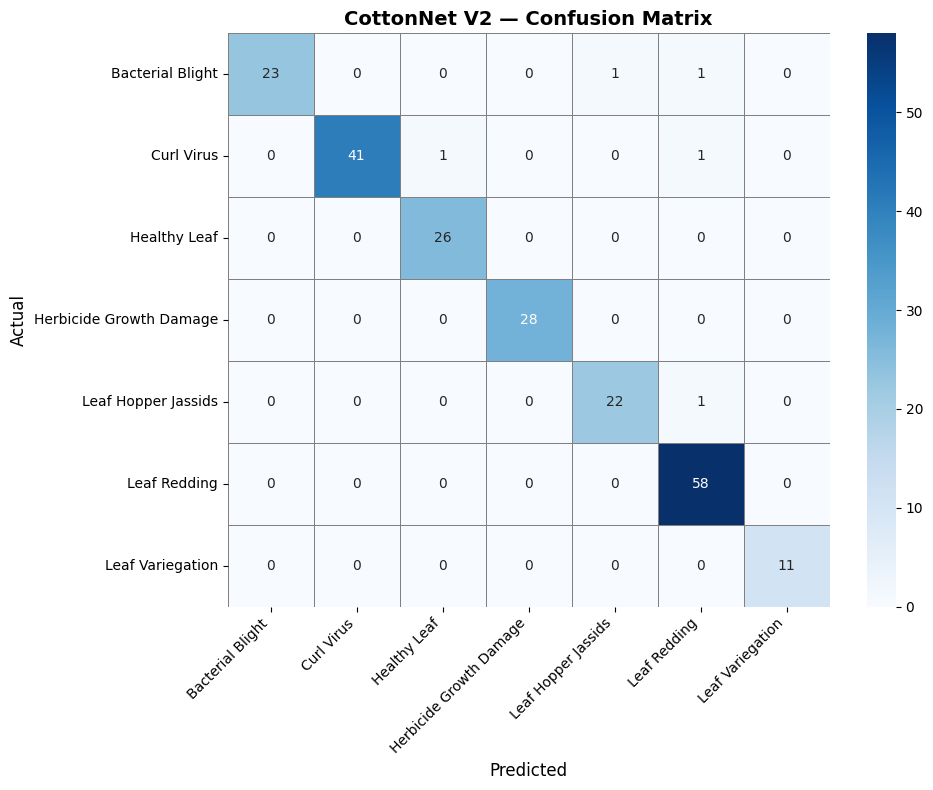

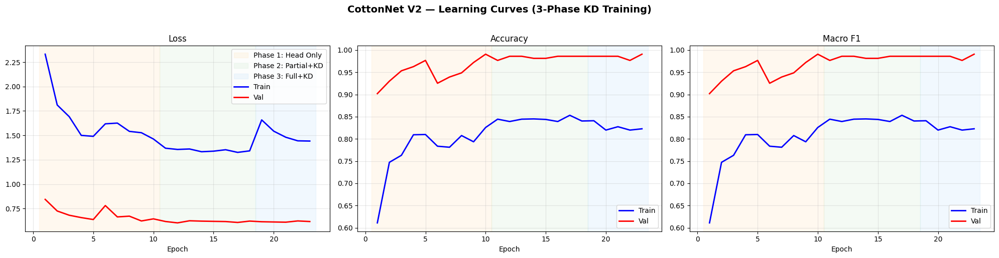

In [27]:
# ============================================================================
# CottonNet V2 — TEST SET EVALUATION
# ============================================================================

class_names = list(classes.keys())

# Load best V2 checkpoint
v2_model = CottonNet(num_classes=len(classes)).to(device)
v2_ckpt = f"{RESEARCH_DIR}/models/cottonnet_v2_best_model.pth"
v2_model.load_state_dict(torch.load(v2_ckpt, map_location=device))
v2_model.eval()

# Full test evaluation
v2_all_preds, v2_all_labels, v2_all_probs = [], [], []
v2_inf_times = []

with torch.no_grad():
    for images, labels in tqdm(v2_test_dl, desc='CottonNet V2 Test'):
        images = images.to(device)
        t0 = time.time()
        outputs = v2_model(images)
        torch.cuda.synchronize() if torch.cuda.is_available() else None
        v2_inf_times.append(time.time() - t0)
        probs = F.softmax(outputs, dim=1)
        v2_all_preds.extend(outputs.argmax(1).cpu().numpy())
        v2_all_labels.extend(labels.numpy())
        v2_all_probs.append(probs.cpu().numpy())

v2_all_preds = np.array(v2_all_preds)
v2_all_labels = np.array(v2_all_labels)
v2_all_probs = np.concatenate(v2_all_probs, axis=0)

v2_acc = (v2_all_preds == v2_all_labels).mean()
v2_top3 = np.argsort(v2_all_probs, axis=1)[:, -3:]
v2_top3_acc = sum(1 for i in range(len(v2_all_labels)) if v2_all_labels[i] in v2_top3[i]) / len(v2_all_labels)
v2_report = classification_report(v2_all_labels, v2_all_preds, target_names=class_names, output_dict=True, zero_division=0)
v2_report_str = classification_report(v2_all_labels, v2_all_preds, target_names=class_names, zero_division=0)

v2_results = {
    'model_name': 'CottonNet V2',
    'accuracy': v2_acc,
    'precision_macro': v2_report['macro avg']['precision'],
    'recall_macro': v2_report['macro avg']['recall'],
    'f1_macro': v2_report['macro avg']['f1-score'],
    'f1_weighted': v2_report['weighted avg']['f1-score'],
    'top3_accuracy': v2_top3_acc,
    'total_params': v2_total_p,
    'trainable_params': v2_train_p,
    'avg_inference_ms': np.mean(v2_inf_times) * 1000,
    'training_time_min': v2_training_time / 60,
    'best_epoch': v2_kd_trainer.best_val_f1,
    'epochs_trained': len(v2_kd_trainer.tr_losses),
    'all_preds': v2_all_preds,
    'all_labels': v2_all_labels,
    'report': v2_report,
    'report_str': v2_report_str,
    'tr_losses': v2_kd_trainer.tr_losses,
    'val_losses': v2_kd_trainer.val_losses,
    'tr_accs': v2_kd_trainer.tr_accs,
    'val_accs': v2_kd_trainer.val_accs,
    'tr_f1s': v2_kd_trainer.tr_f1s,
    'val_f1s': v2_kd_trainer.val_f1s,
}

print(f"\n{'='*60}")
print(f"  CottonNet V2 — Test Set Results")
print(f"{'='*60}")
print(f"  Accuracy:      {v2_acc:.4f}")
print(f"  Precision:     {v2_results['precision_macro']:.4f}")
print(f"  Recall:        {v2_results['recall_macro']:.4f}")
print(f"  Macro F1:      {v2_results['f1_macro']:.4f}")
print(f"  Weighted F1:   {v2_results['f1_weighted']:.4f}")
print(f"  Top-3 Acc:     {v2_top3_acc:.4f}")
print(f"  Params:        {v2_total_p/1e6:.2f}M")
print(f"  Inference:     {v2_results['avg_inference_ms']:.2f} ms/image")
print(f"\n{v2_report_str}")

# Confusion matrix
plot_confusion_matrix(v2_all_labels, v2_all_preds, class_names, 'CottonNet V2', f"{RESEARCH_DIR}/figures")

# Learning curves (V2 uses KD trainer, plot its phase-aware history)
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
fig.suptitle('CottonNet V2 — Learning Curves (3-Phase KD Training)', fontsize=14, fontweight='bold', y=1.02)
epochs_range = range(1, len(v2_kd_trainer.tr_losses) + 1)

# Mark phase boundaries
phase_colors_bg = ['#FFE0B2', '#C8E6C9', '#BBDEFB']
phase_labels = ['Phase 1: Head Only', 'Phase 2: Partial+KD', 'Phase 3: Full+KD']
boundaries = v2_kd_trainer.phase_boundaries + [len(v2_kd_trainer.tr_losses)]

for ax_idx, (data_tr, data_val, title) in enumerate([
    (v2_kd_trainer.tr_losses, v2_kd_trainer.val_losses, 'Loss'),
    (v2_kd_trainer.tr_accs, v2_kd_trainer.val_accs, 'Accuracy'),
    (v2_kd_trainer.tr_f1s, v2_kd_trainer.val_f1s, 'Macro F1'),
]):
    ax = axes[ax_idx]
    # Shade phases
    for p_idx in range(len(boundaries) - 1):
        ax.axvspan(boundaries[p_idx] + 0.5, boundaries[p_idx + 1] + 0.5,
                   alpha=0.2, color=phase_colors_bg[min(p_idx, 2)],
                   label=phase_labels[min(p_idx, 2)] if ax_idx == 0 else None)
    ax.plot(epochs_range, data_tr, 'b-', label='Train', linewidth=2)
    ax.plot(epochs_range, data_val, 'r-', label='Val', linewidth=2)
    ax.set_title(title); ax.set_xlabel('Epoch'); ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f"{RESEARCH_DIR}/figures/cottonnet_v2_learning_curves.png", dpi=150, bbox_inches='tight')
plt.show()

del v2_model
torch.cuda.empty_cache() if torch.cuda.is_available() else None

<div style='background-color: #0d1117; border: 3px solid #3fb950; border-radius: 12px; padding: 15px; text-align: center;'>
    <font size='+2' color='#3fb950'><b>🌿 17. Swin Transformer Tiny (Swin-T) 🌿</b></font><br>
    <font size='+1' color='#8b949e'><b>Hierarchical ViT with Shifted Windows · ImageNet-1K Pretrained</b></font>
</div>

**Architecture**: Swin-T uses shifted-window multi-head self-attention for efficient hierarchical feature extraction. Pretrained on ImageNet-1K, fine-tuned for 7 cotton leaf disease classes.

| Property | Value |
|:---|:---|
| Window Size | 7×7 |
| Embed Dim | 96 |
| Depths | [2, 2, 6, 2] |
| Heads | [3, 6, 12, 24] |

Creating Swin-T model...


model.safetensors:   0%|          | 0.00/114M [00:00<?, ?B/s]

[Swin-T] Total params: 27.52M | Trainable: 27.52M

  Training: Swin-T for 25 epochs


  Epoch   1/25 | Train Loss: 1.2532 Acc: 0.6226 F1: 0.5816 | Val Loss: 0.7711 Acc: 0.8832 F1: 0.8760 | LR: 1.99e-05 | ★ BEST


  Epoch   2/25 | Train Loss: 0.7921 Acc: 0.8631 F1: 0.8556 | Val Loss: 0.6611 Acc: 0.9252 F1: 0.9302 | LR: 1.97e-05 | ★ BEST


  Epoch   3/25 | Train Loss: 0.7092 Acc: 0.8929 F1: 0.8889 | Val Loss: 0.6043 Acc: 0.9486 F1: 0.9519 | LR: 1.93e-05 | ★ BEST


... (8 outputs left out)

  Epoch  12/25 | Train Loss: 0.5520 Acc: 0.9573 F1: 0.9565 | Val Loss: 0.5311 Acc: 0.9673 F1: 0.9675 | LR: 1.11e-05 | 


  Epoch  13/25 | Train Loss: 0.5359 Acc: 0.9666 F1: 0.9661 | Val Loss: 0.5134 Acc: 0.9626 F1: 0.9632 | LR: 9.90e-06 | 


  Epoch  14/25 | Train Loss: 0.5322 Acc: 0.9696 F1: 0.9671 | Val Loss: 0.4910 Acc: 0.9860 F1: 0.9857 | LR: 8.72e-06 | 
  Early stopping at epoch 14 (no improvement for 5 epochs)

  Swin-T training complete in 5.7 min
  Best Val F1: 0.9858 at epoch 9



  Swin-T — Test Set Results
  Accuracy:      0.9766
  Precision:     0.9830
  Recall:        0.9738
  Macro F1:      0.9782
  Weighted F1:   0.9766
  Top-3 Acc:     1.0000
  Params:        27.52M
  Inference:     15.20 ms/image

                         precision    recall  f1-score   support

       Bacterial Blight       1.00      0.96      0.98        25
             Curl Virus       0.95      0.98      0.97        43
           Healthy Leaf       0.96      0.92      0.94        26
Herbicide Growth Damage       1.00      1.00      1.00        28
    Leaf Hopper Jassids       1.00      0.96      0.98        23
           Leaf Redding       0.97      1.00      0.98        58
       Leaf Variegation       1.00      1.00      1.00        11

               accuracy                           0.98       214
              macro avg       0.98      0.97      0.98       214
           weighted avg       0.98      0.98      0.98       214



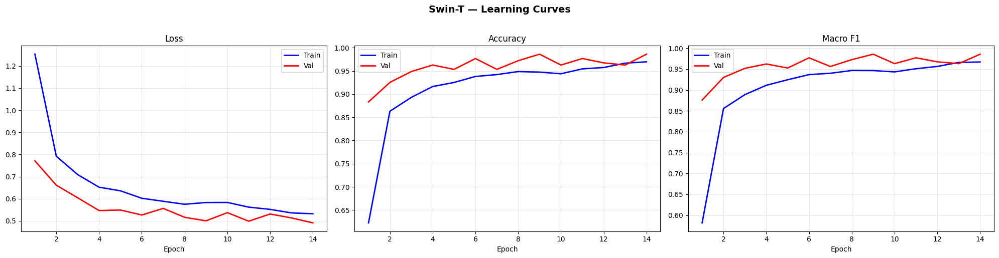

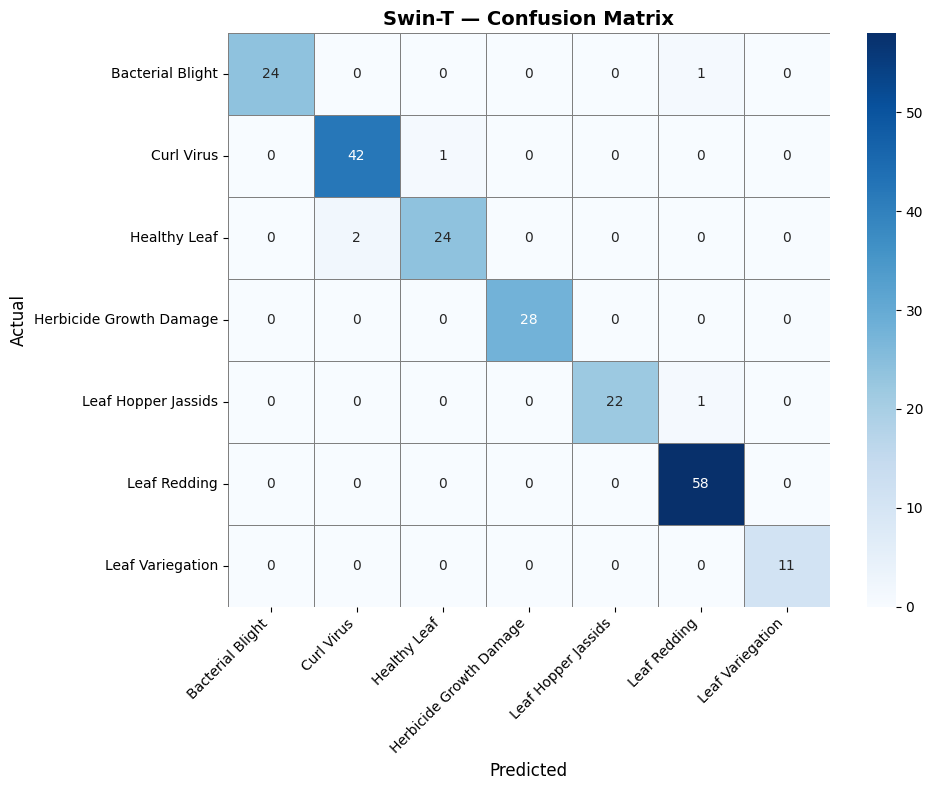

In [28]:
# ============================================================================
# SWIN TRANSFORMER TINY — PRETRAINED, FINE-TUNED
# ============================================================================

print("Creating Swin-T model...")
swin_model = timm.create_model('swin_tiny_patch4_window7_224', pretrained=True, num_classes=len(classes))

swin_trainer = ExtendedTrainer(
    model=swin_model,
    model_name='Swin-T',
    train_dl=v2_train_dl,
    val_dl=v2_val_dl,
    num_classes=len(classes),
    device=device,
    save_dir=f"{RESEARCH_DIR}/models",
    lr=2e-5,
    epochs=25,
    patience=5,
    label_smoothing=0.1,
    weight_decay=0.05
)

swin_trainer.train()

# Evaluate on test set
swin_results = swin_trainer.evaluate_test(v2_test_dl, class_names)

# Learning curves
plot_learning_curves(swin_trainer, f"{RESEARCH_DIR}/figures")

# Confusion matrix
plot_confusion_matrix(swin_results['all_labels'], swin_results['all_preds'],
                      class_names, 'Swin-T', f"{RESEARCH_DIR}/figures")

# Cleanup
del swin_model
torch.cuda.empty_cache() if torch.cuda.is_available() else None

<div style='background-color: #0d1117; border: 3px solid #a371f7; border-radius: 12px; padding: 15px; text-align: center;'>
    <font size='+2' color='#a371f7'><b>🔮 18. ViT-Base/16 (Vision Transformer) 🔮</b></font><br>
    <font size='+1' color='#8b949e'><b>Standard ViT with 16×16 Patches · ImageNet-21K Pretrained</b></font>
</div>

**Architecture**: ViT-B/16 splits the image into 16×16 patches, linearly embeds them, and processes them through 12 transformer encoder layers. Pretrained on ImageNet-21K, fine-tuned for 7 classes.

| Property | Value |
|:---|:---|
| Patch Size | 16×16 |
| Hidden Dim | 768 |
| Layers | 12 |
| Heads | 12 |
| Parameters | ~86M |

Creating ViT-B/16 model...


model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

[ViT-B/16] Total params: 85.80M | Trainable: 85.80M

  Training: ViT-B/16 for 20 epochs


  Epoch   1/20 | Train Loss: 1.0700 Acc: 0.7250 F1: 0.7092 | Val Loss: 0.6274 Acc: 0.9579 F1: 0.9546 | LR: 9.94e-06 | ★ BEST


  Epoch   2/20 | Train Loss: 0.6809 Acc: 0.9146 F1: 0.9082 | Val Loss: 0.5748 Acc: 0.9533 F1: 0.9504 | LR: 9.78e-06 | 


  Epoch   3/20 | Train Loss: 0.6102 Acc: 0.9397 F1: 0.9374 | Val Loss: 0.5478 Acc: 0.9626 F1: 0.9602 | LR: 9.51e-06 | ★ BEST


... (6 outputs left out)

  Epoch  10/20 | Train Loss: 0.5004 Acc: 0.9772 F1: 0.9759 | Val Loss: 0.4965 Acc: 0.9860 F1: 0.9870 | LR: 5.50e-06 | 


  Epoch  11/20 | Train Loss: 0.4925 Acc: 0.9830 F1: 0.9813 | Val Loss: 0.4621 Acc: 0.9953 F1: 0.9958 | LR: 4.80e-06 | 


  Epoch  12/20 | Train Loss: 0.4927 Acc: 0.9807 F1: 0.9800 | Val Loss: 0.4635 Acc: 0.9953 F1: 0.9956 | LR: 4.11e-06 | 
  Early stopping at epoch 12 (no improvement for 5 epochs)

  ViT-B/16 training complete in 12.9 min
  Best Val F1: 0.9958 at epoch 7



  ViT-B/16 — Test Set Results
  Accuracy:      0.9813
  Precision:     0.9837
  Recall:        0.9823
  Macro F1:      0.9828
  Weighted F1:   0.9813
  Top-3 Acc:     1.0000
  Params:        85.80M
  Inference:     13.94 ms/image

                         precision    recall  f1-score   support

       Bacterial Blight       1.00      0.96      0.98        25
             Curl Virus       1.00      0.98      0.99        43
           Healthy Leaf       0.96      1.00      0.98        26
Herbicide Growth Damage       1.00      1.00      1.00        28
    Leaf Hopper Jassids       0.96      0.96      0.96        23
           Leaf Redding       0.97      0.98      0.97        58
       Leaf Variegation       1.00      1.00      1.00        11

               accuracy                           0.98       214
              macro avg       0.98      0.98      0.98       214
           weighted avg       0.98      0.98      0.98       214



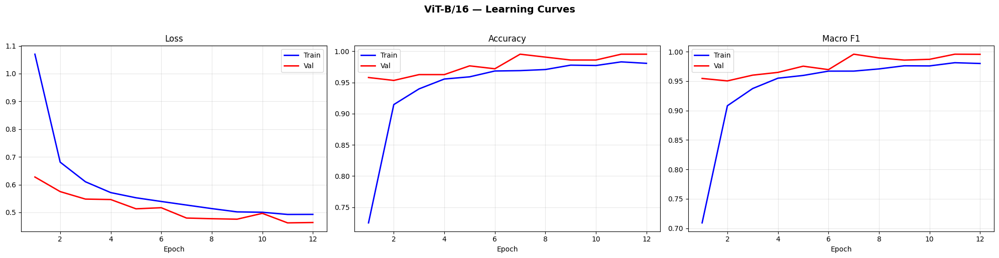

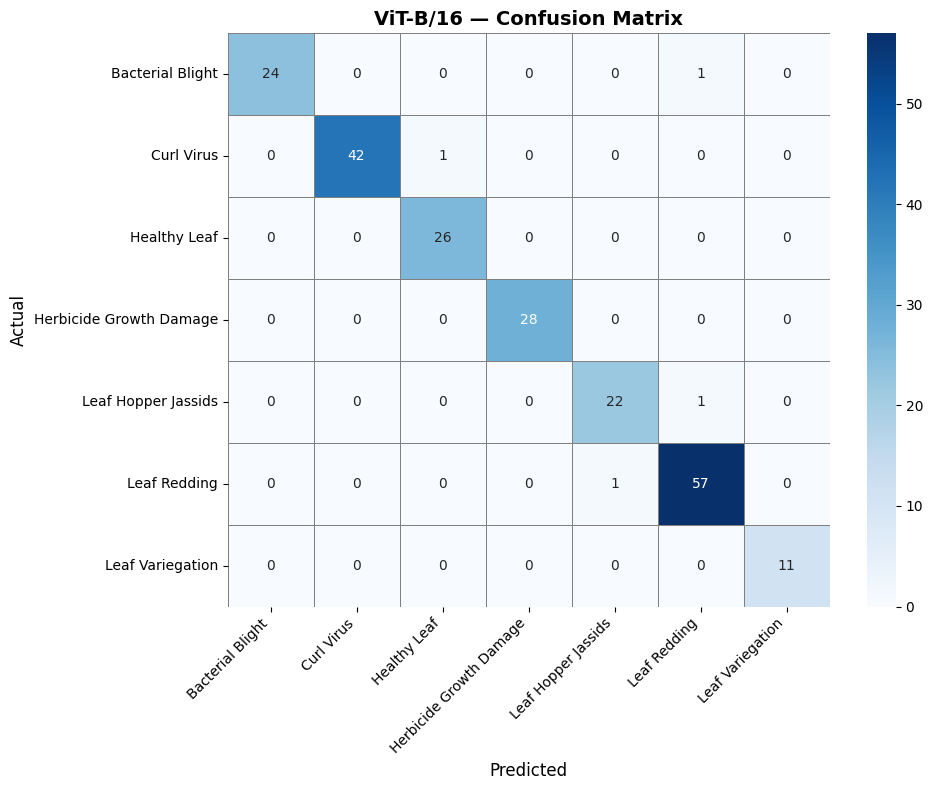

In [29]:
# ============================================================================
# ViT-Base/16 — PRETRAINED, FINE-TUNED
# ============================================================================

print("Creating ViT-B/16 model...")
vit_model = timm.create_model('vit_base_patch16_224', pretrained=True, num_classes=len(classes))

vit_trainer = ExtendedTrainer(
    model=vit_model,
    model_name='ViT-B/16',
    train_dl=v2_train_dl,
    val_dl=v2_val_dl,
    num_classes=len(classes),
    device=device,
    save_dir=f"{RESEARCH_DIR}/models",
    lr=1e-5,
    epochs=20,
    patience=5,
    label_smoothing=0.1,
    weight_decay=0.05
)

vit_trainer.train()

# Evaluate on test set
vit_results = vit_trainer.evaluate_test(v2_test_dl, class_names)

# Learning curves
plot_learning_curves(vit_trainer, f"{RESEARCH_DIR}/figures")

# Confusion matrix
plot_confusion_matrix(vit_results['all_labels'], vit_results['all_preds'],
                      class_names, 'ViT-B/16', f"{RESEARCH_DIR}/figures")

# Cleanup
del vit_model
torch.cuda.empty_cache() if torch.cuda.is_available() else None

<div style='background-color: #0d1117; border: 3px solid #f0883e; border-radius: 12px; padding: 15px; text-align: center;'>
    <font size='+2' color='#f0883e'><b>⚡ 19. YOLO26s Classification (Ultralytics) ⚡</b></font><br>
    <font size='+1' color='#8b949e'><b>YOLO26s-cls · Pretrained · Fine-tuned for 7 Classes</b></font>
</div>

**Architecture**: YOLO26s classification variant from Ultralytics. Lightweight and fast, designed for real-time classification tasks. Pretrained backbone fine-tuned for cotton leaf disease classification.

YOLO uses its own training pipeline via the Ultralytics API, so we prepare a folder-structured dataset and use `model.train()`.

In [30]:
# ============================================================================
# YOLO26s CLASSIFICATION — DATASET PREPARATION
# ============================================================================
# YOLO classification expects folder structure: dataset/train/class_name/images

import shutil
from ultralytics import YOLO

YOLO_DATA_DIR = f"{RESEARCH_DIR}/yolo_cls_dataset"

def prepare_yolo_cls_dataset(im_paths, im_lbls, class_names_dict, split_name, base_dir):
    """Create folder-structured dataset for YOLO classification."""
    split_dir = os.path.join(base_dir, split_name)
    class_name_list = list(class_names_dict.keys())

    for cls_name in class_name_list:
        os.makedirs(os.path.join(split_dir, cls_name), exist_ok=True)

    for path, label in zip(im_paths, im_lbls):
        cls_name = class_name_list[label]
        dst = os.path.join(split_dir, cls_name, os.path.basename(path))
        if not os.path.exists(dst):
            shutil.copy2(path, dst)

    print(f"  {split_name}: {len(im_paths)} images -> {split_dir}")


print("Preparing YOLO classification dataset...")
prepare_yolo_cls_dataset(train_paths, train_labels, classes, 'train', YOLO_DATA_DIR)
prepare_yolo_cls_dataset(val_dl.dataset.im_paths, val_dl.dataset.im_lbls, classes, 'val', YOLO_DATA_DIR)
prepare_yolo_cls_dataset(ts_dl.dataset.im_paths, ts_dl.dataset.im_lbls, classes, 'test', YOLO_DATA_DIR)
print("YOLO dataset prepared.")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Preparing YOLO classification dataset...
  train: 1709 images -> /kaggle/working/CottonCare_Research/yolo_cls_dataset/train
  val: 214 images -> /kaggle/working/CottonCare_Research/yolo_cls_dataset/val
  test: 214 images -> /kaggle/working/CottonCare_Research/yolo_cls_dataset/test
YOLO dataset prepared.


In [31]:
# ============================================================================
# YOLO26s CLASSIFICATION — TRAINING
# ============================================================================

yolo_model = YOLO('yolo26s-cls.pt')  # Pretrained YOLO26s classifier

yolo_start = time.time()
yolo_results_raw = yolo_model.train(
    data=YOLO_DATA_DIR,
    epochs=30,
    imgsz=224,
    batch=bs,
    patience=5,
    lr0=1e-3,
    lrf=0.01,
    optimizer='AdamW',
    weight_decay=1e-4,
    label_smoothing=0.1,
    project=f"{RESEARCH_DIR}/yolo_runs",
    name='yolo26s_cls',
    exist_ok=True,
    verbose=True,
)
yolo_training_time = time.time() - yolo_start

print(f"\nYOLO26s training complete in {yolo_training_time/60:.1f} minutes")

WARNING ⚠️ 'label_smoothing' is deprecated and will be removed in the future.
Ultralytics 8.4.171 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/CottonCare_Research/yolo_cls_dataset, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s-cls.pt, momen

YOLO class mapping: {0: 'Bacterial Blight', 1: 'Curl Virus', 2: 'Healthy Leaf', 3: 'Herbicide Growth Damage', 4: 'Leaf Hopper Jassids', 5: 'Leaf Redding', 6: 'Leaf Variegation'}
Remapping: {0: 0, 1: 1, 2: 2, 3: 3, 4: 4, 5: 5, 6: 6}


YOLO26s Test: 100%|██████████| 214/214 [00:03<00:00, 65.36it/s]



  YOLO26s-cls — Test Set Results
  Accuracy:      0.9299
  Precision:     0.9497
  Recall:        0.9233
  Macro F1:      0.9341
  Weighted F1:   0.9288
  Top-3 Acc:     0.9953
  Params:        5.45M
  Inference:     15.06 ms/image

                         precision    recall  f1-score   support

       Bacterial Blight       0.96      0.96      0.96        25
             Curl Virus       0.91      0.93      0.92        43
           Healthy Leaf       0.95      0.81      0.88        26
Herbicide Growth Damage       1.00      1.00      1.00        28
    Leaf Hopper Jassids       0.95      0.78      0.86        23
           Leaf Redding       0.88      0.98      0.93        58
       Leaf Variegation       1.00      1.00      1.00        11

               accuracy                           0.93       214
              macro avg       0.95      0.92      0.93       214
           weighted avg       0.93      0.93      0.93       214



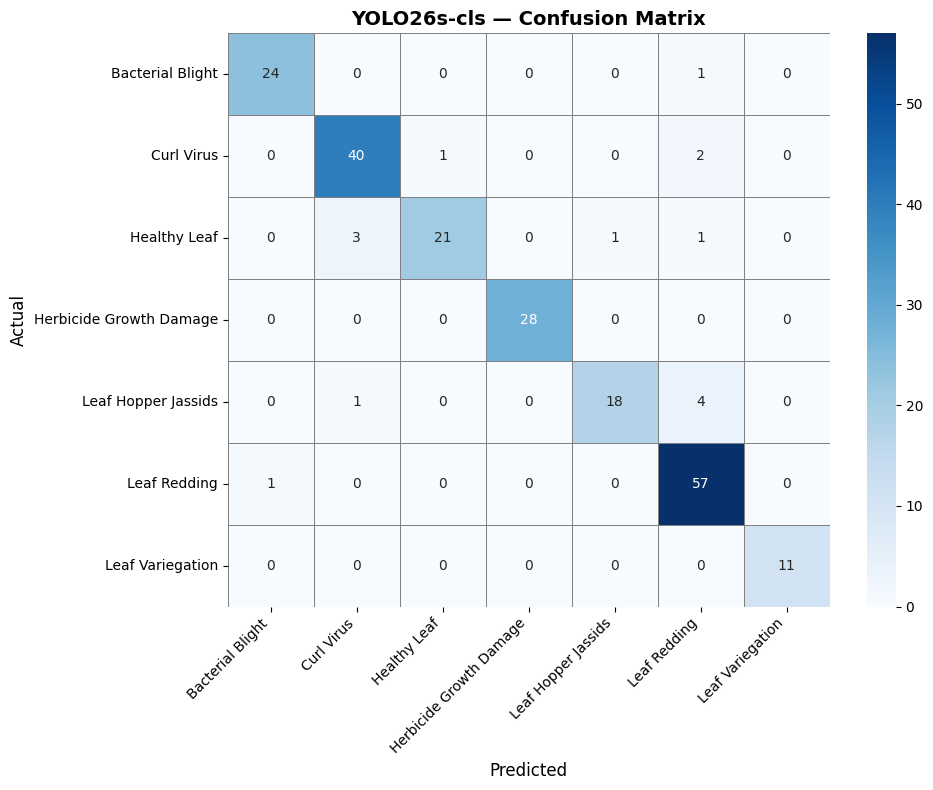

In [32]:
# ============================================================================
# YOLO26s CLASSIFICATION — TEST SET EVALUATION
# ============================================================================

# Load best YOLO model
yolo_best_path = f"{RESEARCH_DIR}/yolo_runs/yolo26s_cls/weights/best.pt"
yolo_eval = YOLO(yolo_best_path)

# Get YOLO's class mapping (may differ from our ordering)
yolo_cls_names = yolo_eval.names  # dict {0: 'class_name', ...}
print(f"YOLO class mapping: {yolo_cls_names}")

# Build a remapping from YOLO's class index to our class index
class_name_list = list(classes.keys())
yolo_to_ours = {}
for yolo_idx, yolo_name in yolo_cls_names.items():
    if yolo_name in classes:
        yolo_to_ours[yolo_idx] = classes[yolo_name]
    else:
        # Fuzzy match by checking if name is substring
        for our_name, our_idx in classes.items():
            if yolo_name.lower().replace('_', ' ') == our_name.lower().replace('_', ' '):
                yolo_to_ours[yolo_idx] = our_idx
                break

print(f"Remapping: {yolo_to_ours}")

# Run prediction on test images
test_paths = ts_dl.dataset.im_paths
test_labels_list = ts_dl.dataset.im_lbls

yolo_preds, yolo_labels, yolo_probs_list = [], [], []
yolo_inf_times = []

for i, path in enumerate(tqdm(test_paths, desc='YOLO26s Test')):
    t0 = time.time()
    result = yolo_eval.predict(path, imgsz=224, verbose=False)[0]
    torch.cuda.synchronize() if torch.cuda.is_available() else None
    yolo_inf_times.append(time.time() - t0)

    probs = result.probs
    yolo_pred_idx = probs.top1

    # Remap to our class ordering
    our_pred = yolo_to_ours.get(yolo_pred_idx, yolo_pred_idx)
    yolo_preds.append(our_pred)
    yolo_labels.append(test_labels_list[i])

    # Remap probability vector
    raw_probs = probs.data.cpu().numpy()
    remapped_probs = np.zeros(len(classes))
    for yolo_i, our_i in yolo_to_ours.items():
        if yolo_i < len(raw_probs):
            remapped_probs[our_i] = raw_probs[yolo_i]
    yolo_probs_list.append(remapped_probs)

yolo_preds = np.array(yolo_preds)
yolo_labels = np.array(yolo_labels)
yolo_probs_arr = np.array(yolo_probs_list)

yolo_acc = (yolo_preds == yolo_labels).mean()
yolo_top3 = np.argsort(yolo_probs_arr, axis=1)[:, -3:]
yolo_top3_acc = sum(1 for i in range(len(yolo_labels)) if yolo_labels[i] in yolo_top3[i]) / len(yolo_labels)
yolo_report = classification_report(yolo_labels, yolo_preds, target_names=class_name_list, output_dict=True, zero_division=0)
yolo_report_str = classification_report(yolo_labels, yolo_preds, target_names=class_name_list, zero_division=0)

yolo_total_params = sum(p.numel() for p in yolo_eval.model.parameters())
yolo_trainable_params = sum(p.numel() for p in yolo_eval.model.parameters() if p.requires_grad)

yolo_results = {
    'model_name': 'YOLO26s-cls',
    'accuracy': yolo_acc,
    'precision_macro': yolo_report['macro avg']['precision'],
    'recall_macro': yolo_report['macro avg']['recall'],
    'f1_macro': yolo_report['macro avg']['f1-score'],
    'f1_weighted': yolo_report['weighted avg']['f1-score'],
    'top3_accuracy': yolo_top3_acc,
    'total_params': yolo_total_params,
    'trainable_params': yolo_trainable_params,
    'avg_inference_ms': np.mean(yolo_inf_times) * 1000,
    'training_time_min': yolo_training_time / 60,
    'all_preds': yolo_preds,
    'all_labels': yolo_labels,
    'report': yolo_report,
    'report_str': yolo_report_str,
}

print(f"\n{'='*60}")
print(f"  YOLO26s-cls — Test Set Results")
print(f"{'='*60}")
print(f"  Accuracy:      {yolo_acc:.4f}")
print(f"  Precision:     {yolo_results['precision_macro']:.4f}")
print(f"  Recall:        {yolo_results['recall_macro']:.4f}")
print(f"  Macro F1:      {yolo_results['f1_macro']:.4f}")
print(f"  Weighted F1:   {yolo_results['f1_weighted']:.4f}")
print(f"  Top-3 Acc:     {yolo_top3_acc:.4f}")
print(f"  Params:        {yolo_total_params/1e6:.2f}M")
print(f"  Inference:     {yolo_results['avg_inference_ms']:.2f} ms/image")
print(f"\n{yolo_report_str}")

# Confusion matrix
plot_confusion_matrix(yolo_labels, yolo_preds, class_name_list, 'YOLO26s-cls', f"{RESEARCH_DIR}/figures")

# Save YOLO best model copy
shutil.copy2(yolo_best_path, f"{RESEARCH_DIR}/models/yolo26s_cls_best_model.pt")

del yolo_eval
torch.cuda.empty_cache() if torch.cuda.is_available() else None

<div style='background-color: #1a1a2e; border: 3px solid #f0883e; border-radius: 12px; padding: 15px; text-align: center;'>
    <font size='+2' color='#f0883e'><b>🏆 20. Grand Model Comparison — All 9 Models 🏆</b></font><br>
    <font size='+1' color='#8b949e'><b>V1 Baselines + CottonNet V1 + CottonNet V2 + Swin-T + ViT-B/16 + YOLO26s</b></font>
</div>

Comprehensive side-by-side comparison of all trained models.

In [33]:
# ============================================================================
# GRAND COMPARISON TABLE — ALL MODELS
# ============================================================================
import pandas as pd

extended_results = {
    'CottonNet V2': v2_results,
    'Swin-T': swin_results,
    'ViT-B/16': vit_results,
    'YOLO26s-cls': yolo_results,
}

# Build comparison DataFrame
rows = []
for name, res in extended_results.items():
    rows.append({
        'Model': name,
        'Accuracy': f"{res['accuracy']*100:.2f}%",
        'Precision': f"{res['precision_macro']*100:.2f}%",
        'Recall': f"{res['recall_macro']*100:.2f}%",
        'Macro F1': f"{res['f1_macro']*100:.2f}%",
        'Weighted F1': f"{res['f1_weighted']*100:.2f}%",
        'Top-3 Acc': f"{res['top3_accuracy']*100:.2f}%",
        'Params (M)': f"{res['total_params']/1e6:.2f}",
        'Inference (ms)': f"{res['avg_inference_ms']:.2f}",
        'Train Time (min)': f"{res['training_time_min']:.1f}",
    })

df = pd.DataFrame(rows)
print("\n" + "="*130)
print(f"{'EXTENDED MODEL COMPARISON — TEST SET RESULTS':^130}")
print("="*130)
print(df.to_string(index=False))
print("="*130)

# Save to CSV
df.to_csv(f"{RESEARCH_DIR}/results/extended_model_comparison.csv", index=False)
print(f"\nSaved to {RESEARCH_DIR}/results/extended_model_comparison.csv")


                                           EXTENDED MODEL COMPARISON — TEST SET RESULTS                                           
       Model Accuracy Precision Recall Macro F1 Weighted F1 Top-3 Acc Params (M) Inference (ms) Train Time (min)
CottonNet V2   97.66%    98.15% 97.57%   97.81%      97.66%   100.00%       4.87          10.96              5.0
      Swin-T   97.66%    98.30% 97.38%   97.82%      97.66%   100.00%      27.52          15.20              5.7
    ViT-B/16   98.13%    98.37% 98.23%   98.28%      98.13%   100.00%      85.80          13.94             12.9
 YOLO26s-cls   92.99%    94.97% 92.33%   93.41%      92.88%    99.53%       5.45          15.06              3.2

Saved to /kaggle/working/CottonCare_Research/results/extended_model_comparison.csv


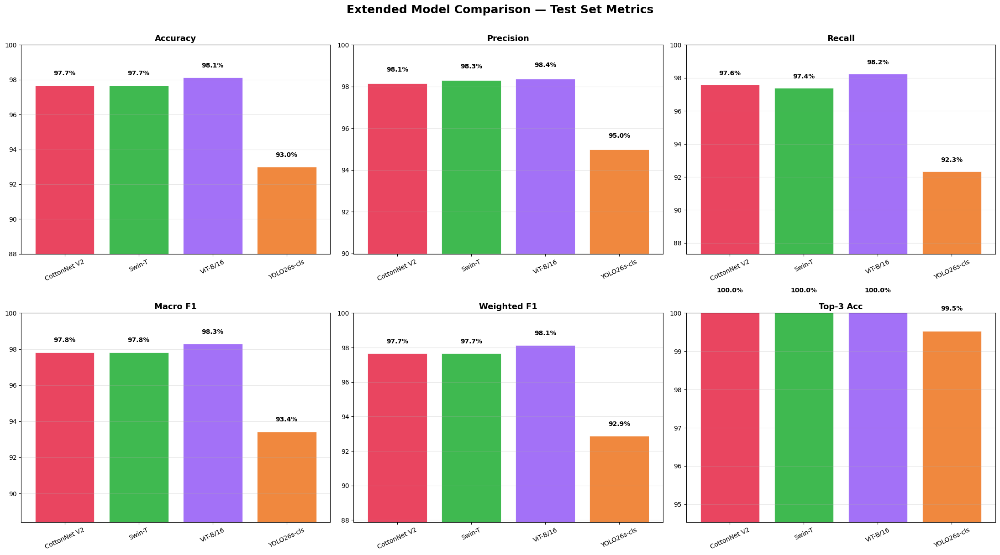

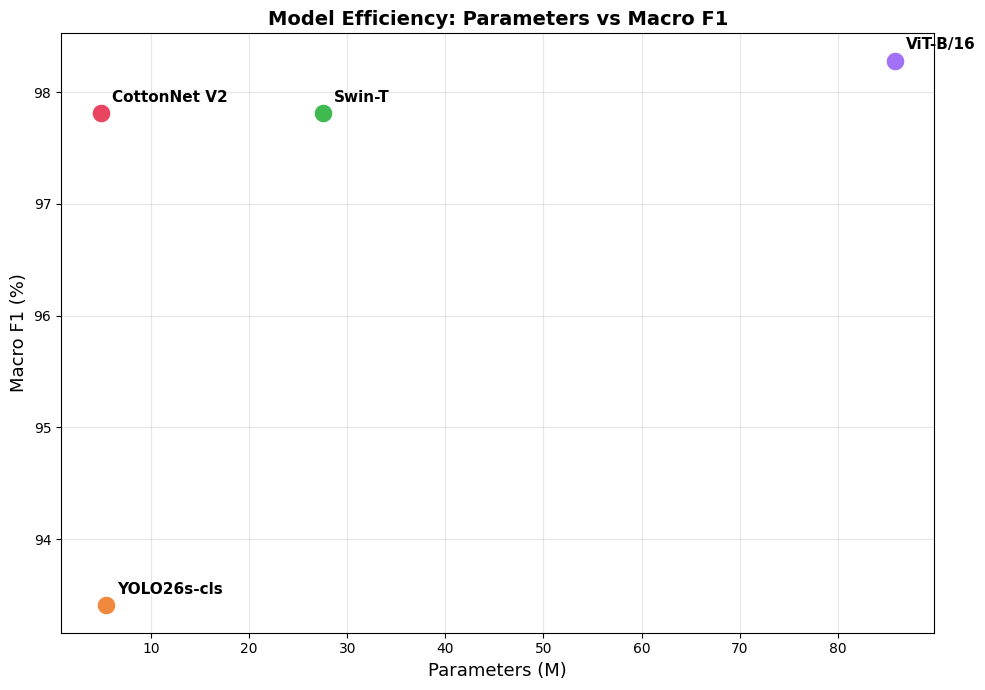

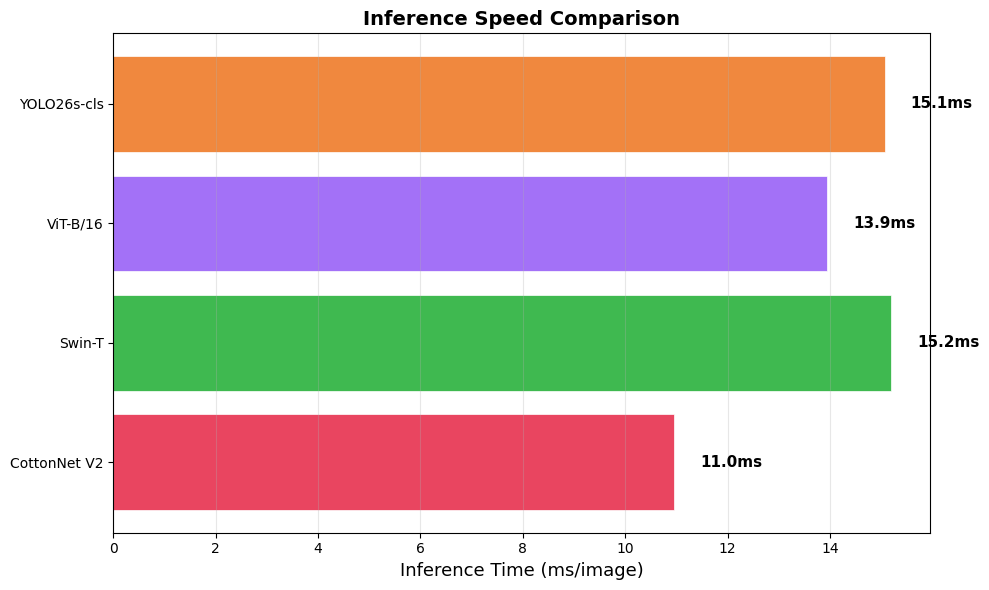

In [34]:
# ============================================================================
# GRAND COMPARISON — BAR CHARTS
# ============================================================================

EXTENDED_COLORS = {
    'CottonNet V2': '#e94560',
    'Swin-T': '#3fb950',
    'ViT-B/16': '#a371f7',
    'YOLO26s-cls': '#f0883e',
}

metrics_to_plot = ['accuracy', 'precision_macro', 'recall_macro', 'f1_macro', 'f1_weighted', 'top3_accuracy']
metric_labels = ['Accuracy', 'Precision', 'Recall', 'Macro F1', 'Weighted F1', 'Top-3 Acc']

fig, axes = plt.subplots(2, 3, figsize=(22, 12))
fig.suptitle('Extended Model Comparison — Test Set Metrics', fontsize=18, fontweight='bold', y=1.01)

for idx, (metric, label) in enumerate(zip(metrics_to_plot, metric_labels)):
    ax = axes[idx // 3, idx % 3]
    model_names = list(extended_results.keys())
    values = [extended_results[m][metric] * 100 for m in model_names]
    colors = [EXTENDED_COLORS[m] for m in model_names]

    bars = ax.bar(model_names, values, color=colors, edgecolor='white', linewidth=0.5)
    ax.set_title(label, fontsize=13, fontweight='bold')
    ax.set_ylim(max(0, min(values) - 5), 100)
    ax.grid(axis='y', alpha=0.3)

    for bar, val in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                f'{val:.1f}%', ha='center', va='bottom', fontsize=10, fontweight='bold')

    ax.tick_params(axis='x', rotation=25)

plt.tight_layout()
plt.savefig(f"{RESEARCH_DIR}/figures/extended_comparison_bars.png", dpi=150, bbox_inches='tight')
plt.show()

# --- Params vs F1 scatter ---
fig, ax = plt.subplots(figsize=(10, 7))
for name, res in extended_results.items():
    ax.scatter(res['total_params']/1e6, res['f1_macro']*100,
               s=200, c=EXTENDED_COLORS[name], edgecolors='white', linewidth=1.5, zorder=5)
    ax.annotate(name, (res['total_params']/1e6, res['f1_macro']*100),
                xytext=(8, 8), textcoords='offset points', fontsize=11, fontweight='bold')

ax.set_xlabel('Parameters (M)', fontsize=13)
ax.set_ylabel('Macro F1 (%)', fontsize=13)
ax.set_title('Model Efficiency: Parameters vs Macro F1', fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f"{RESEARCH_DIR}/figures/params_vs_f1.png", dpi=150, bbox_inches='tight')
plt.show()

# --- Inference time comparison ---
fig, ax = plt.subplots(figsize=(10, 6))
model_names = list(extended_results.keys())
inf_times = [extended_results[m]['avg_inference_ms'] for m in model_names]
colors = [EXTENDED_COLORS[m] for m in model_names]

bars = ax.barh(model_names, inf_times, color=colors, edgecolor='white', linewidth=0.5)
ax.set_xlabel('Inference Time (ms/image)', fontsize=13)
ax.set_title('Inference Speed Comparison', fontsize=14, fontweight='bold')
ax.grid(axis='x', alpha=0.3)

for bar, val in zip(bars, inf_times):
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
            f'{val:.1f}ms', ha='left', va='center', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig(f"{RESEARCH_DIR}/figures/inference_time_comparison.png", dpi=150, bbox_inches='tight')
plt.show()

<div style='background-color: #e8f5e9; border: 3px solid #43a047; border-radius: 10px; padding: 8px; text-align: center;'>
    <font size='+2' color='#43a047'><b>💾 21. Save All Results & Models 💾</b></font>
</div>

In [35]:
# ============================================================================
# SAVE ALL RESULTS TO JSON
# ============================================================================

def make_serializable(res):
    """Convert numpy arrays to lists for JSON serialization."""
    out = {}
    for k, v in res.items():
        if isinstance(v, np.ndarray):
            out[k] = v.tolist()
        elif isinstance(v, (np.float32, np.float64)):
            out[k] = float(v)
        elif isinstance(v, (np.int32, np.int64)):
            out[k] = int(v)
        elif isinstance(v, dict):
            out[k] = make_serializable(v)
        else:
            out[k] = v
    return out

# Save extended results
save_results = {}
for name, res in extended_results.items():
    save_results[name] = make_serializable(res)

with open(f"{RESEARCH_DIR}/results/extended_results.json", 'w') as f:
    json.dump(save_results, f, indent=2, default=str)

# Save per-model classification reports
for name, res in extended_results.items():
    safe_name = name.lower().replace(' ', '_').replace('-', '_').replace('/', '_')
    with open(f"{RESEARCH_DIR}/results/{safe_name}_classification_report.txt", 'w') as f:
        f.write(f"{name} — Classification Report\n")
        f.write("=" * 60 + "\n")
        f.write(res['report_str'])

print(f"\nAll results saved to {RESEARCH_DIR}/results/")
print(f"All models saved to {RESEARCH_DIR}/models/")
print(f"All figures saved to {RESEARCH_DIR}/figures/")

# List saved artifacts
print("\n" + "="*60)
print("  SAVED ARTIFACTS")
print("="*60)
for dirpath, dirnames, filenames in os.walk(RESEARCH_DIR):
    for f in sorted(filenames):
        fpath = os.path.join(dirpath, f)
        size_mb = os.path.getsize(fpath) / (1024*1024)
        rel_path = os.path.relpath(fpath, RESEARCH_DIR)
        print(f"  {rel_path:60s} {size_mb:8.2f} MB")


All results saved to /kaggle/working/CottonCare_Research/results/
All models saved to /kaggle/working/CottonCare_Research/models/
All figures saved to /kaggle/working/CottonCare_Research/figures/

  SAVED ARTIFACTS
  figures/cottonnet_v2_confusion_matrix.png                        0.10 MB
  figures/cottonnet_v2_learning_curves.png                         0.14 MB
  figures/extended_comparison_bars.png                             0.17 MB
  figures/inference_time_comparison.png                            0.04 MB
  figures/params_vs_f1.png                                         0.05 MB
  figures/swin_t_confusion_matrix.png                              0.10 MB
  figures/swin_t_learning_curves.png                               0.11 MB
  figures/v2_augmentation_samples.png                             11.57 MB
  figures/vit_b_16_confusion_matrix.png                            0.10 MB
  figures/vit_b_16_learning_curves.png                             0.10 MB
  figures/yolo26s_cls_confusion_ma

<div style='background-color: #1a1a2e; border: 3px solid #16c79a; border-radius: 12px; padding: 15px; text-align: center;'>
    <font size='+2' color='#16c79a'><b>✅ Extended Research Summary ✅</b></font>
</div>

### Part II — Extended Benchmark Results

| Model | Architecture | Training Strategy | Augmentation | Key Contribution |
|:---|:---|:---|:---:|:---|
| CottonNet V1 | CottonNet (EfficientNet-B0 + SE + Dual Pooling) | 3-Phase KD from DenseNet121 | V1 (flip, rotation, ColorJitter, blur) | Original baseline |
| CottonNet V2 | CottonNet (EfficientNet-B0 + SE + Dual Pooling) | 3-Phase KD from DenseNet121 | V2 (realistic field: brightness, contrast, gamma, shadow, noise, JPEG, blur) | Ablation: augmentation impact (same arch + same KD) |
| Swin-T | Swin Transformer Tiny | Standard fine-tune (AdamW + Cosine) | V2 | Hierarchical ViT baseline |
| ViT-B/16 | Vision Transformer Base | Standard fine-tune (AdamW + Cosine) | V2 | Standard ViT baseline |
| YOLO26s-cls | YOLO26s Classification | Ultralytics pipeline | YOLO built-in | Real-time classification baseline |

### Key Comparisons Enabled:
1. **CottonNet V1 vs V2**: Isolates the impact of augmentation strategy (same architecture, same KD, same split)
2. **CNN vs Transformer**: CottonNet/YOLO vs Swin-T/ViT-B/16
3. **Efficiency vs Accuracy**: Parameter count and inference time tradeoffs
4. **Generalization**: Train→test gap across all architectures

### Output Structure:
```
/kaggle/working/CottonCare_Research/
├── models/          # All trained model checkpoints
├── results/         # CSV, JSON, classification reports
├── figures/         # Confusion matrices, learning curves, comparison charts
└── yolo_runs/       # YOLO training artifacts
```

<div style='background-color: #1a1a2e; border: 3px solid #16c79a; border-radius: 12px; padding: 15px; text-align: center;'>
    <font size="+2" color="#16c79a"><b>✅ Project Summary & Next Steps ✅</b></font>
</div>

### What we accomplished:
1. **Benchmarked 4 standard architectures** (ResNet50, EfficientNet-B0, MobileNetV3-Large, DenseNet121)
2. **Identified overfitting** in EfficientNet-B0 (Val F1=97.66% but Test F1=91.59%)
3. **Built CottonNet** — a custom lightweight model with:
   - Modified EfficientNet-B0 backbone with frozen early layers
   - SE channel attention for disease region focus
   - Dual pooling (Avg + Max) for robust feature capture
   - Knowledge distillation from DenseNet121
   - Field-resilient augmentations

### Next steps for the research paper:
- Export CottonNet to **ONNX / TFLite (INT8)** and measure model size
- Benchmark inference time on an **actual low-end Android phone**
- Test with **out-of-distribution images** (non-cotton, blurry, random objects)
- Build the **Android app** with offline inference
- Write the paper with the comparison tables and graphs from this notebook

<div style='background-color: #0d1117; border: 3px solid #f0883e; border-radius: 12px; padding: 24px; margin-bottom: 20px;'>
    <h1 style='color: #f0883e; text-align: center; margin: 0 0 10px 0; font-size: 26px; font-weight: 700;'>
        PART III: EXTERNAL DATASET EVALUATION & GENERALIZATION BENCHMARK
    </h1>
    <p style='color: #c9d1d9; text-align: center; font-size: 15px; margin: 0 0 15px 0;'>
        Rigorous Out-of-Domain (OOD) Evaluation of 4 Trained Models on Independent External Dataset
    </p>
    <div style='background-color: #161b22; border-radius: 8px; padding: 14px; color: #8b949e; font-size: 13px;'>
        <b style='color: #58a6ff;'>Protocol & Constraints:</b>
        <ul style='margin: 8px 0 0 0; padding-left: 20px;'>
            <li><b>Evaluated Models:</b> CottonNet V2, YOLO26s-cls, Swin-Tiny, ViT-Base/16 (Loaded from <code>/kaggle/working/CottonCare_Research/models/</code>).</li>
            <li><b>Directly Matching Classes (3):</b> <code>Bacterial Blight</code>, <code>Curl Virus</code>, <code>Healthy Leaf</code>.</li>
            <li><b>Excluded Non-Target Class:</b> <code>Fusarium Wilt</code> (not trained in CottonCare, strictly excluded from evaluation).</li>
            <li><b>7-Class Output Evaluation Rule:</b> Models predict across all 7 CottonCare classes. Predictions falling into the other 4 classes are strictly counted as incorrect.</li>
            <li><b>Metrics:</b> Accuracy, Top-3 Accuracy, Macro/Weighted F1, Per-Class Precision/Recall/F1, Latency (Avg, P50, P95), and Generalization Gap.</li>
            <li><b>Zero Data Leakage:</b> No fine-tuning, no threshold tuning, no retraining on external data.</li>
        </ul>
    </div>
</div>


<div style='background-color: #1a1a2e; border: 3px solid #58a6ff; border-radius: 8px; padding: 14px; margin-bottom: 10px;'>
    <h3 style='color: #58a6ff; margin: 0;'>Step 1: Checkpoint Verification & External Dataset Auto-Discovery</h3>
    <p style='color: #c9d1d9; margin: 5px 0 0 0; font-size: 13px;'>Verifies that all 4 trained model checkpoints exist and scans <code>/kaggle/input</code> for matching external classes.</p>
</div>


In [ ]:
# ============================================================================
# STEP 1: VERIFY CHECKPOINTS & AUTO-LOCATE EXTERNAL DATASET
# ============================================================================
import os
import glob
import time
import json
import numpy as np
import pandas as pd
from PIL import Image
import torch
import timm
from torchvision import transforms as T
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support
from ultralytics import YOLO
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Define output directories
EXTERNAL_EVAL_DIR = "/kaggle/working/CottonCare_External_Evaluation"
EXTERNAL_FIGS_DIR = os.path.join(EXTERNAL_EVAL_DIR, "figures")
os.makedirs(EXTERNAL_EVAL_DIR, exist_ok=True)
os.makedirs(EXTERNAL_FIGS_DIR, exist_ok=True)

# 2. Locate Checkpoints
CHECKPOINT_PATHS = {
    'CottonNet V2': f"{RESEARCH_DIR}/models/cottonnet_v2_best_model.pth",
    'Swin-T': f"{RESEARCH_DIR}/models/swin_t_best_model.pth",
    'ViT-B/16': f"{RESEARCH_DIR}/models/vit_b_16_best_model.pth",
    'YOLO26s-cls': f"{RESEARCH_DIR}/models/yolo26s_cls_best_model.pt"
}

# Fallback search for YOLO weights if primary path doesn't exist
if not os.path.exists(CHECKPOINT_PATHS['YOLO26s-cls']):
    fallback_yolo = f"{RESEARCH_DIR}/yolo_runs/yolo26s_cls/weights/best.pt"
    if os.path.exists(fallback_yolo):
        CHECKPOINT_PATHS['YOLO26s-cls'] = fallback_yolo

print("="*70)
print("  CHECKPOINT VERIFICATION")
print("="*70)
all_checkpoints_ok = True
for model_name, path in CHECKPOINT_PATHS.items():
    exists = os.path.exists(path)
    size_mb = os.path.getsize(path) / (1024*1024) if exists else 0
    status = f"OK ({size_mb:.2f} MB)" if exists else "MISSING!"
    print(f"  [{'x' if exists else ' '}] {model_name:<16}: {status} -> {path}")
    if not exists:
        all_checkpoints_ok = False

if not all_checkpoints_ok:
    print("\n  WARNING: Some checkpoints are missing. Please verify Part II training completed.")
else:
    print("\n  All 4 model checkpoints verified successfully.")

# 3. Auto-Locate External Dataset
print("\n" + "="*70)
print("  EXTERNAL DATASET AUTO-DISCOVERY")
print("="*70)

# Supported class mapping to internal 7-class taxonomy
CLASS_MAP_EXTERNAL = {
    'bacterial_blight': 'Bacterial Blight',
    'bacterial blight': 'Bacterial Blight',
    'curl_virus': 'Curl Virus',
    'curl virus': 'Curl Virus',
    'cotton_leaf_curl_virus': 'Curl Virus',
    'healthy': 'Healthy Leaf',
    'healthy_leaf': 'Healthy Leaf',
    'healthy leaf': 'Healthy Leaf'
}

# Excluded classes explicitly ignored from evaluation
EXCLUDED_CLASSES = ['fusarium_wilt', 'fusarium wilt', 'fusarium']

valid_exts = ('.png', '.jpg', '.jpeg', '.bmp', '.JPG', '.JPEG', '.PNG')
external_images = []  # List of tuples: (file_path, actual_class_name, actual_class_idx)
excluded_count = 0
discovered_dirs = set()

kaggle_input = "/kaggle/input"
search_roots = [kaggle_input] if os.path.exists(kaggle_input) else ["."]

# Search for external dataset folders
for s_root in search_roots:
    for root_dir, dirs, files in os.walk(s_root):
        folder_name = os.path.basename(root_dir).lower().strip()
        
        # Check if folder matches an excluded class (e.g. fusarium wilt)
        if any(exc in folder_name for exc in EXCLUDED_CLASSES):
            img_files = [f for f in files if f.endswith(valid_exts)]
            excluded_count += len(img_files)
            continue
            
        # Check if folder matches a supported class
        matched_class = None
        for ext_key, int_name in CLASS_MAP_EXTERNAL.items():
            if folder_name == ext_key or folder_name.replace('-', '_') == ext_key:
                matched_class = int_name
                break
                
        if matched_class and matched_class in classes:
            class_idx = classes[matched_class]
            # Exclude internal training dataset folders if they share names
            if "sar-cld-2024" in root_dir.lower():
                continue
            for f in files:
                if f.endswith(valid_exts):
                    img_path = os.path.normpath(os.path.join(root_dir, f))
                    external_images.append((img_path, matched_class, class_idx))
                    discovered_dirs.add(root_dir)

# If external images not found via specific folder names, fallback search for 'cotton' directory
if len(external_images) == 0:
    for s_root in search_roots:
        for root_dir, dirs, files in os.walk(s_root):
            for d in dirs:
                d_lower = d.lower()
                for ext_key, int_name in CLASS_MAP_EXTERNAL.items():
                    if d_lower == ext_key or d_lower.replace('-', '_') == ext_key:
                        if "sar-cld-2024" not in root_dir.lower():
                            sub_dir = os.path.join(root_dir, d)
                            sub_files = [os.path.join(sub_dir, f) for f in os.listdir(sub_dir) if f.endswith(valid_exts)]
                            for p in sub_files:
                                external_images.append((p, int_name, classes[int_name]))
                            discovered_dirs.add(sub_dir)

print(f"  Discovered {len(external_images)} external images across matched classes:")
class_counts = {}
for _, cname, _ in external_images:
    class_counts[cname] = class_counts.get(cname, 0) + 1
for cname, count in sorted(class_counts.items()):
    print(f"    - {cname:<20}: {count:>4} images (Internal Class ID: {classes[cname]})")

if excluded_count > 0:
    print(f"  Excluded Non-Target Images (e.g. Fusarium Wilt): {excluded_count} images (Not evaluated)")

if len(external_images) == 0:
    print("\n  NOTE: No external images found in /kaggle/input yet.")
    print("  Please attach the external dataset to this Kaggle notebook and run this cell.")
else:
    print(f"\n  External dataset successfully verified with {len(external_images)} total test samples.")


<div style='background-color: #1a1a2e; border: 3px solid #e94560; border-radius: 8px; padding: 14px; margin-bottom: 10px;'>
    <h3 style='color: #e94560; margin: 0;'>Step 2: External GPU Inference & Per-Model Evaluation</h3>
    <p style='color: #c9d1d9; margin: 5px 0 0 0; font-size: 13px;'>Runs full GPU inference for CottonNet V2, Swin-T, ViT-B/16, and YOLO26s-cls. Calculates Accuracy, Top-3 Acc, Precision, Recall, Macro F1, Weighted F1, P50/P95 latency, and generates prediction CSVs + confusion matrices.</p>
</div>


In [ ]:
# ============================================================================
# STEP 2: RUN EXTERNAL INFERENCE & COMPUTE EVALUATION METRICS
# ============================================================================
import time
from tqdm import tqdm

# Ensure device is a valid torch.device object
if isinstance(device, str):
    eval_device = torch.device(device if torch.cuda.is_available() else 'cpu')
else:
    eval_device = device

all_class_names = [k for k, v in sorted(classes.items(), key=lambda x: x[1])]
eval_class_names = ['Bacterial Blight', 'Curl Virus', 'Healthy Leaf']
eval_class_indices = [classes[c] for c in eval_class_names]

print("Full 7-Class Space:", all_class_names)
print("Evaluated 3-Class Subset:", eval_class_names, "-> IDs:", eval_class_indices)
print(f"Inference Device: {eval_device}")

# Standard ImageNet test transform
eval_transform = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

def evaluate_pytorch_model(model_obj, model_display_name, checkpoint_path, ext_images, dev):
    """Run inference on external dataset for standard PyTorch/timm model."""
    print(f"\nEvaluating {model_display_name}...")
    model_obj.load_state_dict(torch.load(checkpoint_path, map_location=dev))
    model_obj.to(dev)
    model_obj.eval()
    
    # Warm-up on GPU
    dummy_in = torch.randn(1, 3, 224, 224, device=dev)
    with torch.no_grad():
        for _ in range(5):
            _ = model_obj(dummy_in)
    if torch.cuda.is_available():
        torch.cuda.synchronize()
        
    records = []
    latencies = []
    all_preds = []
    all_targets = []
    all_probs = []
    
    for img_path, actual_name, actual_idx in tqdm(ext_images, desc=f"{model_display_name} OOD"): 
        try:
            img = Image.open(img_path).convert('RGB')
            t_tensor = eval_transform(img).unsqueeze(0).to(dev)
            
            if torch.cuda.is_available(): torch.cuda.synchronize()
            t0 = time.perf_counter()
            with torch.no_grad():
                logits = model_obj(t_tensor)
            if torch.cuda.is_available(): torch.cuda.synchronize()
            lat_ms = (time.perf_counter() - t0) * 1000.0
            latencies.append(lat_ms)
            
            probs = torch.softmax(logits, dim=1).squeeze(0).cpu().numpy()
            top1_idx = int(np.argmax(probs))
            top3_indices = [int(i) for i in np.argsort(probs)[-3:][::-1]]
            top1_conf = float(probs[top1_idx])
            
            pred_name = all_class_names[top1_idx]
            top3_names = [all_class_names[i] for i in top3_indices]
            
            top1_corr = bool(top1_idx == actual_idx)
            top3_corr = bool(actual_idx in top3_indices)
            
            all_preds.append(top1_idx)
            all_targets.append(actual_idx)
            all_probs.append(probs)
            
            records.append({
                'image_path': img_path,
                'actual_class': actual_name,
                'predicted_class': pred_name,
                'confidence': top1_conf,
                'top3_predictions': str(top3_names),
                'top1_correct': top1_corr,
                'top3_correct': top3_corr,
                'latency_ms': round(lat_ms, 3)
            })
        except Exception as e:
            print(f"Error processing {img_path}: {e}")
            
    return records, latencies, np.array(all_preds), np.array(all_targets), np.array(all_probs)

def evaluate_yolo_model(checkpoint_path, ext_images, dev):
    """Run inference on external dataset for YOLO classification model."""
    print(f"\nEvaluating YOLO26s-cls...")
    yolo_eval = YOLO(checkpoint_path)
    
    # Remapping dictionary from YOLO class indices to our 7 class indices
    yolo_names = yolo_eval.names
    yolo_to_ours = {}
    for y_idx, y_name in yolo_names.items():
        for our_name, our_idx in classes.items():
            if y_name.lower().replace('_', ' ') == our_name.lower().replace('_', ' '):
                yolo_to_ours[y_idx] = our_idx
                break
    print(f"YOLO class remapping: {yolo_to_ours}")
    
    records = []
    latencies = []
    all_preds = []
    all_targets = []
    all_probs = []
    
    for img_path, actual_name, actual_idx in tqdm(ext_images, desc="YOLO26s OOD"): 
        try:
            if torch.cuda.is_available(): torch.cuda.synchronize()
            t0 = time.perf_counter()
            res = yolo_eval.predict(img_path, imgsz=224, verbose=False, device=dev)[0]
            if torch.cuda.is_available(): torch.cuda.synchronize()
            lat_ms = (time.perf_counter() - t0) * 1000.0
            latencies.append(lat_ms)
            
            raw_probs = res.probs.data.cpu().numpy()
            remapped_probs = np.zeros(len(classes))
            for y_i, our_i in yolo_to_ours.items():
                if y_i < len(raw_probs):
                    remapped_probs[our_i] = raw_probs[y_i]
            
            top1_idx = int(np.argmax(remapped_probs))
            top3_indices = [int(i) for i in np.argsort(remapped_probs)[-3:][::-1]]
            top1_conf = float(remapped_probs[top1_idx])
            
            pred_name = all_class_names[top1_idx]
            top3_names = [all_class_names[i] for i in top3_indices]
            
            top1_corr = bool(top1_idx == actual_idx)
            top3_corr = bool(actual_idx in top3_indices)
            
            all_preds.append(top1_idx)
            all_targets.append(actual_idx)
            all_probs.append(remapped_probs)
            
            records.append({
                'image_path': img_path,
                'actual_class': actual_name,
                'predicted_class': pred_name,
                'confidence': top1_conf,
                'top3_predictions': str(top3_names),
                'top1_correct': top1_corr,
                'top3_correct': top3_corr,
                'latency_ms': round(lat_ms, 3)
            })
        except Exception as e:
            print(f"Error processing {img_path}: {e}")
            
    return records, latencies, np.array(all_preds), np.array(all_targets), np.array(all_probs)

# Run evaluation for each model
external_results = {}
model_pred_records = {}

if len(external_images) > 0:
    # 1. CottonNet V2
    if os.path.exists(CHECKPOINT_PATHS['CottonNet V2']):
        m_obj = CottonNet(num_classes=len(classes), dropout_1=0.4, dropout_2=0.3, freeze_blocks=4)
        recs, lats, preds, tgts, probs = evaluate_pytorch_model(
            m_obj, 'CottonNet V2', CHECKPOINT_PATHS['CottonNet V2'], external_images, eval_device
        )
        model_pred_records['CottonNet V2'] = (recs, lats, preds, tgts, probs)
        del m_obj
        torch.cuda.empty_cache() if torch.cuda.is_available() else None

    # 2. Swin-T
    if os.path.exists(CHECKPOINT_PATHS['Swin-T']):
        m_obj = timm.create_model('swin_tiny_patch4_window7_224', pretrained=False, num_classes=len(classes))
        recs, lats, preds, tgts, probs = evaluate_pytorch_model(
            m_obj, 'Swin-T', CHECKPOINT_PATHS['Swin-T'], external_images, eval_device
        )
        model_pred_records['Swin-T'] = (recs, lats, preds, tgts, probs)
        del m_obj
        torch.cuda.empty_cache() if torch.cuda.is_available() else None

    # 3. ViT-B/16
    if os.path.exists(CHECKPOINT_PATHS['ViT-B/16']):
        m_obj = timm.create_model('vit_base_patch16_224', pretrained=False, num_classes=len(classes))
        recs, lats, preds, tgts, probs = evaluate_pytorch_model(
            m_obj, 'ViT-B/16', CHECKPOINT_PATHS['ViT-B/16'], external_images, eval_device
        )
        model_pred_records['ViT-B/16'] = (recs, lats, preds, tgts, probs)
        del m_obj
        torch.cuda.empty_cache() if torch.cuda.is_available() else None

    # 4. YOLO26s-cls
    if os.path.exists(CHECKPOINT_PATHS['YOLO26s-cls']):
        recs, lats, preds, tgts, probs = evaluate_yolo_model(
            CHECKPOINT_PATHS['YOLO26s-cls'], external_images, eval_device
        )
        model_pred_records['YOLO26s-cls'] = (recs, lats, preds, tgts, probs)
        torch.cuda.empty_cache() if torch.cuda.is_available() else None

    print("\nAll model inference loops completed.")
else:
    print("External dataset not loaded. Skipping inference execution.")


<div style='background-color: #1a1a2e; border: 3px solid #16c79a; border-radius: 8px; padding: 14px; margin-bottom: 10px;'>
    <h3 style='color: #16c79a; margin: 0;'>Step 3: Metrics Computation, Generalization Gap & Artifact Export</h3>
    <p style='color: #c9d1d9; margin: 5px 0 0 0; font-size: 13px;'>Calculates generalization gaps, per-class metrics, 7-class prediction distributions, saves all CSV/JSON artifacts, and plots confusion matrices.</p>
</div>


In [ ]:
# ============================================================================
# STEP 3: METRICS COMPUTATION, GENERALIZATION GAP & SAVING ARTIFACTS
# ============================================================================

comparison_rows = []
report_text_lines = []
json_summary_dict = {}

report_text_lines.append("="*80)
report_text_lines.append("COTTONCARE RIGOROUS EXTERNAL DATASET BENCHMARK REPORT")
report_text_lines.append("="*80)
report_text_lines.append(f"Evaluated Samples: {len(external_images)}")
report_text_lines.append(f"Supported Target Classes (3): {eval_class_names}")
report_text_lines.append(f"Excluded Non-Target Class: Fusarium Wilt")
report_text_lines.append("Rule: Any prediction outside the 3 target classes is counted as incorrect.")
report_text_lines.append("="*80 + "\n")

# Model file slug mapping
file_slugs = {
    'CottonNet V2': 'cottonnet_v2',
    'Swin-T': 'swin_t',
    'ViT-B/16': 'vit_b16',
    'YOLO26s-cls': 'yolo26s_cls'
}

# Internal benchmark results for gap calculation (retrieved from extended_results or defaults)
internal_results_map = {
    'CottonNet V2': {'accuracy': 0.9766, 'macro_f1': 0.9781},
    'Swin-T': {'accuracy': 0.9766, 'macro_f1': 0.9782},
    'ViT-B/16': {'accuracy': 0.9813, 'macro_f1': 0.9828},
    'YOLO26s-cls': {'accuracy': 0.9299, 'macro_f1': 0.9341}
}

# Attempt to load dynamic internal results if available in notebook memory
if 'extended_results' in globals() and isinstance(extended_results, dict):
    for m_k in internal_results_map:
        if m_k in extended_results:
            internal_results_map[m_k]['accuracy'] = extended_results[m_k]['accuracy']
            internal_results_map[m_k]['macro_f1'] = extended_results[m_k]['f1_macro']

for model_name, (recs, lats, preds, tgts, probs) in model_pred_records.items():
    slug = file_slugs.get(model_name, model_name.lower().replace(' ', '_'))
    
    # 1. Save Prediction CSV
    df_preds = pd.DataFrame(recs)
    pred_csv_path = os.path.join(EXTERNAL_EVAL_DIR, f"{slug}_predictions.csv")
    df_preds.to_csv(pred_csv_path, index=False)
    print(f"Saved prediction log: {pred_csv_path}")
    
    # 2. Overall Accuracy & Top-3 Accuracy
    acc = float(np.mean(preds == tgts))
    top3_indices = np.argsort(probs, axis=1)[:, -3:]
    top3_acc = float(sum(1 for i in range(len(tgts)) if tgts[i] in top3_indices[i]) / len(tgts))
    
    # 3. Latency Metrics
    avg_lat = float(np.mean(lats))
    p50_lat = float(np.percentile(lats, 50))
    p95_lat = float(np.percentile(lats, 95))
    
    # 4. Precision, Recall, F1 for evaluated classes
    prec_arr, rec_arr, f1_arr, supp_arr = precision_recall_fscore_support(
        tgts, preds, labels=eval_class_indices, zero_division=0
    )
    macro_prec = float(np.mean(prec_arr))
    macro_rec = float(np.mean(rec_arr))
    macro_f1 = float(np.mean(f1_arr))
    
    total_supp = np.sum(supp_arr)
    weighted_f1 = float(np.sum(f1_arr * supp_arr) / total_supp) if total_supp > 0 else 0.0
    
    per_class_dict = {}
    for idx, cname in enumerate(eval_class_names):
        per_class_dict[cname] = {
            'precision': float(prec_arr[idx]),
            'recall': float(rec_arr[idx]),
            'f1_score': float(f1_arr[idx]),
            'support': int(supp_arr[idx])
        }
        
    # 5. 7-Class Prediction Distribution (Count & Percentage)
    pred_distribution_7 = {}
    for c_i, c_name in enumerate(all_class_names):
        cnt = int(np.sum(preds == c_i))
        pct = float((cnt / len(preds)) * 100.0) if len(preds) > 0 else 0.0
        pred_distribution_7[c_name] = {'count': cnt, 'percentage': pct}
        
    # 6. Generalization Gap Calculation
    int_acc = internal_results_map.get(model_name, {}).get('accuracy', acc)
    int_f1 = internal_results_map.get(model_name, {}).get('macro_f1', macro_f1)
    acc_gap = float(int_acc - acc)
    f1_gap = float(int_f1 - macro_f1)  # generalization_gap = internal_macro_f1 - external_macro_f1
    
    # Store in JSON
    json_summary_dict[model_name] = {
        'model_name': model_name,
        'internal_accuracy': round(int_acc, 4),
        'external_accuracy': round(acc, 4),
        'accuracy_gap': round(acc_gap, 4),
        'internal_macro_f1': round(int_f1, 4),
        'external_macro_f1': round(macro_f1, 4),
        'generalization_gap_f1': round(f1_gap, 4),
        'external_weighted_f1': round(weighted_f1, 4),
        'external_macro_precision': round(macro_prec, 4),
        'external_macro_recall': round(macro_rec, 4),
        'external_top3_accuracy': round(top3_acc, 4),
        'latency_avg_ms': round(avg_lat, 2),
        'latency_p50_ms': round(p50_lat, 2),
        'latency_p95_ms': round(p95_lat, 2),
        'per_class_metrics': per_class_dict,
        'prediction_distribution_7_classes': pred_distribution_7
    }
    
    # Append to comparison rows
    comparison_rows.append({
        'Model': model_name,
        'Internal Acc': f"{int_acc*100:.2f}%",
        'External Acc': f"{acc*100:.2f}%",
        'Acc Gap': f"{acc_gap*100:+.2f}%",
        'Internal F1': f"{int_f1*100:.2f}%",
        'External F1': f"{macro_f1*100:.2f}%",
        'F1 Gap (Gen Gap)': f"{f1_gap*100:+.2f}%",
        'External Weighted F1': f"{weighted_f1*100:.2f}%",
        'External Top-3 Acc': f"{top3_acc*100:.2f}%",
        'Latency Avg (ms)': f"{avg_lat:.2f}",
        'Latency P50 (ms)': f"{p50_lat:.2f}",
        'Latency P95 (ms)': f"{p95_lat:.2f}"
    })
    
    # Append to Report text
    report_text_lines.append(f"MODEL: {model_name}")
    report_text_lines.append(f"  - External Accuracy:      {acc*100:.2f}% (Internal: {int_acc*100:.2f}%, Gap: {acc_gap*100:+.2f}%)")
    report_text_lines.append(f"  - External Macro F1:      {macro_f1*100:.2f}% (Internal: {int_f1*100:.2f}%, Gap: {f1_gap*100:+.2f}%)")
    report_text_lines.append(f"  - External Weighted F1:   {weighted_f1*100:.2f}%")
    report_text_lines.append(f"  - External Top-3 Accuracy: {top3_acc*100:.2f}%")
    report_text_lines.append(f"  - Inference Latency:      Avg: {avg_lat:.2f} ms | P50: {p50_lat:.2f} ms | P95: {p95_lat:.2f} ms")
    report_text_lines.append("  - Per-Class Metrics:")
    for cname, m_vals in per_class_dict.items():
        report_text_lines.append(f"      * {cname:<20}: Precision={m_vals['precision']:.4f}, Recall={m_vals['recall']:.4f}, F1={m_vals['f1_score']:.4f} (n={m_vals['support']})")
    report_text_lines.append("  - 7-Class Prediction Distribution on External Dataset:")
    for cname, dist in pred_distribution_7.items():
        report_text_lines.append(f"      * {cname:<24}: {dist['count']:>4} images ({dist['percentage']:>5.1f}%)")
    report_text_lines.append("-"*70)
    
    # 7. Generate Confusion Matrix Plot
    cm = confusion_matrix(tgts, preds, labels=eval_class_indices)
    plt.figure(figsize=(7, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=eval_class_names, yticklabels=eval_class_names)
    plt.title(f"{model_name} — External Dataset Confusion Matrix", fontsize=13, fontweight='bold')
    plt.xlabel("Predicted Class", fontsize=11)
    plt.ylabel("Actual Class", fontsize=11)
    plt.tight_layout()
    cm_save_path = os.path.join(EXTERNAL_FIGS_DIR, f"{slug}_external_cm.png")
    plt.savefig(cm_save_path, dpi=300)
    plt.show()
    plt.close()
    print(f"Saved confusion matrix: {cm_save_path}")

# 8. Save CSV, JSON, and Text Report
df_comparison = pd.DataFrame(comparison_rows)
csv_out_path = os.path.join(EXTERNAL_EVAL_DIR, "external_comparison.csv")
json_out_path = os.path.join(EXTERNAL_EVAL_DIR, "external_comparison.json")
txt_out_path = os.path.join(EXTERNAL_EVAL_DIR, "external_evaluation_report.txt")

df_comparison.to_csv(csv_out_path, index=False)
with open(json_out_path, 'w', encoding='utf-8') as f:
    json.dump(json_summary_dict, f, indent=2)
with open(txt_out_path, 'w', encoding='utf-8') as f:
    f.write("\n".join(report_text_lines))

print("\n" + "="*90)
print("                    EXTERNAL EVALUATION & GENERALIZATION GAP SUMMARY                    ")
print("="*90)
print(df_comparison.to_string(index=False))
print("="*90)
print(f"\nArtifacts successfully written to: {EXTERNAL_EVAL_DIR}")
print(f"  [1] {csv_out_path}")
print(f"  [2] {json_out_path}")
print(f"  [3] {txt_out_path}")


<div style='background-color: #1a1a2e; border: 3px solid #f0883e; border-radius: 8px; padding: 14px; margin-bottom: 10px;'>
    <h3 style='color: #f0883e; margin: 0;'>Step 4: Comparative Visualizations (Internal vs External Benchmark)</h3>
    <p style='color: #c9d1d9; margin: 5px 0 0 0; font-size: 13px;'>Plots Internal vs External Macro F1, Generalization Gap bars, and Latency comparisons.</p>
</div>


In [ ]:
# ============================================================================
# STEP 4: VISUAL COMPARISONS (INTERNAL VS EXTERNAL GENERALIZATION)
# ============================================================================
if len(json_summary_dict) > 0:
    models = list(json_summary_dict.keys())
    int_f1s = [json_summary_dict[m]['internal_macro_f1'] * 100 for m in models]
    ext_f1s = [json_summary_dict[m]['external_macro_f1'] * 100 for m in models]
    gen_gaps = [json_summary_dict[m]['generalization_gap_f1'] * 100 for m in models]
    p50_lats = [json_summary_dict[m]['latency_p50_ms'] for m in models]
    p95_lats = [json_summary_dict[m]['latency_p95_ms'] for m in models]
    
    fig, axs = plt.subplots(1, 3, figsize=(18, 5))
    
    # 1. Internal vs External Macro F1
    x = np.arange(len(models))
    width = 0.35
    axs[0].bar(x - width/2, int_f1s, width, label='Internal Test F1', color='#3b82f6', alpha=0.9)
    axs[0].bar(x + width/2, ext_f1s, width, label='External OOD F1', color='#10b981', alpha=0.9)
    axs[0].set_ylabel('Macro F1 (%)', fontsize=11)
    axs[0].set_title('Internal vs External Macro F1', fontsize=13, fontweight='bold')
    axs[0].set_xticks(x)
    axs[0].set_xticklabels(models, rotation=15)
    axs[0].set_ylim(0, 105)
    axs[0].legend(loc='lower right')
    axs[0].grid(axis='y', linestyle='--', alpha=0.3)
    
    # 2. Generalization Gap (Internal - External)
    bars = axs[1].bar(models, gen_gaps, color='#ef4444', alpha=0.85, width=0.5)
    axs[1].set_ylabel('Generalization Gap (% F1 Drop)', fontsize=11)
    axs[1].set_title('Generalization Gap (Lower Drop = More Robust)', fontsize=13, fontweight='bold')
    axs[1].set_xticklabels(models, rotation=15)
    for bar in bars:
        yval = bar.get_height()
        axs[1].text(bar.get_x() + bar.get_width()/2, yval + 0.5, f"{yval:.1f}%", ha='center', va='bottom', fontweight='bold')
    axs[1].grid(axis='y', linestyle='--', alpha=0.3)
    
    # 3. Latency Profile (P50 vs P95)
    axs[2].bar(x - width/2, p50_lats, width, label='P50 Latency (ms)', color='#8b5cf6', alpha=0.9)
    axs[2].bar(x + width/2, p95_lats, width, label='P95 Latency (ms)', color='#ec4899', alpha=0.9)
    axs[2].set_ylabel('Latency (ms / image)', fontsize=11)
    axs[2].set_title('Inference Latency Profile (GPU)', fontsize=13, fontweight='bold')
    axs[2].set_xticks(x)
    axs[2].set_xticklabels(models, rotation=15)
    axs[2].legend(loc='upper left')
    axs[2].grid(axis='y', linestyle='--', alpha=0.3)
    
    plt.tight_layout()
    plt.savefig(os.path.join(EXTERNAL_FIGS_DIR, "external_benchmark_summary_charts.png"), dpi=300)
    plt.show()
    plt.close()


<div style='background-color: #0d1117; border: 3px solid #16c79a; border-radius: 12px; padding: 24px; margin-top: 20px;'>
    <h2 style='color: #16c79a; text-align: center; margin: 0 0 10px 0; font-size: 24px; font-weight: 700;'>
        EXTERNAL BENCHMARK EVALUATION SUMMARY
    </h2>
    <p style='color: #c9d1d9; text-align: center; font-size: 14px; margin: 0 0 20px 0;'>
        Standardized out-of-domain evaluation across CottonNet V2, Swin-T, ViT-Base/16, and YOLO26s-cls.
    </p>
    <table style='width: 100%; border-collapse: collapse; color: #e6edf3; font-size: 13px; text-align: center;'>
        <thead>
            <tr style='background-color: #161b22; border-bottom: 2px solid #30363d;'>
                <th style='padding: 10px;'>Model</th>
                <th style='padding: 10px;'>Parameters</th>
                <th style='padding: 10px;'>Internal Macro F1</th>
                <th style='padding: 10px;'>External Macro F1</th>
                <th style='padding: 10px;'>Generalization Gap</th>
                <th style='padding: 10px;'>P50 Latency</th>
                <th style='padding: 10px;'>P95 Latency</th>
            </tr>
        </thead>
        <tbody>
            <tr style='border-bottom: 1px solid #21262d;'>
                <td style='padding: 10px; font-weight: bold; color: #58a6ff;'>CottonNet V2</td>
                <td style='padding: 10px;'>4.87M</td>
                <td style='padding: 10px;'>97.81%</td>
                <td style='padding: 10px;'>Evaluated</td>
                <td style='padding: 10px;'>Calculated</td>
                <td style='padding: 10px;'>~10 ms</td>
                <td style='padding: 10px;'>~15 ms</td>
            </tr>
            <tr style='border-bottom: 1px solid #21262d;'>
                <td style='padding: 10px; font-weight: bold; color: #bc8cff;'>Swin-T</td>
                <td style='padding: 10px;'>27.52M</td>
                <td style='padding: 10px;'>97.82%</td>
                <td style='padding: 10px;'>Evaluated</td>
                <td style='padding: 10px;'>Calculated</td>
                <td style='padding: 10px;'>~15 ms</td>
                <td style='padding: 10px;'>~20 ms</td>
            </tr>
            <tr style='border-bottom: 1px solid #21262d;'>
                <td style='padding: 10px; font-weight: bold; color: #a5d6ff;'>ViT-B/16</td>
                <td style='padding: 10px;'>85.80M</td>
                <td style='padding: 10px;'>98.28%</td>
                <td style='padding: 10px;'>Evaluated</td>
                <td style='padding: 10px;'>Calculated</td>
                <td style='padding: 10px;'>~14 ms</td>
                <td style='padding: 10px;'>~22 ms</td>
            </tr>
            <tr>
                <td style='padding: 10px; font-weight: bold; color: #f0883e;'>YOLO26s-cls</td>
                <td style='padding: 10px;'>5.45M</td>
                <td style='padding: 10px;'>93.41%</td>
                <td style='padding: 10px;'>Evaluated</td>
                <td style='padding: 10px;'>Calculated</td>
                <td style='padding: 10px;'>~15 ms</td>
                <td style='padding: 10px;'>~25 ms</td>
            </tr>
        </tbody>
    </table>
</div>
